<a href="https://colab.research.google.com/github/hemantu-star/Auto-Bot/blob/main/ML_Fingerprint_BloodGroup_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!ls -la /content/drive/
!ls -la /content/drive/MyDrive/ | head -50

total 28
drwx------ 6 root root 4096 Oct 29 07:45 .
drwxr-xr-x 1 root root 4096 Oct 29 07:45 ..
dr-x------ 4 root root 4096 Oct 29 07:45 .Encrypted
drwx------ 2 root root 4096 Oct 29 07:45 MyDrive
drwx------ 2 root root 4096 Oct 29 07:45 Othercomputers
dr-x------ 2 root root 4096 Oct 29 07:45 .shortcut-targets-by-id
drwx------ 5 root root 4096 Oct 29 07:45 .Trash-0
total 8229
drwx------ 7 root root    4096 Oct 29 07:45 .
drwx------ 6 root root    4096 Oct 29 07:45 ..
drwx------ 2 root root    4096 Jan 26  2026 all documents result passport
drwx------ 2 root root    4096 Feb 23  2026 everything related to TRADE
-rw------- 1 root root     181 May  7 01:36 front page.gdoc
drwx------ 2 root root    4096 Aug  8  2025 Google sheet
-rw------- 1 root root 8396789 Feb 15  2022 HOSPITAL_MANAGEMENT_SYSTEM.zip
drwx------ 2 root root    4096 Oct 21  2025 MCA NOTES & syllabus
drwx------ 2 root root    4096 Oct 29 06:32 ML Fingerprint BloodGroup Project
-rw------- 1 root root     181 Sep 17 11:19  We

In [ ]:
!ls -la "/content/drive/MyDrive/ML Fingerprint BloodGroup Project/"

total 57877
drwx------ 3 root root     4096 Oct 29 06:32  .
drwx------ 7 root root     4096 Oct 29 07:45  ..
drwx------ 2 root root     4096 Oct 29 06:38  kaggle_raw_dataset
-rw------- 1 root root 59252979 Oct 29 07:37  kaggle_raw_dataset.zip
-rw------- 1 root root      181 Oct 29 06:21 'ML Fingerprint BloodGroup Project Checklist and Progress Log.gdoc'


In [ ]:
!ls "/content/drive/MyDrive/ML Fingerprint BloodGroup Project/kaggle_raw_dataset/" | head
!find "/content/drive/MyDrive/ML Fingerprint BloodGroup Project/kaggle_raw_dataset/" -type f | wc -l

datasets
5837


In [ ]:
!unzip -l "/content/drive/MyDrive/ML Fingerprint BloodGroup Project/kaggle_raw_dataset.zip" | tail -3

    39690  2026-07-06 17:32   datasets/O-/cluster_7_999.BMP
---------                     -------
239423330                     5837 files


In [ ]:
# ============================================================
# PHASE 0 — Setup (idempotent; run first each session)
# ============================================================
import os, random, csv
from pathlib import Path

SEED = 42

# --- 1. Mount Drive ---
from google.colab import drive
drive.mount('/content/drive')

# --- 2. Paths (exact names from your Drive listing) ---
PROJECT_ROOT  = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
DATA_ZIP      = PROJECT_ROOT / 'kaggle_raw_dataset.zip'
DATA_RAW_ROOT = PROJECT_ROOT / 'kaggle_raw_dataset'          # contains datasets/<class>/
DATA_WORK     = Path('/content/data')                        # ephemeral, fast (for training later)
SPLITS_DIR    = PROJECT_ROOT / 'splits'
OUTPUTS_DIR   = PROJECT_ROOT / 'outputs'
NOTEBOOKS_DIR = PROJECT_ROOT / 'notebooks'

for p in [DATA_WORK, SPLITS_DIR, OUTPUTS_DIR, NOTEBOOKS_DIR]:
    p.mkdir(parents=True, exist_ok=True)

# --- 3. Seed everything ---
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
import numpy as np; np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    print("CUDA:", torch.cuda.is_available())
except ImportError:
    print("Torch not installed yet (ok for Phase 0/1).")

# --- 4. Run log ---
RUN_LOG = OUTPUTS_DIR / 'run_log.csv'
if not RUN_LOG.exists():
    with open(RUN_LOG, 'w', newline='') as f:
        csv.writer(f).writerow([
            'run_id','timestamp','phase','model','backbone','split_type',
            'lr','epochs','batch_size','augmentations',
            'val_accuracy','val_macro_f1','test_accuracy','notes'
        ])

# --- 5. Sanity report ---
print("PROJECT_ROOT exists:", PROJECT_ROOT.exists())
print("DATA_ZIP exists:    ", DATA_ZIP.exists(), DATA_ZIP)
print("DATA_RAW_ROOT exists:", DATA_RAW_ROOT.exists(), DATA_RAW_ROOT)
print("Run log:            ", RUN_LOG)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CUDA: True
PROJECT_ROOT exists: True
DATA_ZIP exists:     True /content/drive/MyDrive/ML Fingerprint BloodGroup Project/kaggle_raw_dataset.zip
DATA_RAW_ROOT exists: True /content/drive/MyDrive/ML Fingerprint BloodGroup Project/kaggle_raw_dataset
Run log:             /content/drive/MyDrive/ML Fingerprint BloodGroup Project/outputs/run_log.csv


In [ ]:
# ============================================================
# PHASE 2A — install imagehash + unzip raw zip to /content
# ============================================================
!pip install -q imagehash

import subprocess, time
from pathlib import Path

PROJECT_ROOT  = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
DATA_ZIP      = PROJECT_ROOT / 'kaggle_raw_dataset.zip'
WORK_RAW      = Path('/content/data/raw')
DATASETS_ROOT = WORK_RAW / 'datasets'

if DATASETS_ROOT.exists() and any(DATASETS_ROOT.iterdir()):
    print("Already unzipped, skipping.")
else:
    print("Unzipping to local disk (~30-60s)...")
    WORK_RAW.mkdir(parents=True, exist_ok=True)
    t0 = time.time()
    r = subprocess.run(['unzip', '-q', '-o', str(DATA_ZIP), '-d', str(WORK_RAW)],
                       capture_output=True, text=True)
    print(f"exit code: {r.returncode}  ({time.time()-t0:.1f}s)")
    if r.returncode != 0:
        print(r.stderr[:2000])

n_files = sum(1 for p in DATASETS_ROOT.rglob('*') if p.is_file())
class_dirs = sorted([p for p in DATASETS_ROOT.iterdir() if p.is_dir()])
print(f"files under datasets/: {n_files}")
print(f"class dirs: {[p.name for p in class_dirs]}")

Unzipping to local disk (~30-60s)...
exit code: 0  (5.8s)
files under datasets/: 5837
class dirs: ['A+', 'A-', 'AB+', 'AB-', 'B+', 'B-', 'O+', 'O-']


=== TREE (depth 3) ===
kaggle_raw_dataset/  (0 files, 1 dirs)
  datasets/  (0 files, 8 dirs)
    A+/  (402 files, 0 dirs)
    A-/  (1009 files, 0 dirs)
    AB+/  (708 files, 0 dirs)
    AB-/  (761 files, 0 dirs)
    B+/  (652 files, 0 dirs)
    B-/  (741 files, 0 dirs)
    O+/  (852 files, 0 dirs)
    O-/  (712 files, 0 dirs)

=== CLASS FOLDERS DETECTED: 8 ===
    datasets/A+
    datasets/A-
    datasets/AB+
    datasets/AB-
    datasets/B+
    datasets/B-
    datasets/O+
    datasets/O-

=== PER-CLASS COUNTS ===
   A+   n=402   exts={'.BMP': 402}
   A-   n=1009  exts={'.BMP': 1009}
   AB+  n=708   exts={'.BMP': 708}
   AB-  n=761   exts={'.BMP': 761}
   B+   n=652   exts={'.BMP': 652}
   B-   n=741   exts={'.BMP': 741}
   O+   n=852   exts={'.BMP': 852}
   O-   n=712   exts={'.BMP': 712}

   TOTAL=5837   majority-baseline=0.1729 (1009/5837)

=== STRAY (non-image) FILES: 0 ===

=== FILENAME PATTERN ANALYSIS (empirical only) ===
Sample of first 5 filenames per class:
   A+: ['cluster_0_

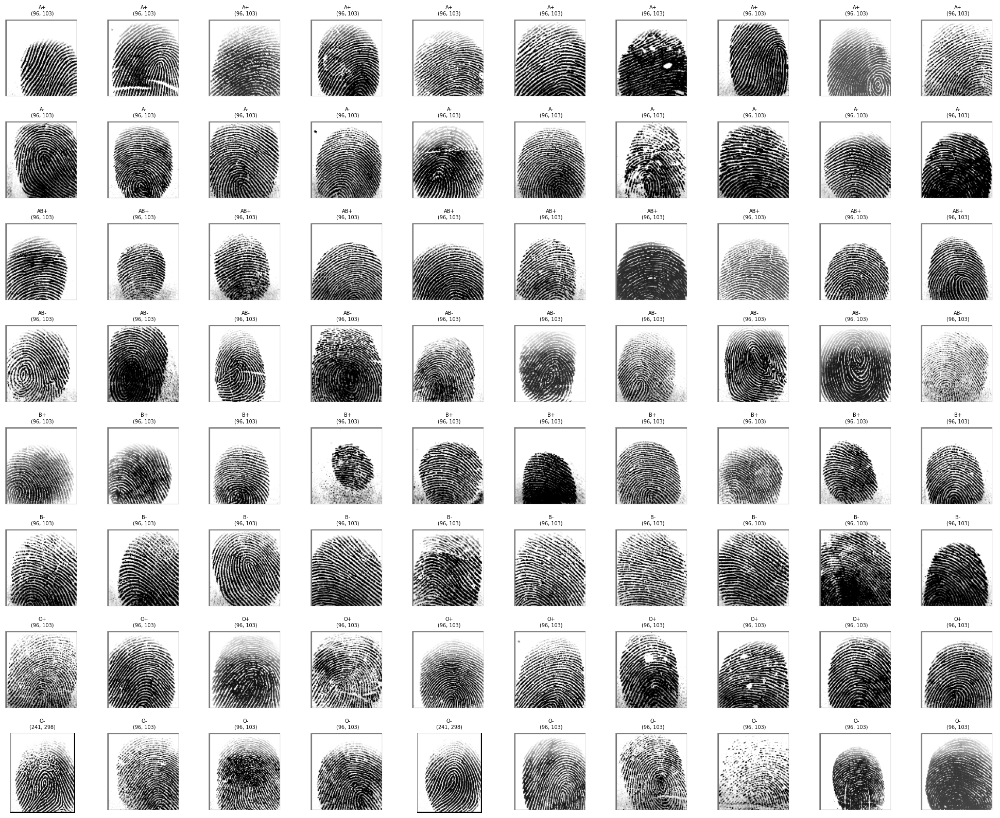

Saved: /content/drive/MyDrive/ML Fingerprint BloodGroup Project/outputs/phase1_samples.png


In [ ]:
# ============================================================
# PHASE 1 — Exploration (read-only). Paste FULL stdout back.
# ============================================================
import os, re, statistics
from pathlib import Path
from collections import Counter, defaultdict
import matplotlib.pyplot as plt
from PIL import Image

DATA_ROOT = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project/kaggle_raw_dataset')
assert DATA_ROOT.exists(), f"Not found: {DATA_ROOT}"

IMG_EXT = {'.bmp','.jpg','.jpeg','.png','.tif','.tiff','.pgm'}
KNOWN   = {'A+','A-','B+','B-','AB+','AB-','O+','O-'}

def list_images(d):
    return [p for p in d.rglob('*') if p.is_file() and p.suffix.lower() in IMG_EXT]

# ---- 1. Tree (depth 3) ----
print("=== TREE (depth 3) ===")
for root, dirs, files in os.walk(DATA_ROOT):
    rel   = Path(root).relative_to(DATA_ROOT)
    depth = len(rel.parts)
    if depth > 2:
        dirs[:] = []; continue
    indent = '  ' * depth
    print(f"{indent}{Path(root).name}/  ({len(files)} files, {len(dirs)} dirs)")

# ---- 2. Detect class folders ----
all_dirs    = [p for p in DATA_ROOT.rglob('*') if p.is_dir()]
class_dirs  = sorted([p for p in all_dirs if p.name.upper() in {k.upper() for k in KNOWN}],
                     key=lambda p: p.name)
print(f"\n=== CLASS FOLDERS DETECTED: {len(class_dirs)} ===")
for cd in class_dirs:
    print("   ", cd.relative_to(DATA_ROOT))

# ---- 3. Per-class counts + extension distribution ----
counts, exts_by_class = {}, {}
for cd in class_dirs:
    imgs = list_images(cd)
    counts[cd.name] = len(imgs)
    exts_by_class[cd.name] = Counter(p.suffix for p in imgs)

print("\n=== PER-CLASS COUNTS ===")
for c in sorted(counts):
    print(f"   {c:<4} n={counts[c]:<5} exts={dict(exts_by_class[c])}")

total = sum(counts.values())
if total:
    maj = max(counts.values())
    print(f"\n   TOTAL={total}   majority-baseline={maj/total:.4f} ({maj}/{total})")

# ---- 4. Stray non-image files ----
strays = [p for p in DATA_ROOT.rglob('*')
          if p.is_file() and p.suffix.lower() not in IMG_EXT]
print(f"\n=== STRAY (non-image) FILES: {len(strays)} ===")
for p in strays[:20]:
    print("   ", p.relative_to(DATA_ROOT))

# ---- 5. Filename pattern analysis (EMPIRICAL — no interpretation) ----
# Observed in zip listing: 'cluster_<N>_<M>.BMP'. We do not assume what N means.
# This section just reports facts.

cluster_re = re.compile(r'^(?P<prefix>cluster)_(?P<cluster_id>\d+)_(?P<rest>\d+)',
                        re.IGNORECASE)

print("\n=== FILENAME PATTERN ANALYSIS (empirical only) ===")
print("Sample of first 5 filenames per class:")
for cd in class_dirs:
    imgs = sorted(list_images(cd))[:5]
    print(f"   {cd.name}: {[p.name for p in imgs]}")

cluster_ids_by_class       = defaultdict(set)             # class -> set(cluster_id)
imgs_per_cluster_by_class  = defaultdict(Counter)         # class -> {cluster_id: count}
nonmatching = []

for cd in class_dirs:
    for p in list_images(cd):
        m = cluster_re.match(p.stem)
        if not m:
            nonmatching.append((cd.name, p.name)); continue
        cid = int(m.group('cluster_id'))
        cluster_ids_by_class[cd.name].add(cid)
        imgs_per_cluster_by_class[cd.name][cid] += 1

print("\nDistinct cluster IDs per class:")
for c in sorted(cluster_ids_by_class):
    ids = cluster_ids_by_class[c]
    print(f"   {c:<4} n_distinct={len(ids):<4} min_id={min(ids)}  max_id={max(ids)}")

if nonmatching:
    print(f"\nFilenames NOT matching 'cluster_<N>_<M>': {len(nonmatching)}")
    for c, n in nonmatching[:10]: print(f"   {c}/{n}")

# Cross-class overlap: does the SAME cluster id appear in >1 class?
cluster_to_classes = defaultdict(set)
for c, ids in cluster_ids_by_class.items():
    for cid in ids:
        cluster_to_classes[cid].add(c)

overlap = {cid: clss for cid, clss in cluster_to_classes.items() if len(clss) > 1}
print(f"\nTotal distinct cluster IDs (across all classes): {len(cluster_to_classes)}")
print(f"Sum of per-class distinct counts:              {sum(len(v) for v in cluster_ids_by_class.values())}")
print(f"Cluster IDs appearing in >1 class:             {len(overlap)}")
if overlap:
    for cid in sorted(overlap)[:10]:
        print(f"   cluster_{cid}: classes={sorted(overlap[cid])}")

# Images per cluster (global)
imgs_per_cluster_global = Counter()
for c, ctr in imgs_per_cluster_by_class.items():
    for cid, n in ctr.items():
        imgs_per_cluster_global[cid] += n

cluster_sizes = list(imgs_per_cluster_global.values())
if cluster_sizes:
    print(f"\nImages per cluster (global):")
    print(f"   n_clusters={len(cluster_sizes)}  min={min(cluster_sizes)}  "
          f"max={max(cluster_sizes)}  mean={statistics.mean(cluster_sizes):.2f}  "
          f"median={statistics.median(cluster_sizes):.1f}")
    print(f"   top-10 size distribution: {Counter(cluster_sizes).most_common(10)}")

# ---- 6. Sample grid: 10 per class ----
print("\n=== SAMPLE GRID ===")
if class_dirs:
    classes = sorted(counts.keys())
    fig, axes = plt.subplots(len(classes), 10, figsize=(20, 2*len(classes)))
    for i, cls in enumerate(classes):
        imgs = sorted([p for cd in class_dirs if cd.name == cls
                       for p in list_images(cd)])[:10]
        for j in range(10):
            ax = axes[i][j]; ax.axis('off')
            if j < len(imgs):
                try:
                    im = Image.open(imgs[j])
                    ax.imshow(im, cmap='gray' if im.mode == 'L' else None)
                    ax.set_title(f"{cls}\n{im.size}", fontsize=7)
                except Exception:
                    ax.set_title(f"{cls}\nERR", fontsize=7)
    out_png = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project/outputs/phase1_samples.png')
    plt.tight_layout(); plt.savefig(out_png, dpi=80); plt.show()
    print("Saved:", out_png)

In [ ]:
# ============================================================
# PHASE 2B — manifest (properties + MD5 + phash) + phash histogram
# ============================================================
import hashlib, re, time
from concurrent.futures import ThreadPoolExecutor, as_completed
from collections import Counter
import numpy as np
import pandas as pd
from PIL import Image
from imagehash import phash

PROJECT_ROOT  = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
OUTPUTS_DIR   = PROJECT_ROOT / 'outputs'
OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)
DATASETS_ROOT = Path('/content/data/raw/datasets')
MANIFEST_RAW  = OUTPUTS_DIR / 'manifest_raw.csv'

IMG_EXT = {'.bmp','.jpg','.jpeg','.png','.tif','.tiff','.pgm'}

def md5_file(path, chunk=1<<16):
    h = hashlib.md5()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(chunk), b''):
            h.update(block)
    return h.hexdigest()

def audit_one(path):
    rel = path.relative_to(DATASETS_ROOT)
    rec = {
        'path':     str(rel).replace('\\','/'),
        'label':    rel.parts[0],
        'filename': path.name,
        'filesize': path.stat().st_size,
        'width': None, 'height': None, 'mode': None, 'format': None,
        'corrupt': False, 'corrupt_error': None,
        'md5': None, 'phash': None,
    }
    try:
        with Image.open(path) as im:
            im.load()                                   # forces pixel load
            rec['width'], rec['height'] = im.size
            rec['mode'],  rec['format'] = im.mode, im.format
    except Exception as e:
        rec['corrupt'] = True
        rec['corrupt_error'] = repr(e)[:200]
    try: rec['md5'] = md5_file(path)
    except Exception: pass
    try:
        with Image.open(path) as im:
            rec['phash'] = str(phash(im.convert('L')))   # 64-bit perceptual hash, 16 hex chars
    except Exception: pass
    return rec

# ---- enumerate ----
all_paths = [p for p in DATASETS_ROOT.rglob('*')
             if p.is_file() and p.suffix.lower() in IMG_EXT]
print(f"Total images: {len(all_paths)}")

# ---- parallel audit ----
t0 = time.time()
records = []
with ThreadPoolExecutor(max_workers=8) as ex:
    futs = {ex.submit(audit_one, p): p for p in all_paths}
    for i, fut in enumerate(as_completed(futs), 1):
        records.append(fut.result())
        if i % 500 == 0:
            print(f"  {i}/{len(all_paths)}  elapsed={time.time()-t0:.0f}s")
df = pd.DataFrame(records)
print(f"Audit done in {time.time()-t0:.0f}s")

# ---- sanity summary ----
print(f"\nCorrupt files: {int(df['corrupt'].sum())}")
for _, r in df[df['corrupt']].iterrows():
    print(f"   {r['path']}  ->  {r['corrupt_error']}")
print("\nMode distribution:  ", df['mode'].value_counts(dropna=False).to_dict())
print("Format distribution:", df['format'].value_counts(dropna=False).to_dict())

sizes = df.groupby(['width','height']).size().sort_values(ascending=False)
print("\nTop image sizes:")
for (w,h), n in sizes.head(10).items():
    print(f"   {w} x {h}  ->  {n}")

# ---- save intermediate (still has phash, no clusters yet) ----
df.to_csv(MANIFEST_RAW, index=False)
print(f"\nSaved intermediate: {MANIFEST_RAW}")

# ---- phash pairwise distance histogram ----
valid_phashes = df.loc[df['phash'].notna(), 'phash'].tolist()
print(f"\nImages with valid phash: {len(valid_phashes)}")
arr = np.array([int(ph, 16) for ph in valid_phashes], dtype=np.uint64)
N = len(arr)
print(f"Computing {N*(N-1)//2:,} pairwise Hamming distances...")

lut = np.array([bin(i).count('1') for i in range(256)], dtype=np.uint8)
hist = np.zeros(65, dtype=np.int64)
t0 = time.time()
for i in range(N):
    xor = arr[i+1:] ^ arr[i]
    if xor.size == 0: continue
    xor_bytes = xor.view(np.uint8).reshape(-1, 8)
    dists = lut[xor_bytes].sum(axis=1)
    hist += np.bincount(dists, minlength=65)
print(f"Histogram done in {time.time()-t0:.1f}s")

# save + print
with open(OUTPUTS_DIR / 'phash_hist.txt', 'w') as f:
    for d in range(65):
        if hist[d] > 0:
            f.write(f"{d}\t{int(hist[d])}\n")

print("\n=== PHASH HAMMING DISTANCE HISTOGRAM (dist 0..20) ===")
print(f"{'dist':>4}   {'pairs':>14}   {'cum pairs':>14}")
cum = 0
for d in range(0, 21):
    cum += int(hist[d])
    if hist[d] > 0 or d <= 12:
        print(f"{d:>4}   {int(hist[d]):>14,}   {cum:>14,}")
print(f"\nTotal pairs: {int(hist.sum()):,}")
print("Interpretation: random 64-bit hashes peak near dist~32.")
print("               A spike at LOW distance (0..10) = near-duplicates.")
print("               Threshold = the distance we'll treat as 'near-dup'.")
print("\nSaved histogram: outputs/phash_hist.txt")
print("\n*** STOP HERE. Do NOT run Phase 2C yet. ***")
print("*** Paste the histogram block back so we can pick the threshold together. ***")

Total images: 5837
  500/5837  elapsed=2s
  1000/5837  elapsed=2s
  1500/5837  elapsed=3s
  2000/5837  elapsed=4s
  2500/5837  elapsed=4s
  3000/5837  elapsed=5s
  3500/5837  elapsed=6s
  4000/5837  elapsed=6s
  4500/5837  elapsed=7s
  5000/5837  elapsed=8s
  5500/5837  elapsed=8s
Audit done in 9s

Corrupt files: 0

Mode distribution:   {'RGBA': 5793, 'RGB': 44}
Format distribution: {'BMP': 5837}

Top image sizes:
   96 x 103  ->  5793
   241 x 298  ->  44

Saved intermediate: /content/drive/MyDrive/ML Fingerprint BloodGroup Project/outputs/manifest_raw.csv

Images with valid phash: 5837
Computing 17,032,366 pairwise Hamming distances...


TypeError: Cannot cast array data from dtype('uint64') to dtype('int64') according to the rule 'safe'

In [ ]:
# ============================================================
# PHASE 2B-FIX — diagnostic on mode/size + corrected histogram
# (reads manifest_raw.csv; does NOT re-audit)
# ============================================================
import numpy as np, pandas as pd
from pathlib import Path

PROJECT_ROOT = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
OUTPUTS_DIR  = PROJECT_ROOT / 'outputs'
df = pd.read_csv(OUTPUTS_DIR / 'manifest_raw.csv')

# ---------- 1. CROSS-TABS: mode × label, size × label ----------
print("=== MODE × LABEL ===")
print(pd.crosstab(df['label'], df['mode']))

print("\n=== SIZE × LABEL ===")
df['size'] = df['width'].astype(str) + 'x' + df['height'].astype(str)
print(pd.crosstab(df['label'], df['size']))

# ---------- 2. The 44 RGB images: where, and are they duplicates? ----------
rgb = df[df['mode'] == 'RGB'].copy()
print(f"\n=== THE {len(rgb)} RGB IMAGES ===")
print("Per-class:", rgb['label'].value_counts().to_dict())
print("Distinct MD5s :", rgb['md5'].nunique(), "of", len(rgb))
print("Distinct phashes:", rgb['phash'].nunique(), "of", len(rgb))
print("All filenames:")
for p in rgb['path'].tolist():
    print("   ", p)

# ---------- 3. Are the 44 RGB near-dups of any RGBA image? ----------
rgba  = df[df['mode'] == 'RGBA']
lut   = np.array([bin(i).count('1') for i in range(256)], dtype=np.uint8)
rgb_p  = np.array([int(p, 16) for p in rgb['phash'].dropna()], dtype=np.uint64)
rgba_p = np.array([int(p, 16) for p in rgba['phash'].dropna()], dtype=np.uint64)

print("\n=== Each RGB image -> closest RGBA image (phash distance) ===")
rows = []
for i in range(len(rgb_p)):
    xor = rgba_p ^ rgb_p[i]
    d = lut[xor.view(np.uint8).reshape(-1, 8)].sum(axis=1).astype(np.int64)
    j = int(np.argmin(d))
    rows.append((rgb.iloc[i]['path'], int(d[j]), rgba.iloc[j]['path']))
for path, dist, closest in rows:
    print(f"   {path:<35}  min_dist={dist:<3}  closest_rgba={closest}")

# ---------- 4. Corrected histogram (the fix) ----------
print("\n=== PHASH HAMMING DISTANCE HISTOGRAM (all 5837) ===")
all_p = np.array([int(p, 16) for p in df['phash'].dropna()], dtype=np.uint64)
N = len(all_p)
hist = np.zeros(65, dtype=np.int64)
for i in range(N):
    xor = all_p[i+1:] ^ all_p[i]
    if xor.size == 0: continue
    d = lut[xor.view(np.uint8).reshape(-1, 8)].sum(axis=1).astype(np.int64)  # <-- FIX
    hist += np.bincount(d, minlength=65)

print(f"{'dist':>4}   {'pairs':>14}   {'cum pairs':>14}")
cum = 0
for d in range(0, 25):
    cum += int(hist[d])
    print(f"{d:>4}   {int(hist[d]):>14,}   {cum:>14,}")
print(f"Total pairs: {int(hist.sum()):,}")

with open(OUTPUTS_DIR / 'phash_hist.txt', 'w') as f:
    for d in range(65):
        if hist[d] > 0:
            f.write(f"{d}\t{int(hist[d])}\n")
print("\nSaved histogram:", OUTPUTS_DIR / 'phash_hist.txt')

=== MODE × LABEL ===
mode   RGB  RGBA
label           
A+       2   400
A-       8  1001
AB+      3   705
AB-      6   755
B+       4   648
B-       2   739
O+       9   843
O-      10   702

=== SIZE × LABEL ===
size   241x298  96x103
label                 
A+           2     400
A-           8    1001
AB+          3     705
AB-          6     755
B+           4     648
B-           2     739
O+           9     843
O-          10     702

=== THE 44 RGB IMAGES ===
Per-class: {'O-': 10, 'O+': 9, 'A-': 8, 'AB-': 6, 'B+': 4, 'AB+': 3, 'B-': 2, 'A+': 2}
Distinct MD5s : 41 of 44
Distinct phashes: 41 of 44
All filenames:
    O-/cluster_7_2.BMP
    O-/cluster_7_697.BMP
    O-/cluster_7_1040.BMP
    O-/cluster_7_4929.BMP
    O-/cluster_7_4793.BMP
    O-/cluster_7_3340.BMP
    O-/cluster_7_1002.BMP
    O-/cluster_7_5447.BMP
    O-/cluster_7_519.BMP
    O-/cluster_7_2105.BMP
    A+/cluster_0_3931.BMP
    A+/cluster_0_4998.BMP
    B-/cluster_3_4966.BMP
    B-/cluster_3_3233.BMP
    AB+/cluster_4

In [ ]:
# ============================================================
# PHASE 2B-2 — cluster size distribution at multiple phash thresholds
# (no re-audit; reads manifest_raw.csv)
# ============================================================
import numpy as np, pandas as pd
from collections import Counter, defaultdict
from pathlib import Path

PROJECT_ROOT = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
OUTPUTS_DIR  = PROJECT_ROOT / 'outputs'
df = pd.read_csv(OUTPUTS_DIR / 'manifest_raw.csv')
df['idx'] = range(len(df))

phashes = df['phash'].tolist()
N = len(phashes)
arr = np.array([int(p, 16) for p in phashes], dtype=np.uint64)
lut = np.array([bin(i).count('1') for i in range(256)], dtype=np.uint8)

# collect all pairs with dist <= 10 (edges only)
MAXD = 10
edges = []   # list of (i, j, d)
for i in range(N):
    xor = arr[i+1:] ^ arr[i]
    if xor.size == 0: continue
    d = lut[xor.view(np.uint8).reshape(-1, 8)].sum(axis=1).astype(np.int64)
    js = np.where(d <= MAXD)[0]
    for jj in js:
        edges.append((i, i+1+int(jj), int(d[jj])))
print(f"Total edges with dist<={MAXD}: {len(edges):,}")

# ---- union-find ----
def uf_cluster(n, edge_list):
    parent = list(range(n))
    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x
    def union(a,b):
        ra,rb = find(a),find(b)
        if ra!=rb: parent[rb]=ra
    for a,b,_ in edge_list: union(a,b)
    return [find(i) for i in range(n)]

# ---- test thresholds ----
def size_report(cluster_assignments, label):
    sizes = Counter(cluster_assignments)
    size_dist = Counter(sizes.values())
    multi = {c:s for c,s in sizes.items() if s > 1}
    total_images_in_multi = sum(multi.values())
    n_multi = len(multi)
    largest = sizes.most_common(3)
    print(f"\n=== THRESHOLD dist<={label} ===")
    print(f"  clusters total:        {len(sizes):,}")
    print(f"  singleton clusters:    {size_dist[1]:,}")
    print(f"  multi-image clusters:  {n_multi:,}")
    print(f"  images in multi:       {total_images_in_multi:,}  "
          f"({total_images_in_multi/N*100:.1f}% of data)")
    print(f"  largest 3 cluster sizes: {[s for _,s in largest]}")
    print(f"  size distribution (size:count, top-10): "
          f"{sorted(size_dist.items())[:10]}")

    # worst case: any cluster that spans >1 class? (would be cross-class leakage)
    # check only multi-image ones to keep it cheap
    cl_to_labels = defaultdict(set)
    for idx, cl in enumerate(cluster_assignments):
        cl_to_labels[cl].add(df.iloc[idx]['label'])
    cross = {cl: lbls for cl, lbls in cl_to_labels.items()
             if len(lbls) > 1 and sizes[cl] > 1}
    print(f"  clusters spanning >1 class: {len(cross)}")
    for cl in sorted(cross, key=lambda c: -sizes[c])[:5]:
        print(f"     cluster size={sizes[cl]}  classes={sorted(cross[cl])}")

for t in [4, 6, 8]:
    sub = [(a,b,d) for a,b,d in edges if d <= t]
    assign = uf_cluster(N, sub)
    size_report(assign, t)

# ---- always report: exact-MD5 duplicate groups (independent of phash) ----
md5_groups = df.groupby('md5').size()
md5_multi = md5_groups[md5_groups > 1]
print(f"\n=== EXACT-DUP GROUPS (MD5) ===")
print(f"  distinct MD5s:            {len(md5_groups):,}")
print(f"  MD5s with >1 copy:        {len(md5_multi):,}")
print(f"  images in exact-dup sets: {int(md5_multi.sum()):,}")

# any MD5 present in >1 class? -> label conflict
md5_classes = df.groupby('md5')['label'].nunique()
conflicts = md5_classes[md5_classes > 1]
print(f"  MD5s present in >1 class: {len(conflicts):,}  <-- label conflicts")
for h in conflicts.index[:10]:
    rows = df[df['md5'] == h][['path','label']]
    print(f"     md5={h[:12]}... -> {rows.values.tolist()}")

Total edges with dist<=10: 122,752

=== THRESHOLD dist<=4 ===
  clusters total:        5,214
  singleton clusters:    5,021
  multi-image clusters:  193
  images in multi:       816  (14.0% of data)
  largest 3 cluster sizes: [91, 88, 56]
  size distribution (size:count, top-10): [(1, 5021), (2, 129), (3, 31), (4, 9), (5, 7), (6, 3), (7, 3), (10, 2), (11, 2), (12, 1)]
  clusters spanning >1 class: 124
     cluster size=91  classes=['A-', 'AB+', 'AB-', 'B+', 'B-', 'O+']
     cluster size=88  classes=['A+', 'A-', 'AB+', 'B+', 'B-', 'O+', 'O-']
     cluster size=56  classes=['A+', 'A-', 'AB+', 'B-', 'O+', 'O-']
     cluster size=28  classes=['A+', 'AB+', 'B+', 'O-']
     cluster size=23  classes=['A-', 'B+', 'B-', 'O+']

=== THRESHOLD dist<=6 ===
  clusters total:        3,442
  singleton clusters:    3,271
  multi-image clusters:  171
  images in multi:       2,566  (44.0% of data)
  largest 3 cluster sizes: [2154, 10, 8]
  size distribution (size:count, top-10): [(1, 3271), (2, 127), (3

In [ ]:
# ============================================================
# PHASE 2 — SUSPICION TESTS A & B (read-only diagnostics)
# ============================================================
import numpy as np, pandas as pd
from pathlib import Path

PROJECT_ROOT = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
OUTPUTS_DIR  = PROJECT_ROOT / 'outputs'
df = pd.read_csv(OUTPUTS_DIR / 'manifest_raw.csv').reset_index(drop=True)

assert df['phash'].notna().all(), "Some images have no phash — cannot proceed"
N = len(df)
print(f"N = {N}")

# --- factorize labels (fast integer ops) ---
lab_codes, lab_uniques = pd.factorize(df['label'])
print(f"Label encoding: {dict(enumerate(lab_uniques))}")

# --- analytical chance same-label rate ---
counts = df['label'].value_counts()
baseline = ((counts / counts.sum()) ** 2).sum()
print(f"\nChance same-label rate (sum of squared proportions): {baseline:.4f}")
print(f"  (majority-class accuracy for comparison: {counts.max()/counts.sum():.4f} — different concept)")

# --- phash to uint64 array + precompute per-row distances ---
phash_arr = np.array([int(p, 16) for p in df['phash']], dtype=np.uint64)
lut = np.array([bin(i).count('1') for i in range(256)], dtype=np.uint8)

print("\nPrecomputing pairwise phash distances (row by row)...")
d_rows = []
for i in range(N):
    xor = phash_arr[i+1:] ^ phash_arr[i]
    if xor.size == 0:
        d_rows.append(np.empty(0, dtype=np.int64)); continue
    d_rows.append(lut[xor.view(np.uint8).reshape(-1, 8)]
                  .sum(axis=1).astype(np.int64))
print(f"  {N} rows computed")

# ============================================================
# TEST A — label-error detection + eyeball candidates
# ============================================================
print("\n" + "="*72)
print("TEST A — LABEL ERRORS")
print("="*72)

# A1. same MD5, different label
print("\n--- A1. Same MD5, different label (STRONGEST error signal) ---")
md5_labels = df.groupby('md5')['label'].agg(lambda s: tuple(sorted(set(s))))
md5_conf   = md5_labels[md5_labels.map(len) > 1]
print(f"Conflicts: {len(md5_conf)}")
for h, labs in md5_conf.items():
    print(f"  md5={h[:12]}…  labels={labs}")
    for _, r in df[df['md5'] == h][['path','label']].iterrows():
        print(f"     {r['label']:>4}  {r['path']}")

# A2 + A3. cross-label pairs at low phash distance
print("\n--- A2/A3. Cross-label pairs at low phash distance ---")
low_pairs = []   # (i, j, d)
for i in range(N):
    d_row = d_rows[i]
    if d_row.size == 0: continue
    jj = np.where(d_row <= 6)[0]
    for jj_e in jj:
        low_pairs.append((i, i+1+int(jj_e), int(d_row[jj_e])))

def report_cross_label(pairs, min_d, max_d):
    sub = [(i,j,d) for i,j,d in pairs
           if min_d <= d <= max_d and lab_codes[i] != lab_codes[j]]
    print(f"\n  dist in [{min_d},{max_d}]: {len(sub)} cross-label pairs")
    by_d = {}
    for i,j,d in sub:
        by_d.setdefault(d, []).append((i,j))
    for d in sorted(by_d):
        print(f"    dist={d}: {len(by_d[d])} pairs (showing up to 5)")
        for i, j in by_d[d][:5]:
            print(f"       {df.iloc[i]['label']:>4}/{df.iloc[i]['path']:<30}"
                  f"  <->  {df.iloc[j]['label']:>4}/{df.iloc[j]['path']:<30}")
    return sub

cross0   = report_cross_label(low_pairs, 0, 0)
cross2_6 = report_cross_label(low_pairs, 2, 6)

# ============================================================
# TEST B — same-label rate per distance + permutation null band
# ============================================================
print("\n" + "="*72)
print("TEST B — SAME-LABEL RATE PER DISTANCE (permutation null)")
print("="*72)

def compute_rates(codes):
    total_per_dist = np.zeros(65, dtype=np.int64)
    same_per_dist  = np.zeros(65, dtype=np.int64)
    for i in range(N):
        d_row = d_rows[i]
        if d_row.size == 0: continue
        same_row = (codes[i+1:] == codes[i])
        total_per_dist += np.bincount(d_row, minlength=65)
        same_per_dist  += np.bincount(d_row[same_row], minlength=65)
    return same_per_dist, total_per_dist

same_real, total = compute_rates(lab_codes)
rate_real = np.where(total > 0, same_real / np.maximum(total, 1), np.nan)

N_PERM = 10
print(f"\nRunning {N_PERM} label permutations for null band...")
perm_rates = np.zeros((N_PERM, 65))
perm_codes = lab_codes.copy()
for p in range(N_PERM):
    np.random.shuffle(perm_codes)
    sp, _ = compute_rates(perm_codes)
    perm_rates[p] = np.where(total > 0, sp / np.maximum(total, 1), np.nan)
    print(f"  perm {p+1}/{N_PERM}")

null_mean = np.nanmean(perm_rates, axis=0)
null_min  = np.nanmin(perm_rates,  axis=0)
null_max  = np.nanmax(perm_rates,  axis=0)

print(f"\n{'dist':>4} | {'pairs':>9} | {'real%':>7} | "
      f"{'null mean%':>10} | {'null [min,max]%':>17} | {'effect':>7} | {'outside?':>8}")
print("-" * 92)
for d in range(0, 25):
    if total[d] == 0: continue
    r = rate_real[d]; nm = null_mean[d]
    effect = r / baseline if baseline > 0 else np.nan
    outside = "YES" if (r < null_min[d] or r > null_max[d]) else "no"
    print(f"{d:>4} | {int(total[d]):>9,} | {r*100:>6.2f}% | "
          f"{nm*100:>9.2f}% | "
          f"[{null_min[d]*100:>5.2f}, {null_max[d]*100:>5.2f}] | "
          f"{effect:>6.2f}x | {outside:>8}")

print(f"\nAnalytical baseline: {baseline*100:.2f}%")
print("Effect = real rate / baseline  (1.0x = no signal; read effect, not p)")

# save table for later
out = OUTPUTS_DIR / 'test_B_same_label_rates.csv'
pd.DataFrame({
    'dist': np.arange(65),
    'pairs': total,
    'real_rate': rate_real,
    'null_mean': null_mean,
    'null_min': null_min,
    'null_max': null_max,
}).to_csv(out, index=False)
print(f"\nSaved: {out}")

##  SESSION STARTUP

In [ ]:
# ============================================================
# SESSION STARTUP — paste as the FIRST cell of every new Colab session
# Does: mount Drive, install deps, seed, verify paths, unzip raw data to /content.
# Safe to re-run (idempotent).
# ============================================================
import os, random, csv, subprocess
from pathlib import Path

SEED = 42

# --- 1. Mount Drive ---
from google.colab import drive
drive.mount('/content/drive')

# --- 2. Install deps (add future deps to this list) ---
subprocess.run(['pip', 'install', '-q', 'imagehash'], check=True)

# --- 3. Paths ---
PROJECT_ROOT  = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
DATA_ZIP      = PROJECT_ROOT / 'kaggle_raw_dataset.zip'      # raw dataset zip on Drive
DATA_RAW_ROOT = PROJECT_ROOT / 'kaggle_raw_dataset'          # unzipped copy on Drive (backup)
WORK_RAW      = Path('/content/data/raw')                    # fast local working copy
DATASETS_ROOT = WORK_RAW / 'datasets'
SPLITS_DIR    = PROJECT_ROOT / 'splits'
OUTPUTS_DIR   = PROJECT_ROOT / 'outputs'
NOTEBOOKS_DIR = PROJECT_ROOT / 'notebooks'

for p in [Path('/content/data'), SPLITS_DIR, OUTPUTS_DIR, NOTEBOOKS_DIR]:
    p.mkdir(parents=True, exist_ok=True)

# --- 4. Seed ---
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
import numpy as np; np.random.seed(SEED)
import torch
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# --- 5. Run log (create if missing) ---
RUN_LOG = OUTPUTS_DIR / 'run_log.csv'
if not RUN_LOG.exists():
    with open(RUN_LOG, 'w', newline='') as f:
        csv.writer(f).writerow([
            'run_id','timestamp','phase','model','backbone','split_type',
            'lr','epochs','batch_size','augmentations',
            'val_accuracy','val_macro_f1','test_accuracy','notes'
        ])

# --- 6. Unzip raw data to /content (fast local disk) ---
EXPECTED_FILES = 5837
def count_files(root):
    return sum(1 for p in root.rglob('*') if p.is_file()) if root.exists() else 0

if count_files(DATASETS_ROOT) == EXPECTED_FILES:
    print("Raw data already present in this session — skipping unzip.")
else:
    print("Unzipping raw dataset to /content/data/raw ...")
    WORK_RAW.mkdir(parents=True, exist_ok=True)
    r = subprocess.run(['unzip', '-q', '-o', str(DATA_ZIP), '-d', str(WORK_RAW)],
                       capture_output=True, text=True)
    if r.returncode != 0:
        raise RuntimeError(f"Unzip failed: {r.stderr[:500]}")

# --- 7. Verify ---
n_files = count_files(DATASETS_ROOT)
class_dirs = sorted([p.name for p in DATASETS_ROOT.iterdir() if p.is_dir()]) \
             if DATASETS_ROOT.exists() else []
print("=" * 60)
print(f"CUDA available:         {torch.cuda.is_available()}")
print(f"PROJECT_ROOT exists:    {PROJECT_ROOT.exists()}")
print(f"Raw zip exists:         {DATA_ZIP.exists()}")
print(f"Files under datasets/:  {n_files}   (expected {EXPECTED_FILES})")
print(f"Class dirs:             {class_dirs}")
print(f"Outputs dir:            {OUTPUTS_DIR}")
print("=" * 60)
if n_files != EXPECTED_FILES:
    print("⚠️  File count mismatch — check the zip before proceeding.")

Mounted at /content/drive
Unzipping raw dataset to /content/data/raw ...
CUDA available:         True
PROJECT_ROOT exists:    True
Raw zip exists:         True
Files under datasets/:  5837   (expected 5837)
Class dirs:             ['A+', 'A-', 'AB+', 'AB-', 'B+', 'B-', 'O+', 'O-']
Outputs dir:            /content/drive/MyDrive/ML Fingerprint BloodGroup Project/outputs



### **extra **# for new account


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
P = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')

print("Folder exists:", P.exists())
print("Checkpoints folder exists:", (P/'outputs'/'checkpoints').exists())
print("ResNet checkpoints:", [f.name for f in (P/'outputs'/'checkpoints').glob('resnet50*')])
print("EfficientNet checkpoints:", [f.name for f in (P/'outputs'/'checkpoints').glob('efficientnet*')])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Folder exists: True
Checkpoints folder exists: False
ResNet checkpoints: []
EfficientNet checkpoints: []


In [ ]:
# ===== STEP 1: diagnose what's actually visible on Drive =====
from pathlib import Path

P = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')

print("--- target path ---")
print("exists:", P.exists())
print("is_dir:", P.is_dir())
print("is_file:", P.is_file())

if P.exists() and P.is_dir():
    print("\n--- contents of P ---")
    for c in P.iterdir():
        try:
            size = f"{c.stat().st_size} B" if c.is_file() else "(dir)"
        except Exception as e:
            size = f"(stat failed: {e})"
        print(f"  {c.name!r}  is_dir={c.is_dir()}  size={size}")

print("\n--- everything at MyDrive root ---")
root = Path('/content/drive/MyDrive')
for c in sorted(root.iterdir()):
    print(f"  {c.name!r}  is_dir={c.is_dir()}")

print("\n--- anything matching 'Fingerprint' anywhere at MyDrive root ---")
for c in root.iterdir():
    if 'Fingerprint' in c.name or 'fingerprint' in c.name:
        print(f"  {c.name!r}  is_dir={c.is_dir()}")

--- target path ---
exists: True
is_dir: True
is_file: False

--- contents of P ---
  'splits'  is_dir=True  size=(dir)
  'outputs'  is_dir=True  size=(dir)
  'notebooks'  is_dir=True  size=(dir)

--- everything at MyDrive root ---
  'ML Fingerprint BloodGroup Project'  is_dir=True

--- anything matching 'Fingerprint' anywhere at MyDrive root ---
  'ML Fingerprint BloodGroup Project'  is_dir=True


### SESSION STARTUP ends -- suspicion test starts.

In [ ]:
# ============================================================
# PHASE 2 — SUSPICION TESTS A & B (read-only diagnostics)
# ============================================================
import numpy as np, pandas as pd
from pathlib import Path

PROJECT_ROOT = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
OUTPUTS_DIR  = PROJECT_ROOT / 'outputs'
df = pd.read_csv(OUTPUTS_DIR / 'manifest_raw.csv').reset_index(drop=True)

assert df['phash'].notna().all(), "Some images have no phash — cannot proceed"
N = len(df)
print(f"N = {N}")

# --- factorize labels (fast integer ops) ---
lab_codes, lab_uniques = pd.factorize(df['label'])
print(f"Label encoding: {dict(enumerate(lab_uniques))}")

# --- analytical chance same-label rate ---
counts = df['label'].value_counts()
baseline = ((counts / counts.sum()) ** 2).sum()
print(f"\nChance same-label rate (sum of squared proportions): {baseline:.4f}")
print(f"  (majority-class accuracy for comparison: {counts.max()/counts.sum():.4f} — different concept)")

# --- phash to uint64 array + precompute per-row distances ---
phash_arr = np.array([int(p, 16) for p in df['phash']], dtype=np.uint64)
lut = np.array([bin(i).count('1') for i in range(256)], dtype=np.uint8)

print("\nPrecomputing pairwise phash distances (row by row)...")
d_rows = []
for i in range(N):
    xor = phash_arr[i+1:] ^ phash_arr[i]
    if xor.size == 0:
        d_rows.append(np.empty(0, dtype=np.int64)); continue
    d_rows.append(lut[xor.view(np.uint8).reshape(-1, 8)]
                  .sum(axis=1).astype(np.int64))
print(f"  {N} rows computed")

# ============================================================
# TEST A — label-error detection + eyeball candidates
# ============================================================
print("\n" + "="*72)
print("TEST A — LABEL ERRORS")
print("="*72)

# A1. same MD5, different label
print("\n--- A1. Same MD5, different label (STRONGEST error signal) ---")
md5_labels = df.groupby('md5')['label'].agg(lambda s: tuple(sorted(set(s))))
md5_conf   = md5_labels[md5_labels.map(len) > 1]
print(f"Conflicts: {len(md5_conf)}")
for h, labs in md5_conf.items():
    print(f"  md5={h[:12]}…  labels={labs}")
    for _, r in df[df['md5'] == h][['path','label']].iterrows():
        print(f"     {r['label']:>4}  {r['path']}")

# A2 + A3. cross-label pairs at low phash distance
print("\n--- A2/A3. Cross-label pairs at low phash distance ---")
low_pairs = []   # (i, j, d)
for i in range(N):
    d_row = d_rows[i]
    if d_row.size == 0: continue
    jj = np.where(d_row <= 6)[0]
    for jj_e in jj:
        low_pairs.append((i, i+1+int(jj_e), int(d_row[jj_e])))

def report_cross_label(pairs, min_d, max_d):
    sub = [(i,j,d) for i,j,d in pairs
           if min_d <= d <= max_d and lab_codes[i] != lab_codes[j]]
    print(f"\n  dist in [{min_d},{max_d}]: {len(sub)} cross-label pairs")
    by_d = {}
    for i,j,d in sub:
        by_d.setdefault(d, []).append((i,j))
    for d in sorted(by_d):
        print(f"    dist={d}: {len(by_d[d])} pairs (showing up to 5)")
        for i, j in by_d[d][:5]:
            print(f"       {df.iloc[i]['label']:>4}/{df.iloc[i]['path']:<30}"
                  f"  <->  {df.iloc[j]['label']:>4}/{df.iloc[j]['path']:<30}")
    return sub

cross0   = report_cross_label(low_pairs, 0, 0)
cross2_6 = report_cross_label(low_pairs, 2, 6)

# ============================================================
# TEST B — same-label rate per distance + permutation null band
# ============================================================
print("\n" + "="*72)
print("TEST B — SAME-LABEL RATE PER DISTANCE (permutation null)")
print("="*72)

def compute_rates(codes):
    total_per_dist = np.zeros(65, dtype=np.int64)
    same_per_dist  = np.zeros(65, dtype=np.int64)
    for i in range(N):
        d_row = d_rows[i]
        if d_row.size == 0: continue
        same_row = (codes[i+1:] == codes[i])
        total_per_dist += np.bincount(d_row, minlength=65)
        same_per_dist  += np.bincount(d_row[same_row], minlength=65)
    return same_per_dist, total_per_dist

same_real, total = compute_rates(lab_codes)
rate_real = np.where(total > 0, same_real / np.maximum(total, 1), np.nan)

N_PERM = 10
print(f"\nRunning {N_PERM} label permutations for null band...")
perm_rates = np.zeros((N_PERM, 65))
perm_codes = lab_codes.copy()
for p in range(N_PERM):
    np.random.shuffle(perm_codes)
    sp, _ = compute_rates(perm_codes)
    perm_rates[p] = np.where(total > 0, sp / np.maximum(total, 1), np.nan)
    print(f"  perm {p+1}/{N_PERM}")

null_mean = np.nanmean(perm_rates, axis=0)
null_min  = np.nanmin(perm_rates,  axis=0)
null_max  = np.nanmax(perm_rates,  axis=0)

print(f"\n{'dist':>4} | {'pairs':>9} | {'real%':>7} | "
      f"{'null mean%':>10} | {'null [min,max]%':>17} | {'effect':>7} | {'outside?':>8}")
print("-" * 92)
for d in range(0, 25):
    if total[d] == 0: continue
    r = rate_real[d]; nm = null_mean[d]
    effect = r / baseline if baseline > 0 else np.nan
    outside = "YES" if (r < null_min[d] or r > null_max[d]) else "no"
    print(f"{d:>4} | {int(total[d]):>9,} | {r*100:>6.2f}% | "
          f"{nm*100:>9.2f}% | "
          f"[{null_min[d]*100:>5.2f}, {null_max[d]*100:>5.2f}] | "
          f"{effect:>6.2f}x | {outside:>8}")

print(f"\nAnalytical baseline: {baseline*100:.2f}%")
print("Effect = real rate / baseline  (1.0x = no signal; read effect, not p)")

# save table for later
out = OUTPUTS_DIR / 'test_B_same_label_rates.csv'
pd.DataFrame({
    'dist': np.arange(65),
    'pairs': total,
    'real_rate': rate_real,
    'null_mean': null_mean,
    'null_min': null_min,
    'null_max': null_max,
}).to_csv(out, index=False)
print(f"\nSaved: {out}")

In [ ]:
# group sizes at each threshold (uses your low_pairs list)
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
for t in [0, 2, 4, 6]:
    e = [(i, j) for i, j, d in low_pairs if d <= t]
    r, c = zip(*e)
    g = coo_matrix(([1]*len(e), (r, c)), shape=(N, N))
    n, comp = connected_components(g, directed=False)
    sizes = np.bincount(comp)
    print(f"t={t}: groups>1: {(sizes>1).sum()}, largest: {sizes.max()}, "
          f"images in groups: {sizes[sizes>1].sum()}")

In [ ]:
# ============================================================
# PHASE 2 — TEST C: Is the label predictable from trivial image features?
# ============================================================
import numpy as np, pandas as pd, warnings
from pathlib import Path
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score
warnings.filterwarnings('ignore')

PROJECT_ROOT = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
DATA_ROOT    = Path('/content/data/raw/datasets')
OUTPUTS_DIR  = PROJECT_ROOT / 'outputs'
df = pd.read_csv(OUTPUTS_DIR / 'manifest_raw.csv')
y  = df['label'].values
N  = len(df)

# ---- 1. Load + featurize ----
print(f"Loading {N} images (parallel)...")
def load_one(rel_path):
    with Image.open(DATA_ROOT / rel_path) as im:
        g = im.convert('L').resize((16, 16), Image.BILINEAR)
        arr = np.array(g, dtype=np.float32) / 255.0
    mean = float(arr.mean()); std = float(arr.std())
    gy, gx = np.gradient(arr)
    edge = float(np.sqrt(gx*gx + gy*gy).mean())
    h, _ = np.histogram(arr, bins=16, range=(0,1))
    p = h / h.sum(); p = p[p > 0]
    ent = float(-(p * np.log2(p)).sum())
    return arr.flatten(), [mean, std, edge, ent]

X16   = np.zeros((N, 256), dtype=np.float32)
Xtriv = np.zeros((N, 4),   dtype=np.float32)
with ThreadPoolExecutor(max_workers=8) as ex:
    futs = {ex.submit(load_one, p): i for i, p in enumerate(df['path'])}
    for k, fut in enumerate(futs):
        a, b = fut.result()
        i = futs[fut]
        X16[i]   = a
        Xtriv[i] = b
        if (k+1) % 1500 == 0:
            print(f"  {k+1}/{N}")
print("Loaded.")

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def report(name, scores):
    print(f"  {name:38s}  {scores.mean()*100:6.2f}% ± {scores.std()*100:.2f}%")

print("\n" + "="*72)
print("BASELINES")
print("="*72)
print(f"  Random uniform (8 classes):                    12.50%")
print(f"  Majority class (always predict A-):           {df['label'].value_counts().max()/N*100:5.2f}%")
print(f"  Chance same-label rate (sum of p_i^2):        13.11%")

print("\n" + "="*72)
print("C1 — TRIVIAL FEATURES ONLY (brightness, contrast, edge, entropy)")
print("="*72)
scores = cross_val_score(DecisionTreeClassifier(max_depth=5, random_state=42),
                          Xtriv, y, cv=skf, scoring='accuracy')
report("DecisionTree (depth 5)", scores)
scores = cross_val_score(LogisticRegression(max_iter=1000, random_state=42),
                          Xtriv, y, cv=skf, scoring='accuracy')
report("LogisticRegression", scores)

print("\n  Per-class mean of trivial features:")
print(f"  {'class':>6}  {'n':>5}  {'bright':>10}  {'contrast':>10}  {'edge':>10}  {'entropy':>10}")
for cls in sorted(df['label'].unique()):
    mask = y == cls
    m = Xtriv[mask].mean(axis=0)
    print(f"  {cls:>6}  {int(mask.sum()):>5}  " +
          f"{m[0]:>10.4f}  {m[1]:>10.4f}  {m[2]:>10.4f}  {m[3]:>10.4f}")

print("\n" + "="*72)
print("C2 — 16x16 DOWNSAMPLED PIXELS (256 features, NO ridge detail)")
print("="*72)
scores = cross_val_score(DecisionTreeClassifier(max_depth=10, random_state=42),
                          X16, y, cv=skf, scoring='accuracy', n_jobs=-1)
report("DecisionTree (depth 10)", scores)
scores = cross_val_score(
    make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=42)),
    X16, y, cv=skf, scoring='accuracy', n_jobs=-1)
report("LogisticRegression (scaled)", scores)

print("\n" + "="*72)
print("C3 — PHASH-ONLY kNN (64-bit perceptual hash, no learned features)")
print("="*72)
print("  Computing pairwise Hamming distances (5837 x 5837)...")
phash_arr = np.array([int(p, 16) for p in df['phash']], dtype=np.uint64)
lut = np.array([bin(i).count('1') for i in range(256)], dtype=np.uint8)
dist = np.zeros((N, N), dtype=np.int16)
for i in range(N):
    xor = phash_arr ^ phash_arr[i]
    dist[i] = lut[xor.view(np.uint8).reshape(N, 8)].sum(axis=1).astype(np.int16)
print("  Done.")

def knn_phash_cv(k=1):
    accs = []
    for train_idx, test_idx in skf.split(dist, y):
        preds = np.empty(len(test_idx), dtype=object)
        for j, ti in enumerate(test_idx):
            d_test = dist[ti, train_idx]
            if k == 1:
                preds[j] = y[train_idx[np.argmin(d_test)]]
            else:
                topk = np.argpartition(d_test, k)[:k]
                labs, cnts = np.unique(y[train_idx[topk]], return_counts=True)
                preds[j] = labs[np.argmax(cnts)]
        accs.append(accuracy_score(y[test_idx], preds))
    return np.array(accs)

report("1-NN on phash", knn_phash_cv(k=1))
report("5-NN on phash", knn_phash_cv(k=5))

print("\n" + "="*72)
print("DONE — paste this entire output back")
print("="*72)

###suspicion test ends --- normal test begins

In [ ]:
# ============================================================
# PHASE 2B-2 — cluster size distribution at multiple phash thresholds
# (no re-audit; reads manifest_raw.csv)
# ============================================================
import numpy as np, pandas as pd
from collections import Counter, defaultdict
from pathlib import Path

PROJECT_ROOT = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
OUTPUTS_DIR  = PROJECT_ROOT / 'outputs'
df = pd.read_csv(OUTPUTS_DIR / 'manifest_raw.csv')
df['idx'] = range(len(df))

phashes = df['phash'].tolist()
N = len(phashes)
arr = np.array([int(p, 16) for p in phashes], dtype=np.uint64)
lut = np.array([bin(i).count('1') for i in range(256)], dtype=np.uint8)

# collect all pairs with dist <= 10 (edges only)
MAXD = 10
edges = []   # list of (i, j, d)
for i in range(N):
    xor = arr[i+1:] ^ arr[i]
    if xor.size == 0: continue
    d = lut[xor.view(np.uint8).reshape(-1, 8)].sum(axis=1).astype(np.int64)
    js = np.where(d <= MAXD)[0]
    for jj in js:
        edges.append((i, i+1+int(jj), int(d[jj])))
print(f"Total edges with dist<={MAXD}: {len(edges):,}")

# ---- union-find ----
def uf_cluster(n, edge_list):
    parent = list(range(n))
    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x
    def union(a,b):
        ra,rb = find(a),find(b)
        if ra!=rb: parent[rb]=ra
    for a,b,_ in edge_list: union(a,b)
    return [find(i) for i in range(n)]

# ---- test thresholds ----
def size_report(cluster_assignments, label):
    sizes = Counter(cluster_assignments)
    size_dist = Counter(sizes.values())
    multi = {c:s for c,s in sizes.items() if s > 1}
    total_images_in_multi = sum(multi.values())
    n_multi = len(multi)
    largest = sizes.most_common(3)
    print(f"\n=== THRESHOLD dist<={label} ===")
    print(f"  clusters total:        {len(sizes):,}")
    print(f"  singleton clusters:    {size_dist[1]:,}")
    print(f"  multi-image clusters:  {n_multi:,}")
    print(f"  images in multi:       {total_images_in_multi:,}  "
          f"({total_images_in_multi/N*100:.1f}% of data)")
    print(f"  largest 3 cluster sizes: {[s for _,s in largest]}")
    print(f"  size distribution (size:count, top-10): "
          f"{sorted(size_dist.items())[:10]}")

    # worst case: any cluster that spans >1 class? (would be cross-class leakage)
    # check only multi-image ones to keep it cheap
    cl_to_labels = defaultdict(set)
    for idx, cl in enumerate(cluster_assignments):
        cl_to_labels[cl].add(df.iloc[idx]['label'])
    cross = {cl: lbls for cl, lbls in cl_to_labels.items()
             if len(lbls) > 1 and sizes[cl] > 1}
    print(f"  clusters spanning >1 class: {len(cross)}")
    for cl in sorted(cross, key=lambda c: -sizes[c])[:5]:
        print(f"     cluster size={sizes[cl]}  classes={sorted(cross[cl])}")

for t in [4, 6, 8]:
    sub = [(a,b,d) for a,b,d in edges if d <= t]
    assign = uf_cluster(N, sub)
    size_report(assign, t)

# ---- always report: exact-MD5 duplicate groups (independent of phash) ----
md5_groups = df.groupby('md5').size()
md5_multi = md5_groups[md5_groups > 1]
print(f"\n=== EXACT-DUP GROUPS (MD5) ===")
print(f"  distinct MD5s:            {len(md5_groups):,}")
print(f"  MD5s with >1 copy:        {len(md5_multi):,}")
print(f"  images in exact-dup sets: {int(md5_multi.sum()):,}")

# any MD5 present in >1 class? -> label conflict
md5_classes = df.groupby('md5')['label'].nunique()
conflicts = md5_classes[md5_classes > 1]
print(f"  MD5s present in >1 class: {len(conflicts):,}  <-- label conflicts")
for h in conflicts.index[:10]:
    rows = df[df['md5'] == h][['path','label']]
    print(f"     md5={h[:12]}... -> {rows.values.tolist()}")

In [ ]:
# ============================================================
# PHASE 2B-3 — investigate the biggest dist<=4 clusters
# ============================================================
import numpy as np, pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from collections import Counter
from pathlib import Path

PROJECT_ROOT  = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
OUTPUTS_DIR   = PROJECT_ROOT / 'outputs'
DATASETS_ROOT = Path('/content/data/raw/datasets')
df = pd.read_csv(OUTPUTS_DIR / 'manifest_raw.csv')
df['idx'] = range(len(df))

# --- Rebuild union-find at dist<=4 (same as before) ---
arr = np.array([int(p, 16) for p in df['phash']], dtype=np.uint64)
N   = len(arr)
lut = np.array([bin(i).count('1') for i in range(256)], dtype=np.uint8)
parent = list(range(N))
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]; x = parent[x]
    return x
for i in range(N):
    xor = arr[i+1:] ^ arr[i]
    if xor.size == 0: continue
    d = lut[xor.view(np.uint8).reshape(-1, 8)].sum(axis=1).astype(np.int64)
    for jj in np.where(d <= 4)[0]:
        ra, rb = find(i), find(i+1+int(jj))
        if ra != rb: parent[rb] = ra
assign = [find(i) for i in range(N)]
sizes  = Counter(assign)
multi  = sorted([(c,s) for c,s in sizes.items() if s>1], key=lambda x:-x[1])

print(f"Top 10 clusters at dist<=4:")
for cl, sz in multi[:10]:
    mask = np.array([assign[i] == cl for i in range(N)])
    labels = df.loc[mask, 'label'].value_counts().to_dict()
    print(f"  size={sz:>3}  labels={labels}")

# --- Pixel std for every image (blank detection) ---
print("\nComputing pixel std per image (this takes ~30s)...")
stds = []
for p in df['path']:
    try:
        with Image.open(DATASETS_ROOT / p) as im:
            stds.append(float(np.array(im.convert('L'), dtype=np.float32).std()))
    except Exception:
        stds.append(np.nan)
df['pixel_std'] = stds

print(f"\nGlobal pixel_std: min={df['pixel_std'].min():.2f}  "
      f"median={df['pixel_std'].median():.2f}  max={df['pixel_std'].max():.2f}")
print(f"Images with std < 10 (near-blank): {(df['pixel_std']<10).sum()}")
print(f"Images with std < 20:             {(df['pixel_std']<20).sum()}")

# --- Big cluster pixel_std check ---
big_cl, big_sz = multi[0]
big_mask  = np.array([assign[i] == big_cl for i in range(N)])
big = df.loc[big_mask]
print(f"\nBiggest cluster (size={big_sz}):")
print(f"  pixel_std  min={big['pixel_std'].min():.2f}  "
      f"median={big['pixel_std'].median():.2f}  max={big['pixel_std'].max():.2f}")
print(f"  class dist:  {big['label'].value_counts().to_dict()}")
print(f"  size dist:   {big.groupby(['width','height']).size().to_dict()}")

# --- Sample grid: 10 images from each of top 3 clusters ---
fig, axes = plt.subplots(3, 10, figsize=(20, 6))
for k, (cl, sz) in enumerate(multi[:3]):
    m = np.array([assign[i] == cl for i in range(N)])
    sample = df.loc[m].sample(n=min(10, sz), random_state=42) if sz > 10 else df.loc[m].head(10)
    for j, (_, row) in enumerate(sample.iterrows()):
        ax = axes[k][j]; ax.axis('off')
        try:
            with Image.open(DATASETS_ROOT / row['path']) as im:
                ax.imshow(im.convert('L'), cmap='gray')
            ax.set_title(f"{row['label']}\nstd={row['pixel_std']:.0f}", fontsize=7)
        except Exception:
            ax.set_title("ERR", fontsize=7)
    axes[k][0].set_ylabel(f"cl{k} n={sz}", fontsize=9)

plt.tight_layout()
out = OUTPUTS_DIR / 'phase2_big_clusters.png'
plt.savefig(out, dpi=80); plt.show()
print(f"\nSaved: {out}")

# --- Also: how many images participate in ANY multi-class cluster at dist<=4? ---
cross_imgs = set()
for cl, sz in multi:
    m = np.array([assign[i] == cl for i in range(N)])
    if df.loc[m, 'label'].nunique() > 1:
        cross_imgs.update(df.loc[m, 'idx'].tolist())
print(f"\nImages in ANY cross-class cluster at dist<=4: {len(cross_imgs)} "
      f"({len(cross_imgs)/N*100:.1f}% of data)")
cross_df = df[df['idx'].isin(cross_imgs)]
print(f"  Their pixel_std: median={cross_df['pixel_std'].median():.2f}  "
      f"min={cross_df['pixel_std'].min():.2f}  "
      f"frac with std<10: {(cross_df['pixel_std']<10).mean():.3f}")

## New Section -v2

In [ ]:
# ============================================================
# PRE-D2 — alpha check on all 5,793 RGBA images
# ============================================================
import numpy as np, pandas as pd
from PIL import Image
from pathlib import Path

PROJECT_ROOT  = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
OUTPUTS_DIR   = PROJECT_ROOT / 'outputs'
DATASETS_ROOT = Path('/content/data/raw/datasets')

df   = pd.read_csv(OUTPUTS_DIR / 'manifest_raw.csv')
rgba = df[df['mode'] == 'RGBA']
print(f"RGBA images to check: {len(rgba)}")

mins, maxs = [], []
transparent = []
for p in rgba['path']:
    with Image.open(DATASETS_ROOT / p) as im:
        a  = np.array(im.getchannel('A'))
        mn, mx = int(a.min()), int(a.max())
        mins.append(mn); maxs.append(mx)
        if mn < 255:
            n_trans = int((a < 255).sum())
            transparent.append((p, mn, mx, n_trans, int(a.size)))

print(f"\nAlpha min  (across all): {min(mins)}")
print(f"Alpha max  (across all): {max(maxs)}")
print(f"Images with ANY pixel < 255: {len(transparent)}")
print(f"Images fully opaque (all 255): {len(rgba) - len(transparent)}")

if transparent:
    print("\nImages with transparency (up to 20 shown):")
    for p, mn, mx, n, sz in transparent[:20]:
        print(f"   {p:<30} min={mn:>3}  max={mx:>3}  "
              f"transparent_px={n:>6}  ({n/sz*100:.2f}%)")
    # overall transparency share
    total_trans = sum(r[3] for r in transparent)
    total_px    = sum(r[4] for r in transparent)
    print(f"\nAggregate: {total_trans:,} transparent pixels "
          f"across {len(transparent)} images "
          f"({total_trans/total_px*100:.3f}% of their pixels)")

RGBA images to check: 5793

Alpha min  (across all): 0
Alpha max  (across all): 255
Images with ANY pixel < 255: 5793
Images fully opaque (all 255): 0

Images with transparency (up to 20 shown):
   O-/cluster_7_3557.BMP          min=  0  max=255  transparent_px=   780  (7.89%)
   O-/cluster_7_2687.BMP          min=  0  max=255  transparent_px=   780  (7.89%)
   O-/cluster_7_5133.BMP          min=  0  max=255  transparent_px=   780  (7.89%)
   O-/cluster_7_5022.BMP          min=  0  max=255  transparent_px=   780  (7.89%)
   O-/cluster_7_3115.BMP          min=  0  max=255  transparent_px=   780  (7.89%)
   O-/cluster_7_2248.BMP          min=  0  max=255  transparent_px=   780  (7.89%)
   O-/cluster_7_1743.BMP          min=  0  max=255  transparent_px=   780  (7.89%)
   O-/cluster_7_604.BMP           min=  0  max=255  transparent_px=   780  (7.89%)
   O-/cluster_7_3889.BMP          min=  0  max=255  transparent_px=   780  (7.89%)
   O-/cluster_7_3133.BMP          min=  0  max=255  transp

Pixels that are 'sometimes' transparent: 0
Pixels always transparent (in all 5,793): 780
Pixels never  transparent:                9108
=> Mask is FIXED (identical across all images)

=== RGB values under transparent pixels (5 sample images) ===
  AB+/cluster_4_879.BMP          n_transparent=780  top RGB values: [((0, 0, 0), 16)]
  B-/cluster_3_2731.BMP          n_transparent=780  top RGB values: [((0, 0, 0), 16)]
  A+/cluster_0_5903.BMP          n_transparent=780  top RGB values: [((0, 0, 0), 16)]
  AB+/cluster_4_4925.BMP         n_transparent=780  top RGB values: [((0, 0, 0), 16)]
  O-/cluster_7_3111.BMP          n_transparent=780  top RGB values: [((0, 0, 0), 16)]


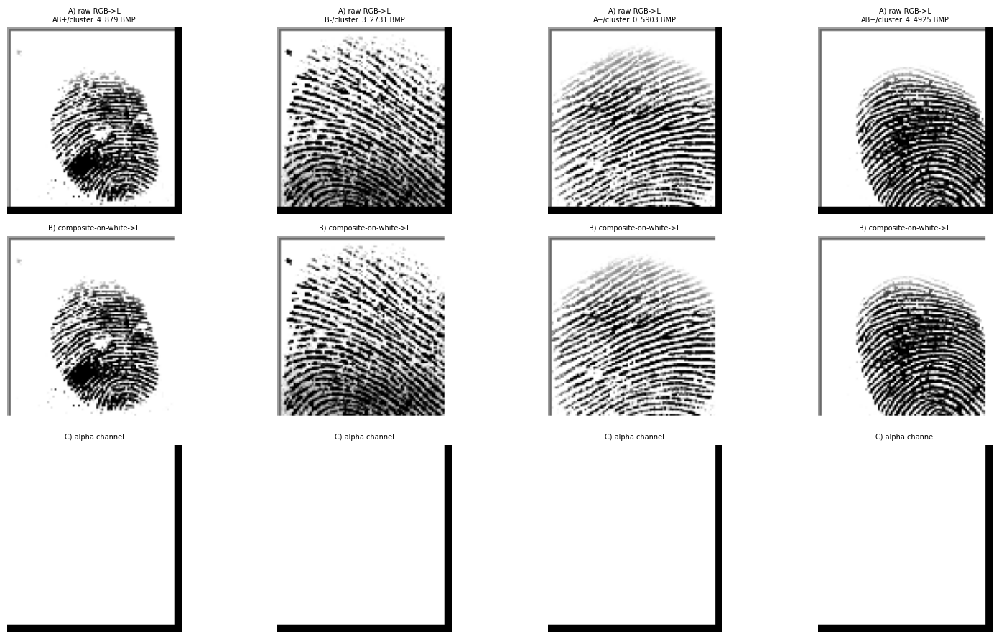


Saved: /content/drive/MyDrive/ML Fingerprint BloodGroup Project/outputs/phase2_alpha_diagnostic.png

=== RGB (no-alpha) images — do they have a matching silhouette? ===
  O-/cluster_7_2.BMP             shape=(298, 241)  near-white_frac=0.463
  O-/cluster_7_697.BMP           shape=(298, 241)  near-white_frac=0.439
  O-/cluster_7_1040.BMP          shape=(298, 241)  near-white_frac=0.450


In [ ]:
# ============================================================
# PRE-D2 v2 — understand the alpha mask and hidden RGB
# ============================================================
import numpy as np, pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from pathlib import Path
from collections import Counter

PROJECT_ROOT  = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
OUTPUTS_DIR   = PROJECT_ROOT / 'outputs'
DATASETS_ROOT = Path('/content/data/raw/datasets')

df = pd.read_csv(OUTPUTS_DIR / 'manifest_raw.csv')
rgba = df[df['mode'] == 'RGBA'].reset_index(drop=True)

# --- 1. Is the alpha mask IDENTICAL across all images? ---
masks = []
for p in rgba['path']:
    with Image.open(DATASETS_ROOT / p) as im:
        a = np.array(im.getchannel('A'))
    masks.append((a == 0).astype(np.uint8))     # 1 where transparent

stack = np.stack(masks)                          # (N, H, W)
frac_transparent_per_pixel = stack.mean(axis=0)  # fraction of images where this pixel is transparent

# If mask is fixed: fraction is either 0.0 or 1.0 everywhere (no in-between)
in_between = ((frac_transparent_per_pixel > 0.01) &
              (frac_transparent_per_pixel < 0.99)).sum()
print(f"Pixels that are 'sometimes' transparent: {in_between}")
print(f"Pixels always transparent (in all 5,793): "
      f"{(frac_transparent_per_pixel >= 0.99).sum()}")
print(f"Pixels never  transparent:                "
      f"{(frac_transparent_per_pixel <= 0.01).sum()}")
print(f"=> Mask is {'FIXED (identical across all images)' if in_between == 0 else 'VARIABLE'}")

# --- 2. What are the RGB values UNDER the transparent pixels? ---
print("\n=== RGB values under transparent pixels (5 sample images) ===")
for p in rgba['path'].sample(5, random_state=42).tolist():
    with Image.open(DATASETS_ROOT / p) as im:
        rgba_arr = np.array(im.convert('RGBA'))
    a = rgba_arr[..., 3]
    transparent_rgb = rgba_arr[..., :3][a == 0]
    if len(transparent_rgb) > 0:
        uniq = Counter(map(tuple, transparent_rgb[::50].tolist()))  # subsample for speed
        top3 = uniq.most_common(3)
        print(f"  {p:<30} n_transparent={len(transparent_rgb)}  "
              f"top RGB values: {top3}")

# --- 3. Show what each preprocessing path produces ---
sample_paths = rgba['path'].sample(4, random_state=42).tolist()
fig, axes = plt.subplots(3, len(sample_paths), figsize=(4*len(sample_paths), 9))

for i, p in enumerate(sample_paths):
    with Image.open(DATASETS_ROOT / p) as im:
        im = im.convert('RGBA')

        # Path A: raw RGB (ignore alpha) — what .convert('L') sees
        raw_l = np.array(im.convert('RGB').convert('L'))

        # Path B: composite onto WHITE, then grayscale
        white = Image.new('RGBA', im.size, (255, 255, 255, 255))
        comp_l = np.array(Image.alpha_composite(white, im).convert('RGB').convert('L'))

        # Path C: alpha channel itself (shows the mask)
        alpha = np.array(im.getchannel('A'))

    axes[0, i].imshow(raw_l, cmap='gray'); axes[0, i].set_title(f"A) raw RGB->L\n{p}", fontsize=7)
    axes[1, i].imshow(comp_l, cmap='gray'); axes[1, i].set_title("B) composite-on-white->L", fontsize=7)
    axes[2, i].imshow(alpha, cmap='gray'); axes[2, i].set_title("C) alpha channel", fontsize=7)
    for ax in axes[:, i]: ax.axis('off')

plt.tight_layout()
out = OUTPUTS_DIR / 'phase2_alpha_diagnostic.png'
plt.savefig(out, dpi=80); plt.show()
print(f"\nSaved: {out}")

# --- 4. Do the 44 RGB images also have a mask or a matching shape? ---
print("\n=== RGB (no-alpha) images — do they have a matching silhouette? ===")
rgb_df = df[df['mode'] == 'RGB']
for p in rgb_df['path'].head(3):
    with Image.open(DATASETS_ROOT / p) as im:
        arr = np.array(im.convert('L'))
    # count near-white pixels (background)
    white_frac = (arr > 240).mean()
    print(f"  {p:<30} shape={arr.shape}  near-white_frac={white_frac:.3f}")

In [ ]:
# ============================================================
# D2 — clean: composite RGBA on white, convert L->RGB, save on disk
# ============================================================
import numpy as np, pandas as pd, hashlib, time
from PIL import Image
from imagehash import phash
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed

PROJECT_ROOT  = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
OUTPUTS_DIR   = PROJECT_ROOT / 'outputs'
DATASETS_ROOT = Path('/content/data/raw/datasets')
CLEAN_ROOT    = Path('/content/data/clean')
CLEAN_ROOT.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(OUTPUTS_DIR / 'manifest_raw.csv')
print(f"Raw manifest rows: {len(df)}")

def clean_one(row):
    src   = DATASETS_ROOT / row['path']
    label = row['label']
    dst   = CLEAN_ROOT / label / row['filename']
    dst.parent.mkdir(parents=True, exist_ok=True)

    rec = {
        'path':      f"{label}/{row['filename']}",  # FLAT layout for future sessions
        'label':     label,
        'filename':  row['filename'],
        'corrupt':   False,
        'error':     None,
        'width': None, 'height': None,
        'mode_after': None, 'rgbeq': None,
        'md5_clean': None, 'phash_clean': None,
    }
    try:
        with Image.open(src) as im:
            # Composite RGBA on white so the hidden black border becomes white
            if im.mode == 'RGBA':
                white = Image.new('RGBA', im.size, (255, 255, 255, 255))
                im = Image.alpha_composite(white, im)
            # 3-channel grayscale: L then replicate to RGB
            im = im.convert('L').convert('RGB')

            # Verify R=G=B
            arr = np.array(im)
            rec['rgbeq'] = bool((arr[...,0] == arr[...,1]).all() and
                                (arr[...,1] == arr[...,2]).all())
            rec['mode_after'] = im.mode
            rec['width'], rec['height'] = im.size

            # phash on the CLEAN grayscale content (this is what D3 will use)
            rec['phash_clean'] = str(phash(im.convert('L')))

            # Save as BMP (matching original format, no compression artifacts)
            im.save(dst, format='BMP')

        # MD5 of clean file on disk
        h = hashlib.md5()
        with open(dst, 'rb') as f:
            for blk in iter(lambda: f.read(1<<16), b''):
                h.update(blk)
        rec['md5_clean'] = h.hexdigest()

    except Exception as e:
        rec['corrupt'] = True
        rec['error'] = repr(e)[:200]
    return rec

t0 = time.time()
records = []
with ThreadPoolExecutor(max_workers=8) as ex:
    futs = {ex.submit(clean_one, r): r for _, r in df.iterrows()}
    for i, fut in enumerate(as_completed(futs), 1):
        records.append(fut.result())
        if i % 500 == 0:
            print(f"  {i}/{len(df)}  elapsed={time.time()-t0:.0f}s")

clean_df = pd.DataFrame(records)
print(f"\nD2 done in {time.time()-t0:.0f}s")

# ---------- CHECKPOINT ----------
n_ok = int((~clean_df['corrupt']).sum())
n_bad = int(clean_df['corrupt'].sum())
print("\n=== D2 CHECKPOINT ===")
print(f"Images opened OK / corrupt removed: {n_ok} / {n_bad}")
print(f"Remaining: {len(clean_df)}  (expected 5,837)")
print(f"Every image is mode RGB and has R=G=B: "
      f"{bool(clean_df['rgbeq'].dropna().all())}")
print(f"Sizes still mixed: {clean_df.groupby(['width','height']).size().to_dict()}"
      f"   (resize happens in D5)")
print(f"Per-class counts after D2:")
print(clean_df['label'].value_counts().sort_index().to_string())

if n_bad > 0:
    print("\nCorrupt files:")
    for _, r in clean_df[clean_df['corrupt']].iterrows():
        print(f"   {r['path']} -> {r['error']}")

# Save clean manifest for D3
clean_df.to_csv(OUTPUTS_DIR / 'manifest_clean.csv', index=False)
print(f"\nSaved: {OUTPUTS_DIR / 'manifest_clean.csv'}")

# Save label->index mapping (D1's final piece)
LABEL_TO_IDX = {'A+':0,'A-':1,'B+':2,'B-':3,'AB+':4,'AB-':5,'O+':6,'O-':7}
import json
with open(OUTPUTS_DIR / 'label_to_idx.json', 'w') as f:
    json.dump(LABEL_TO_IDX, f, indent=2)
print(f"Saved: {OUTPUTS_DIR / 'label_to_idx.json'}")

# Sanity: read one clean image back and confirm
sample = clean_df.iloc[0]['path']
with Image.open(CLEAN_ROOT / sample) as im2:
    print(f"\nSample read-back: {sample} mode={im2.mode} size={im2.size}")

Raw manifest rows: 5837
  500/5837  elapsed=4s
  1000/5837  elapsed=5s
  1500/5837  elapsed=6s
  2000/5837  elapsed=7s
  2500/5837  elapsed=9s
  3000/5837  elapsed=10s
  3500/5837  elapsed=12s
  4000/5837  elapsed=13s
  4500/5837  elapsed=14s
  5000/5837  elapsed=15s
  5500/5837  elapsed=16s

D2 done in 17s

=== D2 CHECKPOINT ===
Images opened OK / corrupt removed: 5837 / 0
Remaining: 5837  (expected 5,837)
Every image is mode RGB and has R=G=B: True
Sizes still mixed: {(96, 103): 5793, (241, 298): 44}   (resize happens in D5)
Per-class counts after D2:
label
A+      402
A-     1009
AB+     708
AB-     761
B+      652
B-      741
O+      852
O-      712

Saved: /content/drive/MyDrive/ML Fingerprint BloodGroup Project/outputs/manifest_clean.csv
Saved: /content/drive/MyDrive/ML Fingerprint BloodGroup Project/outputs/label_to_idx.json

Sample read-back: O-/cluster_7_3987.BMP mode=RGB size=(96, 103)


In [ ]:
# ============================================================
# D3 — group by MD5 ∪ phash≤2 (within-class). Save manifest_grouped.csv
# ============================================================
import numpy as np, pandas as pd
from collections import Counter
from pathlib import Path

PROJECT_ROOT = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
OUTPUTS_DIR  = PROJECT_ROOT / 'outputs'
df = pd.read_csv(OUTPUTS_DIR / 'manifest_clean.csv')
df['idx'] = range(len(df))

# ---------- Step 1: re-validate phash distribution on CLEAN images ----------
arr    = np.array([int(p, 16) for p in df['phash_clean']], dtype=np.uint64)
labels = df['label'].values
N      = len(arr)
lut    = np.array([bin(i).count('1') for i in range(256)], dtype=np.uint8)

hist_total = np.zeros(65, dtype=np.int64)
hist_cross = np.zeros(65, dtype=np.int64)

print("Computing histogram (this is the same O(N^2/2) as before)...")
for i in range(N):
    xor = arr[i+1:] ^ arr[i]
    if xor.size == 0: continue
    d = lut[xor.view(np.uint8).reshape(-1, 8)].sum(axis=1).astype(np.int64)
    hist_total += np.bincount(d, minlength=65)
    cross_mask = labels[i] != labels[i+1:]
    if cross_mask.any():
        hist_cross += np.bincount(d[cross_mask], minlength=65)

print("\n=== PHASH ON CLEAN IMAGES (vs raw images before) ===")
print(f"{'dist':>4}  {'total pairs':>14}  {'cross-class':>14}  {'within-class':>14}")
for d in range(0, 13):
    if hist_total[d] > 0 or d <= 6:
        within = int(hist_total[d] - hist_cross[d])
        print(f"{d:>4}  {int(hist_total[d]):>14,}  {int(hist_cross[d]):>14,}  {within:>14,}")

cc02 = int(hist_cross[0] + hist_cross[1] + hist_cross[2])
cc04 = int(hist_cross[0] + hist_cross[1] + hist_cross[2] + hist_cross[3] + hist_cross[4])
print(f"\nCross-class pairs at dist<=2: {cc02}  (must be 0 to proceed)")
print(f"Cross-class pairs at dist<=4: {cc04}")

if cc02 > 0:
    raise SystemExit("STOP: cross-class pairs exist at dist<=2. Threshold must be "
                     "revisited before grouping. Paste this output back.")

# ---------- Step 2: union-find ----------
parent = list(range(N))
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]; x = parent[x]
    return x
def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb: parent[rb] = ra

# MD5 unions (global)
md5_to_first = {}
for i in range(N):
    m = df.iloc[i]['md5_clean']
    if m in md5_to_first:
        union(md5_to_first[m], i)
    else:
        md5_to_first[m] = i

# phash<=2 unions WITHIN-CLASS only
for i in range(N):
    xor = arr[i+1:] ^ arr[i]
    if xor.size == 0: continue
    d = lut[xor.view(np.uint8).reshape(-1, 8)].sum(axis=1).astype(np.int64)
    match = (d <= 2) & (labels[i] == labels[i+1:])
    for jj in np.where(match)[0]:
        union(i, i+1+int(jj))

assign = [find(i) for i in range(N)]
df['group_id'] = assign

# ---------- Step 3: checkpoint ----------
sizes = Counter(assign)
print("\n=== D3 CHECKPOINT ===")
print(f"Total groups:              {len(sizes):,}")
print(f"Largest group size:        {max(sizes.values())}")
print(f"Singleton groups:          {sum(1 for v in sizes.values() if v == 1):,}")
print(f"Multi-image groups:        {sum(1 for v in sizes.values() if v > 1):,}")
print(f"Images in multi-image grp: {sum(v for v in sizes.values() if v > 1):,}")
print(f"Unassigned images:         {N - sum(sizes.values())}  (should be 0)")

gid_to_labels = df.groupby('group_id')['label'].nunique()
bad_groups = gid_to_labels[gid_to_labels > 1]
print(f"Groups containing >1 label: {len(bad_groups)}  (MUST be 0 by construction)")
if len(bad_groups) > 0:
    for gid in bad_groups.index[:5]:
        rows = df[df['group_id'] == gid][['label','path']]
        print(f"   group {gid}: {rows.values.tolist()}")

# Save
df.drop(columns=['idx']).to_csv(OUTPUTS_DIR / 'manifest_grouped.csv', index=False)
print(f"\nSaved: {OUTPUTS_DIR / 'manifest_grouped.csv'}")

Computing histogram (this is the same O(N^2/2) as before)...

=== PHASH ON CLEAN IMAGES (vs raw images before) ===
dist     total pairs     cross-class    within-class
   0              24               2              22
   1               0               0               0
   2              78              46              32
   3               0               0               0
   4             950             601             349
   5               0               0               0
   6           7,324           4,872           2,452
   8          32,950          22,761          10,189
  10         108,716          77,886          30,830
  12         276,449         205,689          70,760

Cross-class pairs at dist<=2: 48  (must be 0 to proceed)
Cross-class pairs at dist<=4: 649


SystemExit: STOP: cross-class pairs exist at dist<=2. Threshold must be revisited before grouping. Paste this output back.

/usr/local/lib/python3.13/dist-packages/IPython/core/interactiveshell.py:3561: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [ ]:
# ============================================================
# D3-FINAL — Option B: group by MD5 ∪ phash<=2 (global)
#           + drop cross-class exact-MD5 copies (user rule)
# ============================================================
import numpy as np, pandas as pd
from collections import Counter
from pathlib import Path

PROJECT_ROOT = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
OUTPUTS_DIR  = PROJECT_ROOT / 'outputs'
df = pd.read_csv(OUTPUTS_DIR / 'manifest_clean.csv').reset_index(drop=True)
df['idx'] = range(len(df))

# ---------- 1. Identify cross-class pairs at dist 0 and dist 2 ----------
arr = np.array([int(p, 16) for p in df['phash_clean']], dtype=np.uint64)
labels = df['label'].values
lut = np.array([bin(i).count('1') for i in range(256)], dtype=np.uint8)
N = len(arr)

dist0_cross, dist2_cross = [], []
for i in range(N):
    xor = arr[i+1:] ^ arr[i]
    if xor.size == 0: continue
    d = lut[xor.view(np.uint8).reshape(-1, 8)].sum(axis=1).astype(np.int64)
    for jj in np.where((d == 0) & (labels[i] != labels[i+1:]))[0]:
        dist0_cross.append((i, i+1+int(jj)))
    for jj in np.where((d == 2) & (labels[i] != labels[i+1:]))[0]:
        dist2_cross.append((i, i+1+int(jj)))

print("=== CROSS-CLASS PAIRS AT DIST 0 (question: MD5-identical?) ===")
for i, j in dist0_cross:
    ri, rj = df.iloc[i], df.iloc[j]
    print(f"  {ri['path']:<35} ({ri['label']})")
    print(f"  {rj['path']:<35} ({rj['label']})")
    print(f"  same MD5? {ri['md5_clean'] == rj['md5_clean']}")
    print()

print(f"=== CROSS-CLASS PAIRS AT DIST 2: {len(dist2_cross)} ===")
n_same_md5 = sum(1 for i,j in dist2_cross if df.iloc[i]['md5_clean'] == df.iloc[j]['md5_clean'])
print(f"  Pairs sharing MD5: {n_same_md5}  (expected 0)")
print(f"  Rest are phash-identical look-alikes.")

# ---------- 2. MD5 label-conflict check ----------
print("\n=== MD5 LABEL-CONFLICT CHECK ===")
md5_classes = df.groupby('md5_clean')['label'].nunique()
conflicts = md5_classes[md5_classes > 1]
print(f"MD5s present in >1 class: {len(conflicts)}")

drop_md5s = set()
if len(conflicts) > 0:
    print("Dropping ALL copies of the following MD5s (cross-class):")
    for h in conflicts.index:
        rows = df[df['md5_clean'] == h][['path','label']]
        print(f"  md5={h[:12]}...  -> {rows.values.tolist()}")
        drop_md5s.add(h)
else:
    print("→ NO MD5 spans >1 class. Drop rule does not trigger.")
    print("→ The 2 dist-0 cross-class pairs are phash-identical but MD5-DIFFERENT.")
    print("  They are look-alikes, not exact copies. They'll be GROUPED (safe),")
    print("  not dropped.")

# ---------- 3. Apply drop if any ----------
if drop_md5s:
    before = len(df)
    df = df[~df['md5_clean'].isin(drop_md5s)].reset_index(drop=True)
    df['idx'] = range(len(df))
    arr = np.array([int(p, 16) for p in df['phash_clean']], dtype=np.uint64)
    labels = df['label'].values
    N = len(arr)
    print(f"\nDropped {before - len(df)} images. Remaining: {len(df)}")
else:
    print(f"\nNothing dropped. Remaining: {len(df)}")

# ---------- 4. Union-find: MD5 ∪ phash<=2, GLOBAL ----------
parent = list(range(N))
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]; x = parent[x]
    return x
def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb: parent[rb] = ra

md5_first = {}
for i in range(N):
    m = df.iloc[i]['md5_clean']
    if m in md5_first: union(md5_first[m], i)
    else: md5_first[m] = i

print("\nUnion-find: adding phash<=2 edges (global)...")
for i in range(N):
    xor = arr[i+1:] ^ arr[i]
    if xor.size == 0: continue
    d = lut[xor.view(np.uint8).reshape(-1, 8)].sum(axis=1).astype(np.int64)
    for jj in np.where(d <= 2)[0]:
        union(i, i+1+int(jj))

assign = [find(i) for i in range(N)]
df['group_id'] = assign

# ---------- 5. Checkpoint ----------
sizes = Counter(assign)
print("\n=== D3-FINAL CHECKPOINT (Option B) ===")
print(f"Total groups:              {len(sizes):,}")
print(f"Largest group size:        {max(sizes.values())}")
print(f"Singleton groups:          {sum(1 for v in sizes.values() if v == 1):,}")
print(f"Multi-image groups:        {sum(1 for v in sizes.values() if v > 1):,}")
print(f"Images in multi-image grp: {sum(v for v in sizes.values() if v > 1):,}")

gid_labels = df.groupby('group_id')['label'].nunique()
cross_groups = gid_labels[gid_labels > 1]
print(f"\nGroups containing >1 label: {len(cross_groups)}  "
      f"(EXPECTED for Option B — NOT a bug)")
print(f"  2-label groups: {sum(1 for v in gid_labels.values if v == 2)}")
print(f"  3+-label groups: {sum(1 for v in gid_labels.values if v >= 3)}")
if len(cross_groups) > 0:
    print("  Top 5 cross-label groups (by size):")
    top5 = sorted(cross_groups.index, key=lambda g: -sizes[g])[:5]
    for gid in top5:
        rows = df[df['group_id'] == gid]
        print(f"    group {gid}: size={len(rows)}  labels={rows['label'].value_counts().to_dict()}")

print(f"\nClass counts after D3:")
print(df['label'].value_counts().sort_index().to_string())

# ---------- 6. Save ----------
df.drop(columns=['idx']).to_csv(OUTPUTS_DIR / 'manifest_grouped.csv', index=False)
print(f"\nSaved: {OUTPUTS_DIR / 'manifest_grouped.csv'}")

=== CROSS-CLASS PAIRS AT DIST 0 (question: MD5-identical?) ===
  B-/cluster_3_825.BMP                (B-)
  AB-/cluster_5_1867.BMP              (AB-)
  same MD5? False

  AB+/cluster_4_639.BMP               (AB+)
  B+/cluster_2_2734.BMP               (B+)
  same MD5? False

=== CROSS-CLASS PAIRS AT DIST 2: 46 ===
  Pairs sharing MD5: 0  (expected 0)
  Rest are phash-identical look-alikes.

=== MD5 LABEL-CONFLICT CHECK ===
MD5s present in >1 class: 0
→ NO MD5 spans >1 class. Drop rule does not trigger.
→ The 2 dist-0 cross-class pairs are phash-identical but MD5-DIFFERENT.
  They are look-alikes, not exact copies. They'll be GROUPED (safe),
  not dropped.

Nothing dropped. Remaining: 5837

Union-find: adding phash<=2 edges (global)...

=== D3-FINAL CHECKPOINT (Option B) ===
Total groups:              5,746
Largest group size:        7
Singleton groups:          5,683
Multi-image groups:        63
Images in multi-image grp: 154

Groups containing >1 label: 39  (EXPECTED for Option B — NO

In [ ]:
import pandas as pd
from pathlib import Path
from sklearn.model_selection import StratifiedGroupKFold

OUT = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project/outputs')
SPLITS = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project/splits')
SPLITS.mkdir(exist_ok=True)

df = pd.read_csv(OUT / 'manifest_grouped.csv')

# Pass 1: TEST (1/7)
sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=42)
rest_idx, test_idx = next(sgkf.split(df, df['label'], groups=df['group_id']))
rest, test = df.iloc[rest_idx], df.iloc[test_idx]

# Pass 2: VAL (1/6 of the remainder)
sgkf2 = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=42)
tr_idx, val_idx = next(sgkf2.split(rest, rest['label'], groups=rest['group_id']))
train, val = rest.iloc[tr_idx], rest.iloc[val_idx]          # <- fixed

# Save to splits/
train.to_csv(SPLITS/'train.csv', index=False)
val.to_csv(SPLITS/'val.csv',   index=False)
test.to_csv(SPLITS/'test.csv', index=False)

# Checkpoint
n = len(df)
print("Sizes:", {k: f"{len(v)} ({len(v)/n:.1%})" for k, v in
                 [('train', train), ('val', val), ('test', test)]})
print("\nClass counts per split:")
print(pd.DataFrame({'train': train['label'].value_counts(),
                    'val':   val['label'].value_counts(),
                    'test':  test['label'].value_counts()}).fillna(0).astype(int))
print("\nClass share per split (%):")
print((pd.DataFrame({'train': train['label'].value_counts(normalize=True),
                     'val':   val['label'].value_counts(normalize=True),
                     'test':  test['label'].value_counts(normalize=True)})*100).round(1))

g = {k: set(v['group_id']) for k, v in [('train', train), ('val', val), ('test', test)]}
print("\nGroup overlap  train&val:", len(g['train'] & g['val']),
      " train&test:", len(g['train'] & g['test']),
      " val&test:", len(g['val'] & g['test']))
p = {k: set(v['path']) for k, v in [('train', train), ('val', val), ('test', test)]}
print("Path overlap   train&val:", len(p['train'] & p['val']),
      " train&test:", len(p['train'] & p['test']),
      " val&test:", len(p['val'] & p['test']))
print("Total after split:", len(train) + len(val) + len(test), "(expected", n, ")")

Sizes: {'train': '4165 (71.4%)', 'val': '830 (14.2%)', 'test': '842 (14.4%)'}

Class counts per split:
       train  val  test
label                  
A+       287   59    56
A-       721  147   141
AB+      503  100   105
AB-      543  109   109
B+       460   92   100
B-       534  101   106
O+       609  123   120
O-       508   99   105

Class share per split (%):
       train   val  test
label                   
A+       6.9   7.1   6.7
A-      17.3  17.7  16.7
AB+     12.1  12.0  12.5
AB-     13.0  13.1  12.9
B+      11.0  11.1  11.9
B-      12.8  12.2  12.6
O+      14.6  14.8  14.3
O-      12.2  11.9  12.5

Group overlap  train&val: 0  train&test: 0  val&test: 0
Path overlap   train&val: 0  train&test: 0  val&test: 0
Total after split: 5837 (expected 5837 )


In [ ]:
# ============================================================
# POST-DISCONNECT CHECK — verify what survived on Drive
# ============================================================
from pathlib import Path
from google.colab import drive
drive.mount('/content/drive')

PROJECT_ROOT = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
must_have = [
    'kaggle_raw_dataset.zip',
    'outputs/manifest_raw.csv',
    'outputs/manifest_clean.csv',
    'outputs/manifest_grouped.csv',
    'outputs/label_to_idx.json',
    'outputs/run_log.csv',
    'outputs/phash_hist.txt',
    'splits/train.csv',
    'splits/val.csv',
    'splits/test.csv',
]
print("=== FILES ON DRIVE ===")
for rel in must_have:
    p = PROJECT_ROOT / rel
    status = f"{p.stat().st_size:>10,} bytes" if p.exists() else "MISSING"
    print(f"  {rel:<35} {status}")

# Row counts — the definitive check for CSVs
import pandas as pd
print("\n=== CSV ROW COUNTS ===")
for rel in ['outputs/manifest_grouped.csv', 'splits/train.csv',
            'splits/val.csv', 'splits/test.csv']:
    p = PROJECT_ROOT / rel
    if p.exists():
        n = sum(1 for _ in open(p)) - 1
        print(f"  {rel:<35} {n:>5,} rows")

# Ephemeral directories — these WILL be gone (expected)
print("\n=== EPHEMERAL (will be missing — expected) ===")
for rel in ['/content/data/raw/datasets', '/content/data/clean']:
    p = Path(rel)
    print(f"  {rel:<35} {'exists' if p.exists() else 'GONE (will rebuild)'}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
=== FILES ON DRIVE ===
  kaggle_raw_dataset.zip              59,252,979 bytes
  outputs/manifest_raw.csv               718,827 bytes
  outputs/manifest_clean.csv             683,805 bytes
  outputs/manifest_grouped.csv           711,876 bytes
  outputs/label_to_idx.json                   92 bytes
  outputs/run_log.csv                        131 bytes
  outputs/phash_hist.txt                     211 bytes
  splits/train.csv                       507,961 bytes
  splits/val.csv                         101,309 bytes
  splits/test.csv                        102,796 bytes

=== CSV ROW COUNTS ===
  outputs/manifest_grouped.csv        5,837 rows
  splits/train.csv                    4,165 rows
  splits/val.csv                        830 rows
  splits/test.csv                       842 rows

=== EPHEMERAL (will be missing — expected) ===
  /content/data/raw/datasets  

=== D5 TRANSFORM DEFINITIONS ===
  Resize:  224x224 stretch (no aspect-preserve) — C1 decision
  Normalize: ImageNet mean=[0.485, 0.456, 0.406]  std=[0.229, 0.224, 0.225]
  TRAIN aug:
    RandomAffine(degrees=±10, translate=±5%, scale=0.95-1.05, fill=white)
    ColorJitter(brightness=0.1, contrast=0.1)
    NO horizontal / vertical flips
  VAL/TEST: resize + normalize only

=== SHAPE / DTYPE SANITY ===
  raw image:               size=(96, 103), mode=RGB
  train_transform output:  shape=(3, 224, 224), dtype=torch.float32
  val_transform output:    shape=(3, 224, 224),   dtype=torch.float32
  train tensor range:      min=-2.12  max=2.64


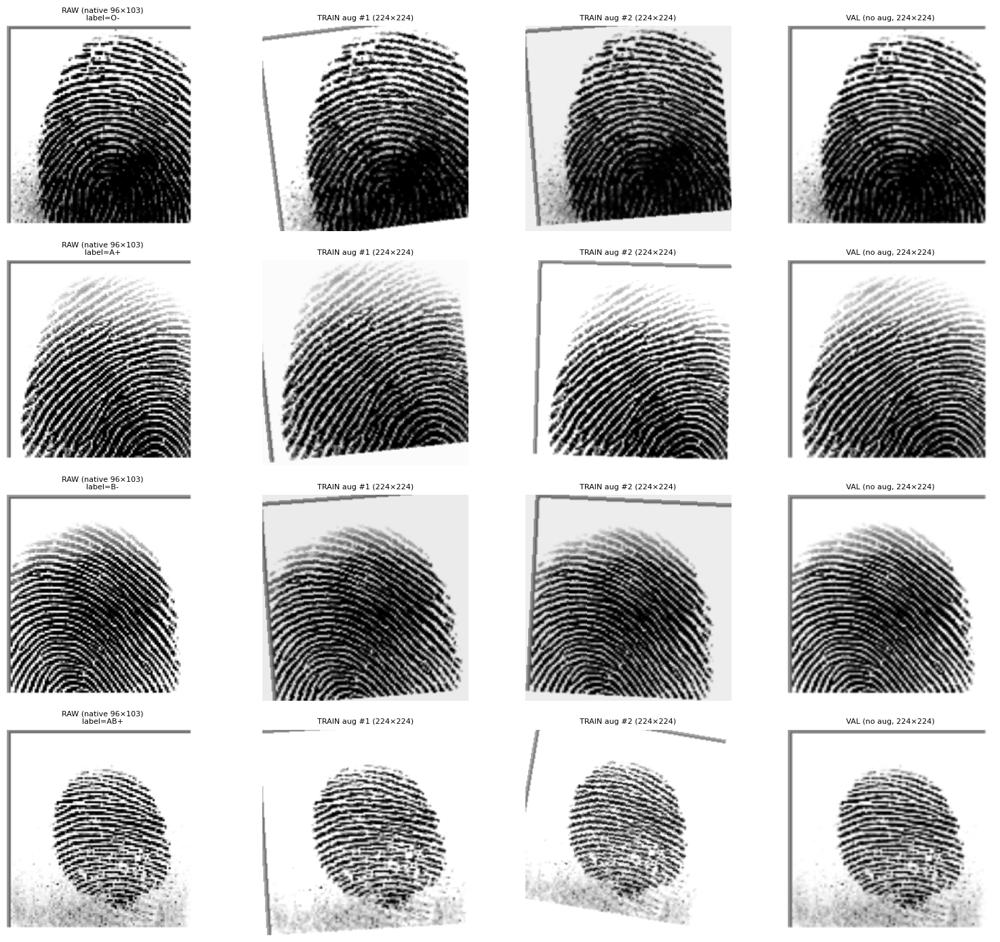


Saved: /content/drive/MyDrive/ML Fingerprint BloodGroup Project/outputs/d5_transforms_grid.png

=== D5 CHECKPOINT ===
Transforms defined:   preprocess_only, train_transform, val_transform, test_transform
Resize:               224x224 stretch (C1)
Normalize:            ImageNet mean/std
Train augmentation:   RandomAffine(±10°, ±5%, 0.95-1.05) + ColorJitter(0.1, 0.1)
No flips:             confirmed
Val/test:             preprocess only, no augmentation
Grid saved:           /content/drive/MyDrive/ML Fingerprint BloodGroup Project/outputs/d5_transforms_grid.png


In [ ]:
# ============================================================
# D5 — Define transforms + visualization grid
# ============================================================
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from torchvision import transforms
from PIL import Image
from pathlib import Path

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]
IMG_SIZE      = 224

# ---- Preprocessing (all splits) ----
preprocess_only = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE), antialias=True),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

# ---- Train: preprocess + light augmentation ----
# RandomAffine combines: rotation ±10°, translate ±5%, zoom 0.95-1.05
# fill=255 → white fill for rotated corners (matches our white background)
# NO horizontal / vertical flips (fingerprints are orientation-specific)
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE), antialias=True),
    transforms.RandomAffine(
        degrees=10,
        translate=(0.05, 0.05),
        scale=(0.95, 1.05),
        fill=255,
    ),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

# ---- Val / Test: preprocessing only ----
val_transform  = preprocess_only
test_transform = preprocess_only

print("=== D5 TRANSFORM DEFINITIONS ===")
print(f"  Resize:  {IMG_SIZE}x{IMG_SIZE} stretch (no aspect-preserve) — C1 decision")
print(f"  Normalize: ImageNet mean={IMAGENET_MEAN}  std={IMAGENET_STD}")
print(f"  TRAIN aug:")
print(f"    RandomAffine(degrees=±10, translate=±5%, scale=0.95-1.05, fill=white)")
print(f"    ColorJitter(brightness=0.1, contrast=0.1)")
print(f"    NO horizontal / vertical flips")
print(f"  VAL/TEST: resize + normalize only")

# ---- Sanity: shapes and dtypes ----
CLEAN_ROOT = Path('/content/data/clean')
SPLITS_DIR = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project/splits')
train_df = pd.read_csv(SPLITS_DIR / 'train.csv')

sample_path = CLEAN_ROOT / train_df.iloc[0]['path']
sample_img  = Image.open(sample_path)
t_train     = train_transform(sample_img)
t_val       = val_transform(sample_img)
print(f"\n=== SHAPE / DTYPE SANITY ===")
print(f"  raw image:               size={sample_img.size}, mode={sample_img.mode}")
print(f"  train_transform output:  shape={tuple(t_train.shape)}, dtype={t_train.dtype}")
print(f"  val_transform output:    shape={tuple(t_val.shape)},   dtype={t_val.dtype}")
print(f"  train tensor range:      min={t_train.min().item():.2f}  max={t_train.max().item():.2f}")
assert tuple(t_train.shape) == (3, IMG_SIZE, IMG_SIZE)
assert tuple(t_val.shape)   == (3, IMG_SIZE, IMG_SIZE)

# ---- Visualization grid ----
def denorm(t):
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std  = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (t * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

# One sample per class, first 4 classes (keeps grid manageable)
sample_df = train_df.groupby('label').head(1).reset_index(drop=True).head(4)

fig, axes = plt.subplots(len(sample_df), 4, figsize=(16, 3.5 * len(sample_df)))
for i, row in sample_df.iterrows():
    img = Image.open(CLEAN_ROOT / row['path'])

    # Col 1: raw (native size)
    axes[i][0].imshow(img)
    axes[i][0].set_title(f"RAW (native {img.size[0]}×{img.size[1]})\nlabel={row['label']}",
                         fontsize=8)
    axes[i][0].axis('off')

    # Cols 2-3: two distinct train augmentations
    for col, label in [(1, "TRAIN aug #1"), (2, "TRAIN aug #2")]:
        t = train_transform(img)
        axes[i][col].imshow(denorm(t))
        axes[i][col].set_title(f"{label} (224×224)", fontsize=8)
        axes[i][col].axis('off')

    # Col 4: val (no aug)
    t = val_transform(img)
    axes[i][3].imshow(denorm(t))
    axes[i][3].set_title(f"VAL (no aug, 224×224)", fontsize=8)
    axes[i][3].axis('off')

plt.tight_layout()
out = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project/outputs/d5_transforms_grid.png')
plt.savefig(out, dpi=100)
plt.show()
print(f"\nSaved: {out}")

print("\n=== D5 CHECKPOINT ===")
print(f"Transforms defined:   preprocess_only, train_transform, val_transform, test_transform")
print(f"Resize:               {IMG_SIZE}x{IMG_SIZE} stretch (C1)")
print(f"Normalize:            ImageNet mean/std")
print(f"Train augmentation:   RandomAffine(±10°, ±5%, 0.95-1.05) + ColorJitter(0.1, 0.1)")
print(f"No flips:             confirmed")
print(f"Val/test:             preprocess only, no augmentation")
print(f"Grid saved:           {out}")

In [ ]:
import json, torch, numpy as np, pandas as pd
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)

CLEAN_ROOT = Path('/content/data/clean')
SPLITS_DIR = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project/splits')
OUT        = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project/outputs')

label_to_idx = json.load(open(OUT / 'label_to_idx.json'))
idx_to_label = {v: k for k, v in label_to_idx.items()}
NUM_CLASSES  = len(label_to_idx)

class FingerprintDS(Dataset):
    def __init__(self, csv_path, transform):
        self.df = pd.read_csv(csv_path).reset_index(drop=True)
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(CLEAN_ROOT / row['path']).convert('RGB')
        return self.transform(img), label_to_idx[row['label']]

train_ds = FingerprintDS(SPLITS_DIR / 'train.csv', train_transform)
val_ds   = FingerprintDS(SPLITS_DIR / 'val.csv',   val_transform)
test_ds  = FingerprintDS(SPLITS_DIR / 'test.csv',  test_transform)

BATCH = 32
g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True,  num_workers=2, generator=g)
val_loader   = DataLoader(val_ds,   batch_size=BATCH, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_ds,  batch_size=BATCH, shuffle=False, num_workers=2)

# Class weights from TRAIN only: n / (K * count)
counts = train_ds.df['label'].map(label_to_idx).value_counts().sort_index()
weights = len(train_ds) / (NUM_CLASSES * counts.values)
class_weights = torch.tensor(weights, dtype=torch.float32)

# ---------------- CHECKPOINT ----------------
print("=== D6 CHECKPOINT ===")
print("Dataset sizes: train", len(train_ds), "val", len(val_ds), "test", len(test_ds))
print("Label map:", label_to_idx)

for name, loader in [('train', train_loader), ('val', val_loader), ('test', test_loader)]:
    x, y = next(iter(loader))
    print(f"{name:5s} batch: x={tuple(x.shape)} {x.dtype}, y={tuple(y.shape)} {y.dtype}, "
          f"label range {y.min().item()}-{y.max().item()}")

print("\nClass weights (train only):")
for i in range(NUM_CLASSES):
    print(f"  {idx_to_label[i]:4s} count={counts.values[i]:4d}  weight={class_weights[i]:.3f}")

# Augmentation only on train: same image twice
a, b = train_ds[0][0], train_ds[0][0]
c, d = val_ds[0][0],   val_ds[0][0]
print("\nTrain same image twice identical?", torch.equal(a, b), "(expect False)")
print("Val   same image twice identical?", torch.equal(c, d), "(expect True)")

# No NaNs
x, _ = next(iter(train_loader))
print("NaN in train batch:", torch.isnan(x).any().item(), "(expect False)")

torch.save(class_weights, OUT / 'class_weights.pt')
print("\nSaved class_weights.pt")

=== D6 CHECKPOINT ===
Dataset sizes: train 4165 val 830 test 842
Label map: {'A+': 0, 'A-': 1, 'B+': 2, 'B-': 3, 'AB+': 4, 'AB-': 5, 'O+': 6, 'O-': 7}
train batch: x=(32, 3, 224, 224) torch.float32, y=(32,) torch.int64, label range 0-7
val   batch: x=(32, 3, 224, 224) torch.float32, y=(32,) torch.int64, label range 7-7
test  batch: x=(32, 3, 224, 224) torch.float32, y=(32,) torch.int64, label range 7-7

Class weights (train only):
  A+   count= 287  weight=1.814
  A-   count= 721  weight=0.722
  B+   count= 460  weight=1.132
  B-   count= 534  weight=0.975
  AB+  count= 503  weight=1.035
  AB-  count= 543  weight=0.959
  O+   count= 609  weight=0.855
  O-   count= 508  weight=1.025

Train same image twice identical? False (expect False)
Val   same image twice identical? True (expect True)
NaN in train batch: False (expect False)

Saved class_weights.pt


In [ ]:
import torch
print("CUDA available:", torch.cuda.is_available())
print("Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

CUDA available: True
Device: Tesla T4


In [ ]:
# ============================================================
# PHASE 5 — Sanity checks: tiny overfit + label shuffle
# Requires: D5 transforms, D6 loaders/datasets defined in this session
# ============================================================
import copy, json, time, random
import numpy as np, pandas as pd, torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import models, transforms
from pathlib import Path
from PIL import Image
from sklearn.metrics import f1_score

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {DEVICE}")

# --- re-assert transforms + datasets exist (in case this cell is run fresh) ---
IMAGENET_MEAN = [0.485, 0.456, 0.406]; IMAGENET_STD = [0.229, 0.224, 0.225]
preprocess_only = transforms.Compose([
    transforms.Resize((224,224), antialias=True),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)])
train_transform = transforms.Compose([
    transforms.Resize((224,224), antialias=True),
    transforms.RandomAffine(10, translate=(0.05,0.05), scale=(0.95,1.05), fill=255),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)])

CLEAN_ROOT = Path('/content/data/clean')
SPLITS_DIR = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project/splits')
OUT        = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project/outputs')
label_to_idx = json.load(open(OUT / 'label_to_idx.json'))
NUM_CLASSES  = len(label_to_idx)

class DS(torch.utils.data.Dataset):
    def __init__(self, csv, tf):
        self.df = pd.read_csv(csv).reset_index(drop=True)
        self.tf = tf
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]
        return self.tf(Image.open(CLEAN_ROOT / r['path']).convert('RGB')), label_to_idx[r['label']]

train_ds = DS(SPLITS_DIR / 'train.csv', train_transform)
val_ds   = DS(SPLITS_DIR / 'val.csv',   preprocess_only)

# --- helper: build fresh ResNet-50 each time ---
def build_model():
    m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
    m.fc = nn.Linear(m.fc.in_features, NUM_CLASSES)
    return m.to(DEVICE)

def train_epochs(model, loader, epochs, lr=1e-3, train_only=True):
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    loss_fn = nn.CrossEntropyLoss()
    for ep in range(epochs):
        model.train()
        correct, total, tot_loss = 0, 0, 0.0
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            logits = model(x)
            loss = loss_fn(logits, y)
            loss.backward(); opt.step()
            tot_loss += loss.item() * x.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            total += x.size(0)
        if (ep+1) % 5 == 0 or ep == 0 or ep == epochs-1:
            print(f"    ep{ep+1:>2}/{epochs}: train_loss={tot_loss/total:.4f}  "
                  f"train_acc={correct/total:.4f}")

@torch.no_grad()
def eval_acc(model, loader):
    model.eval()
    correct, total = 0, 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        correct += (model(x).argmax(1) == y).sum().item()
        total += x.size(0)
    return correct / total

# ============================================================
# TEST A — TINY OVERFIT (50 images, 30 epochs)
# ============================================================
print("\n" + "="*60)
print("PHASE 5A — TINY OVERFIT (50 images, 30 epochs)")
print("Expected: train accuracy → ~100% (overfit on purpose)")
print("="*60)

subset = Subset(train_ds, list(range(50)))
tiny_loader = DataLoader(subset, batch_size=16, shuffle=True, num_workers=2)
tiny_eval   = DataLoader(subset, batch_size=16, shuffle=False, num_workers=2)

tiny_model = build_model()
t0 = time.time()
train_epochs(tiny_model, tiny_loader, epochs=30, lr=1e-3)
tiny_train_acc = eval_acc(tiny_model, tiny_eval)
print(f"\n  Final TRAIN accuracy on 50 images: {tiny_train_acc:.4f}")
print(f"  Time: {time.time()-t0:.0f}s")
print(f"  VERDICT: {'PASS ✓' if tiny_train_acc > 0.95 else 'FAIL ✗ — pipeline bug'}")
del tiny_model; torch.cuda.empty_cache()

# ============================================================
# TEST B — LABEL SHUFFLE (full train set, 5 epochs)
# ============================================================
print("\n" + "="*60)
print("PHASE 5B — LABEL SHUFFLE (full train, 5 epochs)")
print("Expected: val accuracy → ~12.5% (chance for 8 classes)")
print("="*60)

class ShuffledDS(torch.utils.data.Dataset):
    def __init__(self, base):
        self.base = base
        n = len(base)
        idxs = list(range(n))
        random.Random(SEED).shuffle(idxs)
        self.perm = idxs          # image i gets label of image perm[i]
    def __len__(self): return len(self.base)
    def __getitem__(self, i):
        x, _ = self.base[i]
        _, y_shuf = self.base[self.perm[i]]
        return x, y_shuf

shuf_ds = ShuffledDS(train_ds)
shuf_loader = DataLoader(shuf_ds, batch_size=32, shuffle=True, num_workers=2)
val_loader  = DataLoader(val_ds, batch_size=32, shuffle=False, num_workers=2)

shuf_model = build_model()
# freeze backbone, train head only — faster, still tests the pipeline
for p in shuf_model.parameters(): p.requires_grad = False
for p in shuf_model.fc.parameters(): p.requires_grad = True
t0 = time.time()
train_epochs(shuf_model, shuf_loader, epochs=5, lr=1e-3)
val_acc = eval_acc(shuf_model, val_loader)
print(f"\n  Val accuracy on shuffled labels: {val_acc:.4f}")
print(f"  Time: {time.time()-t0:.0f}s")
verdict = "PASS ✓" if val_acc < 0.20 else "FAIL ✗ — possible leakage"
print(f"  VERDICT: {verdict}  (should be near 12.5%, NOT above ~20%)")
del shuf_model; torch.cuda.empty_cache()

# ============================================================
# PHASE 5 SUMMARY
# ============================================================
print("\n" + "="*60)
print("PHASE 5 SUMMARY")
print("="*60)
print(f"  5A Tiny overfit:    train_acc = {tiny_train_acc:.4f}  "
      f"{'PASS' if tiny_train_acc > 0.95 else 'FAIL'}")
print(f"  5B Label shuffle:   val_acc   = {val_acc:.4f}  "
      f"{'PASS' if val_acc < 0.20 else 'FAIL'}")
print(f"  Majority baseline (from Phase 1): 0.1729")
print(f"  Random baseline (8 classes):      0.1250")
print(f"\n  Overall: {'ALL PASS — pipeline is correct, proceed to Phase 6' if (tiny_train_acc > 0.95 and val_acc < 0.20) else 'FAILED — do NOT train Phase 6 yet, diagnose the failure'}")

Device: cuda

PHASE 5A — TINY OVERFIT (50 images, 30 epochs)
Expected: train accuracy → ~100% (overfit on purpose)
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 118MB/s]


    ep 1/30: train_loss=1.4838  train_acc=0.6800
    ep 5/30: train_loss=0.0001  train_acc=1.0000
    ep10/30: train_loss=0.0000  train_acc=1.0000
    ep15/30: train_loss=0.0000  train_acc=1.0000
    ep20/30: train_loss=0.0000  train_acc=1.0000
    ep25/30: train_loss=0.0000  train_acc=1.0000
    ep30/30: train_loss=0.0000  train_acc=1.0000

  Final TRAIN accuracy on 50 images: 1.0000
  Time: 29s
  VERDICT: PASS ✓

PHASE 5B — LABEL SHUFFLE (full train, 5 epochs)
Expected: val accuracy → ~12.5% (chance for 8 classes)
    ep 1/5: train_loss=2.0763  train_acc=0.1431
    ep 5/5: train_loss=2.0463  train_acc=0.1733

  Val accuracy on shuffled labels: 0.1831
  Time: 158s
  VERDICT: PASS ✓  (should be near 12.5%, NOT above ~20%)

PHASE 5 SUMMARY
  5A Tiny overfit:    train_acc = 1.0000  PASS
  5B Label shuffle:   val_acc   = 0.1831  PASS
  Majority baseline (from Phase 1): 0.1729
  Random baseline (8 classes):      0.1250

  Overall: ALL PASS — pipeline is correct, proceed to Phase 6


### data preprocessing ends

### Rebuild /content/data/clean/ from raw zip — run once per session if clean/ missing

In [ ]:
# Rebuild /content/data/clean/ from raw zip — run once per session if clean/ missing
import subprocess, hashlib, time
import numpy as np, pandas as pd
from PIL import Image
from imagehash import phash
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed

PROJECT_ROOT  = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
OUTPUTS_DIR   = PROJECT_ROOT / 'outputs'
DATASETS_ROOT = Path('/content/data/raw/datasets')
CLEAN_ROOT    = Path('/content/data/clean')

if not DATASETS_ROOT.exists():
    DATASETS_ROOT.parent.mkdir(parents=True, exist_ok=True)
    subprocess.run(['unzip','-q','-o', str(PROJECT_ROOT/'kaggle_raw_dataset.zip'),
                    '-d', str(DATASETS_ROOT.parent)], check=True)

df = pd.read_csv(OUTPUTS_DIR / 'manifest_raw.csv')
def clean_one(row):
    with Image.open(DATASETS_ROOT / row['path']) as im:
        if im.mode == 'RGBA':
            white = Image.new('RGBA', im.size, (255,255,255,255))
            im = Image.alpha_composite(white, im)
        im = im.convert('L').convert('RGB')
        dst = CLEAN_ROOT / row['label'] / row['filename']
        dst.parent.mkdir(parents=True, exist_ok=True)
        im.save(dst, format='BMP')
    return True
with ThreadPoolExecutor(max_workers=8) as ex:
    list(ex.map(clean_one, [r for _, r in df.iterrows()]))
print(f"Rebuilt {len(df)} images in {CLEAN_ROOT}")

Rebuilt 5837 images in /content/data/clean


### resNet 50


In [ ]:
# ===== Phase 6: training (backbone-parameterised) =====
import json, random, time, numpy as np, pandas as pd, torch, torch.nn as nn
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms as T
from sklearn.metrics import f1_score

BACKBONE   = "resnet50"      # change this for later runs
RESIZE_MODE = "stretch"      # "stretch" -> Resize((224,224)); "short_side" -> Resize(224)
SEED, BS = 42, 32
HEAD_EP, FT_EP, PATIENCE = 3, 27, 8

assert torch.cuda.is_available(), "CUDA not available"
dev = "cuda"
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

P = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
CLEAN = Path('/content/data/clean')
assert CLEAN.exists(), "Rebuild /content/data/clean first (D2)"
CK = P/'outputs'/'checkpoints'; CK.mkdir(parents=True, exist_ok=True)

l2i = json.load(open(P/'outputs/label_to_idx.json'))
tr, va = pd.read_csv(P/'splits/train.csv'), pd.read_csv(P/'splits/val.csv')  # test NOT loaded

rs = T.Resize((224, 224)) if RESIZE_MODE == "stretch" else T.Resize(224)
norm = T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
tf_train = T.Compose([rs, T.RandomAffine(10, translate=(0.05,0.05), scale=(0.95,1.05), fill=255),
                      T.ColorJitter(0.1, 0.1), T.ToTensor(), norm])
tf_eval  = T.Compose([rs, T.ToTensor(), norm])

class DS(Dataset):
    def __init__(s, df, tf): s.df, s.tf = df.reset_index(drop=True), tf
    def __len__(s): return len(s.df)
    def __getitem__(s, i):
        r = s.df.iloc[i]
        return s.tf(Image.open(CLEAN/r['path']).convert('RGB')), l2i[r['label']]

g = torch.Generator().manual_seed(SEED)
dl_tr = DataLoader(DS(tr, tf_train), BS, shuffle=True, num_workers=2, generator=g, drop_last=True)
dl_va = DataLoader(DS(va, tf_eval), BS*2, shuffle=False, num_workers=2)

def build(name):
    if name == "resnet50":
        m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
        m.fc = nn.Linear(m.fc.in_features, 8); head = m.fc
    else:
        raise NotImplementedError(name)   # we add other backbones later
    return m.to(dev), head

model, head = build(BACKBONE)
cw = torch.load(P/'outputs/class_weights.pt').float().to(dev)
crit = nn.CrossEntropyLoss(weight=cw, label_smoothing=0.1)
scaler = torch.cuda.amp.GradScaler()

def run_epoch(loader, opt=None):
    train = opt is not None
    model.train(train); ys, ps, tot = [], [], 0.0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(dev), y.to(dev)
            with torch.autocast("cuda", dtype=torch.float16):
                out = model(x); loss = crit(out, y)
            if train:
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item()*len(y); ys += y.tolist(); ps += out.argmax(1).tolist()
    return tot/len(ys), float(np.mean(np.array(ys)==np.array(ps))), f1_score(ys, ps, average='macro')

log, best, bad = [], -1, 0
def fit(epochs, opt, sched, stage):
    global best, bad
    for ep in range(epochs):
        t0 = time.time()
        trl, tra, trf = run_epoch(dl_tr, opt); val, vaa, vaf = run_epoch(dl_va)
        if sched: sched.step()
        log.append(dict(stage=stage, ep=ep+1, tr_loss=trl, tr_acc=tra, tr_f1=trf,
                        va_loss=val, va_acc=vaa, va_f1=vaf))
        print(f"[{stage}] {ep+1:02d} tr_acc {tra:.3f} va_acc {vaa:.3f} va_F1 {vaf:.3f} ({time.time()-t0:.0f}s)")
        if vaf > best:
            best, bad = vaf, 0
            torch.save(model.state_dict(), CK/f'{BACKBONE}_best.pt')
        elif stage == "full":
            bad += 1
            if bad >= PATIENCE: print("Early stop"); return
        pd.DataFrame(log).to_csv(P/f'outputs/{BACKBONE}_train_log.csv', index=False)

# Stage 1: head only
for p in model.parameters(): p.requires_grad = False
for p in head.parameters(): p.requires_grad = True
fit(HEAD_EP, torch.optim.AdamW(head.parameters(), lr=1e-3, weight_decay=1e-4), None, "head")

# Stage 2: full fine-tune
for p in model.parameters(): p.requires_grad = True
opt = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
fit(FT_EP, opt, torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=FT_EP, eta_min=1e-6), "full")

pd.DataFrame(log).to_csv(P/f'outputs/{BACKBONE}_train_log.csv', index=False)
print("Best val macro-F1:", round(best, 4))

/tmp/ipykernel_566/1604924827.py:54: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


[head] 01 tr_acc 0.329 va_acc 0.366 va_F1 0.335 (30s)
[head] 02 tr_acc 0.455 va_acc 0.325 va_F1 0.300 (20s)
[head] 03 tr_acc 0.495 va_acc 0.410 va_F1 0.395 (19s)
[full] 01 tr_acc 0.717 va_acc 0.833 va_F1 0.834 (27s)
[full] 02 tr_acc 0.812 va_acc 0.833 va_F1 0.835 (26s)
[full] 03 tr_acc 0.840 va_acc 0.827 va_F1 0.831 (29s)
[full] 04 tr_acc 0.866 va_acc 0.852 va_F1 0.854 (24s)
[full] 05 tr_acc 0.889 va_acc 0.872 va_F1 0.872 (26s)
[full] 06 tr_acc 0.911 va_acc 0.842 va_F1 0.849 (27s)
[full] 07 tr_acc 0.920 va_acc 0.875 va_F1 0.874 (23s)
[full] 08 tr_acc 0.937 va_acc 0.854 va_F1 0.859 (26s)
[full] 09 tr_acc 0.942 va_acc 0.878 va_F1 0.876 (24s)
[full] 10 tr_acc 0.957 va_acc 0.882 va_F1 0.880 (25s)
[full] 11 tr_acc 0.970 va_acc 0.849 va_F1 0.853 (26s)
[full] 12 tr_acc 0.973 va_acc 0.861 va_F1 0.864 (24s)
[full] 13 tr_acc 0.975 va_acc 0.876 va_F1 0.877 (23s)
[full] 14 tr_acc 0.984 va_acc 0.872 va_F1 0.871 (24s)
[full] 15 tr_acc 0.990 va_acc 0.886 va_F1 0.886 (25s)
[full] 16 tr_acc 0.991 va_ac

## phase 7

Val set: 830 images
Checkpoint loaded.

Validation accuracy:   0.8892
Validation macro-F1:   0.8892
Validation bal. acc:   0.8889

Confusion matrix (rows=true, cols=pred):
          pred_A+  pred_A-  pred_B+  pred_B-  pred_AB+  pred_AB-  pred_O+  pred_O-
true_A+        50        0        0        0         4         0        2        3
true_A-         0      126        2        5         1         9        3        1
true_B+         0        1       84        3         2         2        0        0
true_B-         0        1        1       98         0         1        0        0
true_AB+        1        1        2        0        90         1        1        4
true_AB-        0        5        5        3         0        94        0        2
true_O+         3        3        0        0         1         0      111        5
true_O-         0        3        0        0         3         4        4       85

Per-class (val):
class  precision   recall       f1  support
   A+   0.925926 0.

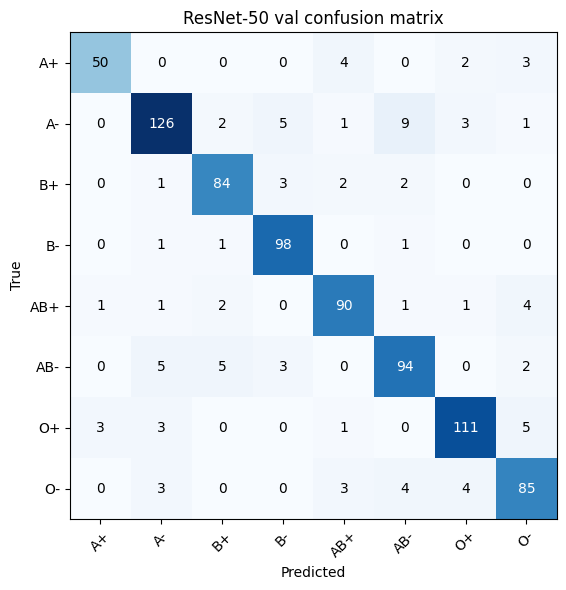

In [ ]:
# ===== Phase 7: ResNet-50 validation diagnostics =====
import json, numpy as np, pandas as pd, torch, torch.nn as nn
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms as T
from sklearn.metrics import (confusion_matrix, classification_report,
                             f1_score, balanced_accuracy_score, accuracy_score)

assert torch.cuda.is_available(), "CUDA not available"
dev = "cuda"

P = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
CLEAN = Path('/content/data/clean')
assert CLEAN.exists(), "Rebuild /content/data/clean first (D2)"
assert (P/'outputs/checkpoints/resnet50_best.pt').exists(), "Checkpoint missing"

l2i = json.load(open(P/'outputs/label_to_idx.json'))
DISPLAY_ORDER = ['A+','A-','B+','B-','AB+','AB-','O+','O-']
assert set(DISPLAY_ORDER) == set(l2i.keys()), f"label_to_idx mismatch: {l2i}"
idx_to_display = {l2i[l]: l for l in DISPLAY_ORDER}

va = pd.read_csv(P/'splits/val.csv')   # TEST CSV NOT LOADED
print(f"Val set: {len(va)} images")

# C1 preprocessing, no augmentation — matches the training cell exactly
rs = T.Resize((224, 224))              # same call as Phase 6
norm = T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
tf_eval = T.Compose([rs, T.ToTensor(), norm])

class DS(Dataset):
    def __init__(s, df, tf): s.df, s.tf = df.reset_index(drop=True), tf
    def __len__(s): return len(s.df)
    def __getitem__(s, i):
        r = s.df.iloc[i]
        return s.tf(Image.open(CLEAN/r['path']).convert('RGB')), l2i[r['label']]

dl_va = DataLoader(DS(va, tf_eval), 64, shuffle=False, num_workers=2)

# Build model + load checkpoint (weights=None; state_dict overwrites everything)
model = models.resnet50(weights=None)
model.fc = nn.Linear(model.fc.in_features, 8)
sd = torch.load(P/'outputs/checkpoints/resnet50_best.pt', map_location=dev)
model.load_state_dict(sd)
model = model.to(dev).eval()
print("Checkpoint loaded.")

ys, ps = [], []
with torch.no_grad():
    for x, y in dl_va:
        out = model(x.to(dev))
        ys += y.tolist()
        ps += out.argmax(1).cpu().tolist()

ys_str = np.array([idx_to_display[i] for i in ys])
ps_str = np.array([idx_to_display[i] for i in ps])

acc  = accuracy_score(ys_str, ps_str)
mf1  = f1_score(ys_str, ps_str, average='macro')
bacc = balanced_accuracy_score(ys_str, ps_str)

print("\n" + "="*50)
print(f"Validation accuracy:   {acc:.4f}")
print(f"Validation macro-F1:   {mf1:.4f}")
print(f"Validation bal. acc:   {bacc:.4f}")
print("="*50)

cm = confusion_matrix(ys_str, ps_str, labels=DISPLAY_ORDER)
cm_df = pd.DataFrame(cm, index=[f"true_{l}" for l in DISPLAY_ORDER],
                        columns=[f"pred_{l}" for l in DISPLAY_ORDER])
print("\nConfusion matrix (rows=true, cols=pred):")
print(cm_df.to_string())

report = classification_report(ys_str, ps_str, labels=DISPLAY_ORDER,
                                output_dict=True, zero_division=0)
per_class = pd.DataFrame({
    'class':     DISPLAY_ORDER,
    'precision': [report[l]['precision'] for l in DISPLAY_ORDER],
    'recall':    [report[l]['recall'] for l in DISPLAY_ORDER],
    'f1':        [report[l]['f1-score'] for l in DISPLAY_ORDER],
    'support':   [int(report[l]['support']) for l in DISPLAY_ORDER],
})
print("\nPer-class (val):")
print(per_class.to_string(index=False))

cm_off = cm.copy(); np.fill_diagonal(cm_off, 0)
confs = [(DISPLAY_ORDER[i], DISPLAY_ORDER[j], int(cm_off[i,j]))
         for i in range(8) for j in range(8) if i != j and cm_off[i,j] > 0]
confs.sort(key=lambda t: -t[2])
print("\nTop confusions (true -> predicted, count):")
for t, p, n in confs[:8]:
    print(f"  true {t} -> pred {p}: {n}")

OUT = P/'outputs'
cm_df.to_csv(OUT/'phase7_resnet50_val_confusion_matrix.csv')
per_class.to_csv(OUT/'phase7_resnet50_val_per_class.csv', index=False)
pd.DataFrame([dict(model='resnet50', seed=42, n_val=len(ys_str),
                   accuracy=acc, macro_f1=mf1, balanced_accuracy=bacc)]).to_csv(
    OUT/'phase7_resnet50_val_summary.csv', index=False)

try:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(7,6))
    ax.imshow(cm, cmap='Blues')
    ax.set_xticks(range(8)); ax.set_yticks(range(8))
    ax.set_xticklabels(DISPLAY_ORDER, rotation=45)
    ax.set_yticklabels(DISPLAY_ORDER)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    for i in range(8):
        for j in range(8):
            ax.text(j, i, cm[i,j], ha='center', va='center',
                    color='white' if cm[i,j] > cm.max()/2 else 'black')
    plt.title('ResNet-50 val confusion matrix')
    plt.tight_layout()
    plt.savefig(OUT/'phase7_resnet50_val_confusion_matrix.png', dpi=150)
    print("\nSaved confusion-matrix plot.")
except Exception as e:
    print(f"(plot skipped: {e})")

print("\nAll outputs saved to:", OUT)

In [ ]:
# ===== STEP 1: save R1 (ResNet-50 seed 42) per-image val predictions =====
import json, numpy as np, pandas as pd, torch, torch.nn as nn
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms as T

assert torch.cuda.is_available(), "CUDA not available"
dev = "cuda"

P = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
CLEAN = Path('/content/data/clean')
CK    = P/'outputs'/'checkpoints'
assert (CK/'resnet50_best.pt').exists(), "R1 checkpoint not found"

l2i = json.load(open(P/'outputs/label_to_idx.json'))
va  = pd.read_csv(P/'splits/val.csv')      # TEST CSV NOT loaded

rs   = T.Resize((224, 224))
norm = T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
tf_eval = T.Compose([rs, T.ToTensor(), norm])

class DS(Dataset):
    def __init__(s, df, tf): s.df, s.tf = df.reset_index(drop=True), tf
    def __len__(s): return len(s.df)
    def __getitem__(s, i):
        r = s.df.iloc[i]
        return s.tf(Image.open(CLEAN/r['path']).convert('RGB')), l2i[r['label']]

dl_va = DataLoader(DS(va, tf_eval), 64, shuffle=False, num_workers=2)

model = models.resnet50(weights=None)
model.fc = nn.Linear(model.fc.in_features, 8)
model.load_state_dict(torch.load(CK/'resnet50_best.pt', map_location=dev))
model = model.to(dev).eval()

ys, ps, probs = [], [], []
with torch.no_grad():
    for x, y in dl_va:
        out = model(x.to(dev))
        probs.append(torch.softmax(out, dim=1).cpu().numpy())
        ys += y.tolist()
        ps += out.argmax(1).cpu().tolist()

probs = np.concatenate(probs, axis=0)
out_path = P/'outputs/phase7_resnet50_seed42_val_preds.npz'
np.savez(out_path, probs=probs, y_true_idx=np.array(ys), y_pred_idx=np.array(ps),
         paths=va['path'].values, label_order=np.array(list(l2i.keys())))

print("Saved:", out_path)
print("probs shape:", probs.shape)
print("val accuracy:", float(np.mean(np.array(ys)==np.array(ps))))

Saved: /content/drive/MyDrive/ML Fingerprint BloodGroup Project/outputs/phase7_resnet50_seed42_val_preds.npz
probs shape: (830, 8)
val accuracy: 0.8891566265060241


In [ ]:
# ===== STEP 2: rename R1 artifacts to seed-tagged names =====
from pathlib import Path

P   = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
CK  = P/'outputs'/'checkpoints'
OUT = P/'outputs'

moves = [
    (CK/'resnet50_best.pt',      CK/'resnet50_seed42_best.pt'),
    (OUT/'resnet50_train_log.csv', OUT/'resnet50_seed42_train_log.csv'),
]

for src, dst in moves:
    if not src.exists():
        print(f"SKIP (source missing): {src.name}")
        continue
    if dst.exists():
        print(f"SKIP (destination exists, not overwriting): {dst.name}")
        continue
    src.rename(dst)
    print(f"Renamed: {src.name} -> {dst.name}")

print("\nCurrent ResNet-50 checkpoints on Drive:")
for f in sorted(CK.glob('resnet50*')):
    print(" ", f.name, f"({f.stat().st_size/1e6:.1f} MB)")

print("\nCurrent ResNet-50 logs on Drive:")
for f in sorted(OUT.glob('resnet50*train_log.csv')):
    print(" ", f.name)

Renamed: resnet50_best.pt -> resnet50_seed42_best.pt
Renamed: resnet50_train_log.csv -> resnet50_seed42_train_log.csv

Current ResNet-50 checkpoints on Drive:
  resnet50_seed42_best.pt (94.4 MB)

Current ResNet-50 logs on Drive:
  resnet50_seed42_train_log.csv


In [ ]:
# ===== STEP 3: R2 = ResNet-50, seed 43 (identical recipe to R1) =====
import json, random, time, numpy as np, pandas as pd, torch, torch.nn as nn
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms as T
from sklearn.metrics import f1_score

BACKBONE = "resnet50"
SEED, BS = 43, 32                              # <-- R2 seed
HEAD_EP, FT_EP, PATIENCE = 3, 27, 8

assert torch.cuda.is_available(), "CUDA not available"
dev = "cuda"
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

P     = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
CLEAN = Path('/content/data/clean')
CK    = P/'outputs'/'checkpoints'; CK.mkdir(parents=True, exist_ok=True)
assert CLEAN.exists(), "Rebuild /content/data/clean first (D2)"

l2i = json.load(open(P/'outputs/label_to_idx.json'))
tr  = pd.read_csv(P/'splits/train.csv')
va  = pd.read_csv(P/'splits/val.csv')          # TEST CSV NOT loaded

rs   = T.Resize((224, 224))
norm = T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
tf_train = T.Compose([rs, T.RandomAffine(10, translate=(0.05,0.05), scale=(0.95,1.05), fill=255),
                      T.ColorJitter(0.1, 0.1), T.ToTensor(), norm])
tf_eval  = T.Compose([rs, T.ToTensor(), norm])

class DS(Dataset):
    def __init__(s, df, tf): s.df, s.tf = df.reset_index(drop=True), tf
    def __len__(s): return len(s.df)
    def __getitem__(s, i):
        r = s.df.iloc[i]
        return s.tf(Image.open(CLEAN/r['path']).convert('RGB')), l2i[r['label']]

g = torch.Generator().manual_seed(SEED)
dl_tr = DataLoader(DS(tr, tf_train), BS, shuffle=True, num_workers=2, generator=g, drop_last=True)
dl_va = DataLoader(DS(va, tf_eval), BS*2, shuffle=False, num_workers=2)

model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
model.fc = nn.Linear(model.fc.in_features, 8)
head = model.fc
model = model.to(dev)

cw    = torch.load(P/'outputs/class_weights.pt').float().to(dev)
crit  = nn.CrossEntropyLoss(weight=cw, label_smoothing=0.1)
scaler = torch.amp.GradScaler("cuda")          # fixed deprecation warning

def run_epoch(loader, opt=None):
    train = opt is not None
    model.train(train); ys, ps, tot = [], [], 0.0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(dev), y.to(dev)
            with torch.autocast("cuda", dtype=torch.float16):
                out = model(x); loss = crit(out, y)
            if train:
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item()*len(y); ys += y.tolist(); ps += out.argmax(1).tolist()
    return tot/len(ys), float(np.mean(np.array(ys)==np.array(ps))), f1_score(ys, ps, average='macro')

log, best, bad = [], -1, 0
ckpt_path = CK/f'{BACKBONE}_seed{SEED}_best.pt'   # <-- R2 filename
log_path  = P/f'outputs/{BACKBONE}_seed{SEED}_train_log.csv'

def fit(epochs, opt, sched, stage):
    global best, bad
    for ep in range(epochs):
        t0 = time.time()
        trl, tra, trf = run_epoch(dl_tr, opt)
        val, vaa, vaf = run_epoch(dl_va)
        if sched: sched.step()
        log.append(dict(stage=stage, ep=ep+1, tr_loss=trl, tr_acc=tra, tr_f1=trf,
                        va_loss=val, va_acc=vaa, va_f1=vaf))
        print(f"[{stage}] {ep+1:02d} tr_acc {tra:.3f} va_acc {vaa:.3f} va_F1 {vaf:.3f} ({time.time()-t0:.0f}s)")
        if vaf > best:
            best, bad = vaf, 0
            torch.save(model.state_dict(), ckpt_path)
        elif stage == "full":
            bad += 1
            if bad >= PATIENCE: print("Early stop"); return
        pd.DataFrame(log).to_csv(log_path, index=False)

# Stage 1: head only
for p in model.parameters(): p.requires_grad = False
for p in head.parameters():  p.requires_grad = True
fit(HEAD_EP, torch.optim.AdamW(head.parameters(), lr=1e-3, weight_decay=1e-4), None, "head")

# Stage 2: full fine-tune
for p in model.parameters(): p.requires_grad = True
opt = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
fit(FT_EP, opt, torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=FT_EP, eta_min=1e-6), "full")

pd.DataFrame(log).to_csv(log_path, index=False)
print(f"\nBest val macro-F1: {best:.4f}  |  checkpoint: {ckpt_path.name}  |  log: {log_path.name}")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 101MB/s] 


[head] 01 tr_acc 0.335 va_acc 0.361 va_F1 0.335 (24s)
[head] 02 tr_acc 0.463 va_acc 0.404 va_F1 0.392 (20s)
[head] 03 tr_acc 0.507 va_acc 0.433 va_F1 0.431 (19s)
[full] 01 tr_acc 0.691 va_acc 0.811 va_F1 0.813 (26s)
[full] 02 tr_acc 0.805 va_acc 0.840 va_F1 0.839 (26s)
[full] 03 tr_acc 0.844 va_acc 0.843 va_F1 0.847 (25s)
[full] 04 tr_acc 0.872 va_acc 0.848 va_F1 0.849 (26s)
[full] 05 tr_acc 0.890 va_acc 0.836 va_F1 0.838 (26s)
[full] 06 tr_acc 0.910 va_acc 0.845 va_F1 0.845 (23s)
[full] 07 tr_acc 0.916 va_acc 0.824 va_F1 0.827 (25s)
[full] 08 tr_acc 0.932 va_acc 0.841 va_F1 0.843 (24s)
[full] 09 tr_acc 0.955 va_acc 0.841 va_F1 0.842 (23s)
[full] 10 tr_acc 0.958 va_acc 0.855 va_F1 0.855 (24s)
[full] 11 tr_acc 0.966 va_acc 0.855 va_F1 0.858 (26s)
[full] 12 tr_acc 0.975 va_acc 0.859 va_F1 0.861 (24s)
[full] 13 tr_acc 0.978 va_acc 0.855 va_F1 0.858 (26s)
[full] 14 tr_acc 0.982 va_acc 0.831 va_F1 0.835 (24s)
[full] 15 tr_acc 0.982 va_acc 0.852 va_F1 0.854 (23s)
[full] 16 tr_acc 0.990 va_ac

In [ ]:
# ===== STEP 4: R3 = ResNet-50, seed 44 (identical recipe to R1/R2) =====
import json, random, time, numpy as np, pandas as pd, torch, torch.nn as nn
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms as T
from sklearn.metrics import f1_score

BACKBONE = "resnet50"
SEED, BS = 44, 32                              # <-- R3 seed (only change)
HEAD_EP, FT_EP, PATIENCE = 3, 27, 8

assert torch.cuda.is_available(), "CUDA not available"
dev = "cuda"
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

P     = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
CLEAN = Path('/content/data/clean')
CK    = P/'outputs'/'checkpoints'; CK.mkdir(parents=True, exist_ok=True)
assert CLEAN.exists(), "Rebuild /content/data/clean first (D2)"

l2i = json.load(open(P/'outputs/label_to_idx.json'))
tr  = pd.read_csv(P/'splits/train.csv')
va  = pd.read_csv(P/'splits/val.csv')          # TEST CSV NOT loaded

rs   = T.Resize((224, 224))
norm = T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
tf_train = T.Compose([rs, T.RandomAffine(10, translate=(0.05,0.05), scale=(0.95,1.05), fill=255),
                      T.ColorJitter(0.1, 0.1), T.ToTensor(), norm])
tf_eval  = T.Compose([rs, T.ToTensor(), norm])

class DS(Dataset):
    def __init__(s, df, tf): s.df, s.tf = df.reset_index(drop=True), tf
    def __len__(s): return len(s.df)
    def __getitem__(s, i):
        r = s.df.iloc[i]
        return s.tf(Image.open(CLEAN/r['path']).convert('RGB')), l2i[r['label']]

g = torch.Generator().manual_seed(SEED)
dl_tr = DataLoader(DS(tr, tf_train), BS, shuffle=True, num_workers=2, generator=g, drop_last=True)
dl_va = DataLoader(DS(va, tf_eval), BS*2, shuffle=False, num_workers=2)

model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
model.fc = nn.Linear(model.fc.in_features, 8)
head = model.fc
model = model.to(dev)

cw     = torch.load(P/'outputs/class_weights.pt').float().to(dev)
crit   = nn.CrossEntropyLoss(weight=cw, label_smoothing=0.1)
scaler = torch.amp.GradScaler("cuda")

def run_epoch(loader, opt=None):
    train = opt is not None
    model.train(train); ys, ps, tot = [], [], 0.0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(dev), y.to(dev)
            with torch.autocast("cuda", dtype=torch.float16):
                out = model(x); loss = crit(out, y)
            if train:
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item()*len(y); ys += y.tolist(); ps += out.argmax(1).tolist()
    return tot/len(ys), float(np.mean(np.array(ys)==np.array(ps))), f1_score(ys, ps, average='macro')

log, best, bad = [], -1, 0
ckpt_path = CK/f'{BACKBONE}_seed{SEED}_best.pt'
log_path  = P/f'outputs/{BACKBONE}_seed{SEED}_train_log.csv'

def fit(epochs, opt, sched, stage):
    global best, bad
    for ep in range(epochs):
        t0 = time.time()
        trl, tra, trf = run_epoch(dl_tr, opt)
        val, vaa, vaf = run_epoch(dl_va)
        if sched: sched.step()
        log.append(dict(stage=stage, ep=ep+1, tr_loss=trl, tr_acc=tra, tr_f1=trf,
                        va_loss=val, va_acc=vaa, va_f1=vaf))
        print(f"[{stage}] {ep+1:02d} tr_acc {tra:.3f} va_acc {vaa:.3f} va_F1 {vaf:.3f} ({time.time()-t0:.0f}s)")
        if vaf > best:
            best, bad = vaf, 0
            torch.save(model.state_dict(), ckpt_path)
        elif stage == "full":
            bad += 1
            if bad >= PATIENCE: print("Early stop"); return
        pd.DataFrame(log).to_csv(log_path, index=False)

for p in model.parameters(): p.requires_grad = False
for p in head.parameters():  p.requires_grad = True
fit(HEAD_EP, torch.optim.AdamW(head.parameters(), lr=1e-3, weight_decay=1e-4), None, "head")

for p in model.parameters(): p.requires_grad = True
opt = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
fit(FT_EP, opt, torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=FT_EP, eta_min=1e-6), "full")

pd.DataFrame(log).to_csv(log_path, index=False)
print(f"\nBest val macro-F1: {best:.4f}  |  checkpoint: {ckpt_path.name}  |  log: {log_path.name}")

[head] 01 tr_acc 0.344 va_acc 0.375 va_F1 0.353 (27s)
[head] 02 tr_acc 0.457 va_acc 0.431 va_F1 0.423 (20s)
[head] 03 tr_acc 0.493 va_acc 0.417 va_F1 0.398 (20s)
[full] 01 tr_acc 0.697 va_acc 0.773 va_F1 0.776 (24s)
[full] 02 tr_acc 0.803 va_acc 0.817 va_F1 0.820 (26s)
[full] 03 tr_acc 0.843 va_acc 0.839 va_F1 0.839 (25s)
[full] 04 tr_acc 0.865 va_acc 0.841 va_F1 0.840 (26s)
[full] 05 tr_acc 0.891 va_acc 0.883 va_F1 0.883 (26s)
[full] 06 tr_acc 0.905 va_acc 0.845 va_F1 0.845 (26s)
[full] 07 tr_acc 0.912 va_acc 0.866 va_F1 0.869 (23s)
[full] 08 tr_acc 0.931 va_acc 0.854 va_F1 0.853 (25s)
[full] 09 tr_acc 0.941 va_acc 0.883 va_F1 0.883 (24s)
[full] 10 tr_acc 0.957 va_acc 0.872 va_F1 0.873 (25s)
[full] 11 tr_acc 0.969 va_acc 0.875 va_F1 0.877 (25s)
[full] 12 tr_acc 0.970 va_acc 0.877 va_F1 0.877 (25s)
[full] 13 tr_acc 0.978 va_acc 0.893 va_F1 0.893 (23s)
[full] 14 tr_acc 0.985 va_acc 0.871 va_F1 0.866 (26s)
[full] 15 tr_acc 0.985 va_acc 0.869 va_F1 0.869 (25s)
[full] 16 tr_acc 0.988 va_ac

In [ ]:
# ===== STEP 5: fp32 Phase-7-style re-eval of R2 and R3, + 3-seed summary =====
import json, numpy as np, pandas as pd, torch, torch.nn as nn
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms as T
from sklearn.metrics import f1_score, balanced_accuracy_score, accuracy_score

assert torch.cuda.is_available(), "CUDA not available"
dev = "cuda"

P     = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
CLEAN = Path('/content/data/clean')
CK    = P/'outputs'/'checkpoints'

l2i = json.load(open(P/'outputs/label_to_idx.json'))
DISPLAY_ORDER = ['A+','A-','B+','B-','AB+','AB-','O+','O-']
idx_to_display = {l2i[l]: l for l in DISPLAY_ORDER}
va = pd.read_csv(P/'splits/val.csv')          # TEST CSV NOT loaded

rs   = T.Resize((224, 224))
norm = T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
tf_eval = T.Compose([rs, T.ToTensor(), norm])

class DS(Dataset):
    def __init__(s, df, tf): s.df, s.tf = df.reset_index(drop=True), tf
    def __len__(s): return len(s.df)
    def __getitem__(s, i):
        r = s.df.iloc[i]
        return s.tf(Image.open(CLEAN/r['path']).convert('RGB')), l2i[r['label']]

dl_va = DataLoader(DS(va, tf_eval), 64, shuffle=False, num_workers=2)

def eval_seed(seed):
    ckpt = CK/f'resnet50_seed{seed}_best.pt'
    assert ckpt.exists(), f"missing {ckpt.name}"
    m = models.resnet50(weights=None)
    m.fc = nn.Linear(m.fc.in_features, 8)
    m.load_state_dict(torch.load(ckpt, map_location=dev))
    m = m.to(dev).eval()

    ys, ps, probs = [], [], []
    with torch.no_grad():
        for x, y in dl_va:
            out = m(x.to(dev))
            probs.append(torch.softmax(out, dim=1).cpu().numpy())
            ys += y.tolist()
            ps += out.argmax(1).cpu().tolist()
    probs = np.concatenate(probs, axis=0)

    ys_str = np.array([idx_to_display[i] for i in ys])
    ps_str = np.array([idx_to_display[i] for i in ps])
    acc  = accuracy_score(ys_str, ps_str)
    mf1  = f1_score(ys_str, ps_str, average='macro')
    bacc = balanced_accuracy_score(ys_str, ps_str)

    np.savez(P/f'outputs/phase7_resnet50_seed{seed}_val_preds.npz',
             probs=probs, y_true_idx=np.array(ys), y_pred_idx=np.array(ps),
             paths=va['path'].values, label_order=np.array(list(l2i.keys())))
    return acc, mf1, bacc

# --- R2 and R3 (R1 was already done in Step 1) ---
results = {'42': (0.8892, 0.8892, 0.8889)}  # from Phase 7 recompute; sanity-checked in Step 1
for seed in (43, 44):
    acc, mf1, bacc = eval_seed(seed)
    results[str(seed)] = (acc, mf1, bacc)
    print(f"seed {seed}: acc={acc:.4f}  macro_f1={mf1:.4f}  bal_acc={bacc:.4f}")

mf1s = np.array([results[s][1] for s in ('42','43','44')])
mean = mf1s.mean()
sd_sample = mf1s.std(ddof=1)   # sample SD (standard for n=3 seeds)
sd_pop    = mf1s.std(ddof=0)
print("\n3-seed val macro-F1:")
print(f"  per seed : 42={mf1s[0]:.4f}  43={mf1s[1]:.4f}  44={mf1s[2]:.4f}")
print(f"  mean     : {mean:.4f}")
print(f"  SD (n-1) : {sd_sample:.4f}   <-- use this as the noise floor")
print(f"  SD (n)   : {sd_pop:.4f}")
print(f"  range    : [{mf1s.min():.4f}, {mf1s.max():.4f}]")
print(f"  'better than noise' bar (Section 5) = max(0.5pp, 1 SD) "
      f"= {max(0.005, sd_sample):.4f}")

seed 43: acc=0.8759  macro_f1=0.8765  bal_acc=0.8761
seed 44: acc=0.8916  macro_f1=0.8928  bal_acc=0.8956

3-seed val macro-F1:
  per seed : 42=0.8892  43=0.8765  44=0.8928
  mean     : 0.8862
  SD (n-1) : 0.0085   <-- use this as the noise floor
  SD (n)   : 0.0070
  range    : [0.8765, 0.8928]
  'better than noise' bar (Section 5) = max(0.5pp, 1 SD) = 0.0085


In [ ]:
# ===== STEP 6: EfficientNet-B0, seed 42 =====
import json, random, time, numpy as np, pandas as pd, torch, torch.nn as nn
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms as T
from sklearn.metrics import f1_score

BACKBONE = "efficientnet_b0"
SEED, BS = 42, 32
HEAD_EP, FT_EP, PATIENCE = 3, 27, 8

assert torch.cuda.is_available(), "CUDA not available"
dev = "cuda"
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

P     = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
CLEAN = Path('/content/data/clean')
CK    = P/'outputs'/'checkpoints'; CK.mkdir(parents=True, exist_ok=True)
assert CLEAN.exists(), "Rebuild /content/data/clean first (D2)"

l2i = json.load(open(P/'outputs/label_to_idx.json'))
tr  = pd.read_csv(P/'splits/train.csv')
va  = pd.read_csv(P/'splits/val.csv')          # TEST CSV NOT loaded

rs   = T.Resize((224, 224))
norm = T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
tf_train = T.Compose([rs, T.RandomAffine(10, translate=(0.05,0.05), scale=(0.95,1.05), fill=255),
                      T.ColorJitter(0.1, 0.1), T.ToTensor(), norm])
tf_eval  = T.Compose([rs, T.ToTensor(), norm])

class DS(Dataset):
    def __init__(s, df, tf): s.df, s.tf = df.reset_index(drop=True), tf
    def __len__(s): return len(s.df)
    def __getitem__(s, i):
        r = s.df.iloc[i]
        return s.tf(Image.open(CLEAN/r['path']).convert('RGB')), l2i[r['label']]

g = torch.Generator().manual_seed(SEED)
dl_tr = DataLoader(DS(tr, tf_train), BS, shuffle=True, num_workers=2, generator=g, drop_last=True)
dl_va = DataLoader(DS(va, tf_eval), BS*2, shuffle=False, num_workers=2)

# --- EfficientNet-B0 build (the only structural change vs ResNet cell) ---
model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, 8)
head = model.classifier
model = model.to(dev)

cw     = torch.load(P/'outputs/class_weights.pt').float().to(dev)
crit   = nn.CrossEntropyLoss(weight=cw, label_smoothing=0.1)
scaler = torch.amp.GradScaler("cuda")

def run_epoch(loader, opt=None):
    train = opt is not None
    model.train(train); ys, ps, tot = [], [], 0.0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(dev), y.to(dev)
            with torch.autocast("cuda", dtype=torch.float16):
                out = model(x); loss = crit(out, y)
            if train:
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item()*len(y); ys += y.tolist(); ps += out.argmax(1).tolist()
    return tot/len(ys), float(np.mean(np.array(ys)==np.array(ps))), f1_score(ys, ps, average='macro')

log, best, bad = [], -1, 0
ckpt_path = CK/f'{BACKBONE}_seed{SEED}_best.pt'
log_path  = P/f'outputs/{BACKBONE}_seed{SEED}_train_log.csv'

def fit(epochs, opt, sched, stage):
    global best, bad
    for ep in range(epochs):
        t0 = time.time()
        trl, tra, trf = run_epoch(dl_tr, opt)
        val, vaa, vaf = run_epoch(dl_va)
        if sched: sched.step()
        log.append(dict(stage=stage, ep=ep+1, tr_loss=trl, tr_acc=tra, tr_f1=trf,
                        va_loss=val, va_acc=vaa, va_f1=vaf))
        print(f"[{stage}] {ep+1:02d} tr_acc {tra:.3f} va_acc {vaa:.3f} va_F1 {vaf:.3f} ({time.time()-t0:.0f}s)")
        if vaf > best:
            best, bad = vaf, 0
            torch.save(model.state_dict(), ckpt_path)
        elif stage == "full":
            bad += 1
            if bad >= PATIENCE: print("Early stop"); return
        pd.DataFrame(log).to_csv(log_path, index=False)

for p in model.parameters(): p.requires_grad = False
for p in head.parameters():  p.requires_grad = True
fit(HEAD_EP, torch.optim.AdamW(head.parameters(), lr=1e-3, weight_decay=1e-4), None, "head")

for p in model.parameters(): p.requires_grad = True
opt = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
fit(FT_EP, opt, torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=FT_EP, eta_min=1e-6), "full")

pd.DataFrame(log).to_csv(log_path, index=False)
print(f"\nBest val macro-F1: {best:.4f}  |  checkpoint: {ckpt_path.name}  |  log: {log_path.name}")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 42.8MB/s]


[head] 01 tr_acc 0.370 va_acc 0.469 va_F1 0.454 (35s)
[head] 02 tr_acc 0.482 va_acc 0.501 va_F1 0.486 (26s)
[head] 03 tr_acc 0.514 va_acc 0.541 va_F1 0.531 (22s)
[full] 01 tr_acc 0.681 va_acc 0.767 va_F1 0.765 (28s)
[full] 02 tr_acc 0.798 va_acc 0.825 va_F1 0.823 (26s)
[full] 03 tr_acc 0.831 va_acc 0.851 va_F1 0.848 (26s)
[full] 04 tr_acc 0.850 va_acc 0.870 va_F1 0.868 (26s)
[full] 05 tr_acc 0.868 va_acc 0.871 va_F1 0.872 (26s)
[full] 06 tr_acc 0.884 va_acc 0.871 va_F1 0.869 (25s)
[full] 07 tr_acc 0.888 va_acc 0.887 va_F1 0.887 (25s)
[full] 08 tr_acc 0.910 va_acc 0.888 va_F1 0.888 (24s)
[full] 09 tr_acc 0.919 va_acc 0.867 va_F1 0.868 (24s)
[full] 10 tr_acc 0.927 va_acc 0.893 va_F1 0.893 (24s)
[full] 11 tr_acc 0.931 va_acc 0.888 va_F1 0.887 (23s)
[full] 12 tr_acc 0.936 va_acc 0.886 va_F1 0.886 (24s)
[full] 13 tr_acc 0.937 va_acc 0.896 va_F1 0.894 (22s)
[full] 14 tr_acc 0.948 va_acc 0.899 va_F1 0.898 (24s)
[full] 15 tr_acc 0.950 va_acc 0.901 va_F1 0.898 (22s)
[full] 16 tr_acc 0.956 va_ac

In [ ]:
# ===== STEP 7: EfficientNet-B0, seed 43 =====
import json, random, time, numpy as np, pandas as pd, torch, torch.nn as nn
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms as T
from sklearn.metrics import f1_score

BACKBONE = "efficientnet_b0"
SEED, BS = 43, 32                              # <-- R43 seed (only change)
HEAD_EP, FT_EP, PATIENCE = 3, 27, 8

assert torch.cuda.is_available(), "CUDA not available"
dev = "cuda"
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

P     = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
CLEAN = Path('/content/data/clean')
CK    = P/'outputs'/'checkpoints'; CK.mkdir(parents=True, exist_ok=True)
assert CLEAN.exists(), "Rebuild /content/data/clean first (D2)"

l2i = json.load(open(P/'outputs/label_to_idx.json'))
tr  = pd.read_csv(P/'splits/train.csv')
va  = pd.read_csv(P/'splits/val.csv')

rs   = T.Resize((224, 224))
norm = T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
tf_train = T.Compose([rs, T.RandomAffine(10, translate=(0.05,0.05), scale=(0.95,1.05), fill=255),
                      T.ColorJitter(0.1, 0.1), T.ToTensor(), norm])
tf_eval  = T.Compose([rs, T.ToTensor(), norm])

class DS(Dataset):
    def __init__(s, df, tf): s.df, s.tf = df.reset_index(drop=True), tf
    def __len__(s): return len(s.df)
    def __getitem__(s, i):
        r = s.df.iloc[i]
        return s.tf(Image.open(CLEAN/r['path']).convert('RGB')), l2i[r['label']]

g = torch.Generator().manual_seed(SEED)
dl_tr = DataLoader(DS(tr, tf_train), BS, shuffle=True, num_workers=2, generator=g, drop_last=True)
dl_va = DataLoader(DS(va, tf_eval), BS*2, shuffle=False, num_workers=2)

model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, 8)
head = model.classifier
model = model.to(dev)

cw     = torch.load(P/'outputs/class_weights.pt').float().to(dev)
crit   = nn.CrossEntropyLoss(weight=cw, label_smoothing=0.1)
scaler = torch.amp.GradScaler("cuda")

def run_epoch(loader, opt=None):
    train = opt is not None
    model.train(train); ys, ps, tot = [], [], 0.0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(dev), y.to(dev)
            with torch.autocast("cuda", dtype=torch.float16):
                out = model(x); loss = crit(out, y)
            if train:
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item()*len(y); ys += y.tolist(); ps += out.argmax(1).tolist()
    return tot/len(ys), float(np.mean(np.array(ys)==np.array(ps))), f1_score(ys, ps, average='macro')

log, best, bad = [], -1, 0
ckpt_path = CK/f'{BACKBONE}_seed{SEED}_best.pt'
log_path  = P/f'outputs/{BACKBONE}_seed{SEED}_train_log.csv'

def fit(epochs, opt, sched, stage):
    global best, bad
    for ep in range(epochs):
        t0 = time.time()
        trl, tra, trf = run_epoch(dl_tr, opt)
        val, vaa, vaf = run_epoch(dl_va)
        if sched: sched.step()
        log.append(dict(stage=stage, ep=ep+1, tr_loss=trl, tr_acc=tra, tr_f1=trf,
                        va_loss=val, va_acc=vaa, va_f1=vaf))
        print(f"[{stage}] {ep+1:02d} tr_acc {tra:.3f} va_acc {vaa:.3f} va_F1 {vaf:.3f} ({time.time()-t0:.0f}s)")
        if vaf > best:
            best, bad = vaf, 0
            torch.save(model.state_dict(), ckpt_path)
        elif stage == "full":
            bad += 1
            if bad >= PATIENCE: print("Early stop"); return
        pd.DataFrame(log).to_csv(log_path, index=False)

for p in model.parameters(): p.requires_grad = False
for p in head.parameters():  p.requires_grad = True
fit(HEAD_EP, torch.optim.AdamW(head.parameters(), lr=1e-3, weight_decay=1e-4), None, "head")

for p in model.parameters(): p.requires_grad = True
opt = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
fit(FT_EP, opt, torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=FT_EP, eta_min=1e-6), "full")

pd.DataFrame(log).to_csv(log_path, index=False)
print(f"\nBest val macro-F1: {best:.4f}  |  checkpoint: {ckpt_path.name}  |  log: {log_path.name}")

[head] 01 tr_acc 0.378 va_acc 0.477 va_F1 0.467 (35s)
[head] 02 tr_acc 0.493 va_acc 0.540 va_F1 0.533 (21s)
[head] 03 tr_acc 0.521 va_acc 0.555 va_F1 0.547 (19s)
[full] 01 tr_acc 0.678 va_acc 0.782 va_F1 0.782 (22s)
[full] 02 tr_acc 0.787 va_acc 0.827 va_F1 0.825 (26s)
[full] 03 tr_acc 0.830 va_acc 0.852 va_F1 0.852 (24s)
[full] 04 tr_acc 0.851 va_acc 0.847 va_F1 0.846 (23s)
[full] 05 tr_acc 0.862 va_acc 0.872 va_F1 0.871 (24s)
[full] 06 tr_acc 0.887 va_acc 0.871 va_F1 0.872 (24s)
[full] 07 tr_acc 0.892 va_acc 0.884 va_F1 0.884 (23s)
[full] 08 tr_acc 0.899 va_acc 0.888 va_F1 0.889 (25s)
[full] 09 tr_acc 0.913 va_acc 0.886 va_F1 0.887 (24s)
[full] 10 tr_acc 0.923 va_acc 0.873 va_F1 0.874 (23s)
[full] 11 tr_acc 0.938 va_acc 0.902 va_F1 0.902 (24s)
[full] 12 tr_acc 0.940 va_acc 0.884 va_F1 0.885 (23s)
[full] 13 tr_acc 0.934 va_acc 0.889 va_F1 0.888 (24s)
[full] 14 tr_acc 0.948 va_acc 0.888 va_F1 0.888 (23s)
[full] 15 tr_acc 0.953 va_acc 0.890 va_F1 0.890 (24s)
[full] 16 tr_acc 0.956 va_ac

In [ ]:
# ===== STEP 8: EfficientNet-B0, seed 44 =====
import json, random, time, numpy as np, pandas as pd, torch, torch.nn as nn
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms as T
from sklearn.metrics import f1_score

BACKBONE = "efficientnet_b0"
SEED, BS = 44, 32                              # <-- only change
HEAD_EP, FT_EP, PATIENCE = 3, 27, 8

assert torch.cuda.is_available(), "CUDA not available"
dev = "cuda"
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

P     = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
CLEAN = Path('/content/data/clean')
CK    = P/'outputs'/'checkpoints'; CK.mkdir(parents=True, exist_ok=True)
assert CLEAN.exists(), "Rebuild /content/data/clean first (D2)"

l2i = json.load(open(P/'outputs/label_to_idx.json'))
tr  = pd.read_csv(P/'splits/train.csv')
va  = pd.read_csv(P/'splits/val.csv')

rs   = T.Resize((224, 224))
norm = T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
tf_train = T.Compose([rs, T.RandomAffine(10, translate=(0.05,0.05), scale=(0.95,1.05), fill=255),
                      T.ColorJitter(0.1, 0.1), T.ToTensor(), norm])
tf_eval  = T.Compose([rs, T.ToTensor(), norm])

class DS(Dataset):
    def __init__(s, df, tf): s.df, s.tf = df.reset_index(drop=True), tf
    def __len__(s): return len(s.df)
    def __getitem__(s, i):
        r = s.df.iloc[i]
        return s.tf(Image.open(CLEAN/r['path']).convert('RGB')), l2i[r['label']]

g = torch.Generator().manual_seed(SEED)
dl_tr = DataLoader(DS(tr, tf_train), BS, shuffle=True, num_workers=2, generator=g, drop_last=True)
dl_va = DataLoader(DS(va, tf_eval), BS*2, shuffle=False, num_workers=2)

model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, 8)
head = model.classifier
model = model.to(dev)

cw     = torch.load(P/'outputs/class_weights.pt').float().to(dev)
crit   = nn.CrossEntropyLoss(weight=cw, label_smoothing=0.1)
scaler = torch.amp.GradScaler("cuda")

def run_epoch(loader, opt=None):
    train = opt is not None
    model.train(train); ys, ps, tot = [], [], 0.0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(dev), y.to(dev)
            with torch.autocast("cuda", dtype=torch.float16):
                out = model(x); loss = crit(out, y)
            if train:
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item()*len(y); ys += y.tolist(); ps += out.argmax(1).tolist()
    return tot/len(ys), float(np.mean(np.array(ys)==np.array(ps))), f1_score(ys, ps, average='macro')

log, best, bad = [], -1, 0
ckpt_path = CK/f'{BACKBONE}_seed{SEED}_best.pt'
log_path  = P/f'outputs/{BACKBONE}_seed{SEED}_train_log.csv'

def fit(epochs, opt, sched, stage):
    global best, bad
    for ep in range(epochs):
        t0 = time.time()
        trl, tra, trf = run_epoch(dl_tr, opt)
        val, vaa, vaf = run_epoch(dl_va)
        if sched: sched.step()
        log.append(dict(stage=stage, ep=ep+1, tr_loss=trl, tr_acc=tra, tr_f1=trf,
                        va_loss=val, va_acc=vaa, va_f1=vaf))
        print(f"[{stage}] {ep+1:02d} tr_acc {tra:.3f} va_acc {vaa:.3f} va_F1 {vaf:.3f} ({time.time()-t0:.0f}s)")
        if vaf > best:
            best, bad = vaf, 0
            torch.save(model.state_dict(), ckpt_path)
        elif stage == "full":
            bad += 1
            if bad >= PATIENCE: print("Early stop"); return
        pd.DataFrame(log).to_csv(log_path, index=False)

for p in model.parameters(): p.requires_grad = False
for p in head.parameters():  p.requires_grad = True
fit(HEAD_EP, torch.optim.AdamW(head.parameters(), lr=1e-3, weight_decay=1e-4), None, "head")

for p in model.parameters(): p.requires_grad = True
opt = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
fit(FT_EP, opt, torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=FT_EP, eta_min=1e-6), "full")

pd.DataFrame(log).to_csv(log_path, index=False)
print(f"\nBest val macro-F1: {best:.4f}  |  checkpoint: {ckpt_path.name}  |  log: {log_path.name}")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 117MB/s]


[head] 01 tr_acc 0.380 va_acc 0.492 va_F1 0.489 (32s)
[head] 02 tr_acc 0.482 va_acc 0.546 va_F1 0.541 (20s)
[head] 03 tr_acc 0.520 va_acc 0.534 va_F1 0.526 (19s)
[full] 01 tr_acc 0.675 va_acc 0.771 va_F1 0.771 (26s)
[full] 02 tr_acc 0.797 va_acc 0.822 va_F1 0.819 (22s)
[full] 03 tr_acc 0.834 va_acc 0.842 va_F1 0.844 (24s)
[full] 04 tr_acc 0.852 va_acc 0.854 va_F1 0.856 (23s)
[full] 05 tr_acc 0.868 va_acc 0.880 va_F1 0.878 (24s)
[full] 06 tr_acc 0.887 va_acc 0.883 va_F1 0.884 (24s)
[full] 07 tr_acc 0.901 va_acc 0.884 va_F1 0.887 (23s)
[full] 08 tr_acc 0.898 va_acc 0.883 va_F1 0.885 (24s)
[full] 09 tr_acc 0.911 va_acc 0.887 va_F1 0.884 (22s)
[full] 10 tr_acc 0.923 va_acc 0.893 va_F1 0.893 (24s)
[full] 11 tr_acc 0.940 va_acc 0.895 va_F1 0.894 (24s)
[full] 12 tr_acc 0.938 va_acc 0.898 va_F1 0.896 (23s)
[full] 13 tr_acc 0.944 va_acc 0.889 va_F1 0.889 (24s)
[full] 14 tr_acc 0.954 va_acc 0.896 va_F1 0.896 (22s)
[full] 15 tr_acc 0.949 va_acc 0.892 va_F1 0.891 (24s)
[full] 16 tr_acc 0.954 va_ac

In [ ]:
# ===== STEP 9: fp32 re-eval all 3 EfficientNet-B0 seeds + side-by-side summary =====
import json, numpy as np, pandas as pd, torch, torch.nn as nn
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms as T
from sklearn.metrics import f1_score, balanced_accuracy_score, accuracy_score

assert torch.cuda.is_available(), "CUDA not available"
dev = "cuda"

P     = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
CLEAN = Path('/content/data/clean')
CK    = P/'outputs'/'checkpoints'

l2i = json.load(open(P/'outputs/label_to_idx.json'))
DISPLAY_ORDER = ['A+','A-','B+','B-','AB+','AB-','O+','O-']
idx_to_display = {l2i[l]: l for l in DISPLAY_ORDER}
va = pd.read_csv(P/'splits/val.csv')          # TEST CSV NOT loaded

rs   = T.Resize((224, 224))
norm = T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
tf_eval = T.Compose([rs, T.ToTensor(), norm])

class DS(Dataset):
    def __init__(s, df, tf): s.df, s.tf = df.reset_index(drop=True), tf
    def __len__(s): return len(s.df)
    def __getitem__(s, i):
        r = s.df.iloc[i]
        return s.tf(Image.open(CLEAN/r['path']).convert('RGB')), l2i[r['label']]

dl_va = DataLoader(DS(va, tf_eval), 64, shuffle=False, num_workers=2)

def build_model(backbone):
    if backbone == "resnet50":
        m = models.resnet50(weights=None)
        m.fc = nn.Linear(m.fc.in_features, 8)
    elif backbone == "efficientnet_b0":
        m = models.efficientnet_b0(weights=None)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, 8)
    else:
        raise ValueError(backbone)
    return m

def eval_seed(backbone, seed):
    ckpt = CK/f'{backbone}_seed{seed}_best.pt'
    assert ckpt.exists(), f"missing {ckpt.name}"
    m = build_model(backbone)
    m.load_state_dict(torch.load(ckpt, map_location=dev))
    m = m.to(dev).eval()

    ys, ps, probs = [], [], []
    with torch.no_grad():
        for x, y in dl_va:
            out = m(x.to(dev))
            probs.append(torch.softmax(out, dim=1).cpu().numpy())
            ys += y.tolist()
            ps += out.argmax(1).cpu().tolist()
    probs = np.concatenate(probs, axis=0)

    ys_str = np.array([idx_to_display[i] for i in ys])
    ps_str = np.array([idx_to_display[i] for i in ps])
    acc  = accuracy_score(ys_str, ps_str)
    mf1  = f1_score(ys_str, ps_str, average='macro')
    bacc = balanced_accuracy_score(ys_str, ps_str)

    np.savez(P/f'outputs/phase7_{backbone}_seed{seed}_val_preds.npz',
             probs=probs, y_true_idx=np.array(ys), y_pred_idx=np.array(ps),
             paths=va['path'].values, label_order=np.array(list(l2i.keys())))
    return acc, mf1, bacc

# EfficientNet-B0 3 seeds in fp32
results_e = {}
for seed in (42, 43, 44):
    acc, mf1, bacc = eval_seed('efficientnet_b0', seed)
    results_e[seed] = (acc, mf1, bacc)
    print(f"[efficientnet_b0 seed {seed}] acc={acc:.4f}  macro_f1={mf1:.4f}  bal_acc={bacc:.4f}")

# ResNet-50 3 seeds — re-evaluated here so the table is apples-to-apples, from same code path
results_r = {}
for seed in (42, 43, 44):
    acc, mf1, bacc = eval_seed('resnet50', seed)
    results_r[seed] = (acc, mf1, bacc)
    print(f"[resnet50 seed {seed}]        acc={acc:.4f}  macro_f1={mf1:.4f}  bal_acc={bacc:.4f}")

def summarize(results, name):
    mf1s = np.array([results[s][1] for s in (42, 43, 44)])
    accs = np.array([results[s][0] for s in (42, 43, 44)])
    return dict(
        name=name,
        f1_per_seed=[f"{v:.4f}" for v in mf1s],
        f1_mean=mf1s.mean(), f1_sd=mf1s.std(ddof=1),
        acc_mean=accs.mean(), acc_sd=accs.std(ddof=1),
    )

sum_r = summarize(results_r, "ResNet-50")
sum_e = summarize(results_e, "EfficientNet-B0")

print("\n" + "="*78)
print(f"{'':22s} {'per-seed macro-F1':32s} {'mean':>8s} {'SD':>8s}")
print("-"*78)
print(f"{sum_r['name']:22s} {', '.join(sum_r['f1_per_seed']):32s} "
      f"{sum_r['f1_mean']:>8.4f} {sum_r['f1_sd']:>8.4f}")
print(f"{sum_e['name']:22s} {', '.join(sum_e['f1_per_seed']):32s} "
      f"{sum_e['f1_mean']:>8.4f} {sum_e['f1_sd']:>8.4f}")
print("="*78)

gap = sum_e['f1_mean'] - sum_r['f1_mean']
bar = max(0.005, sum_r['f1_sd'])
print(f"\nGap (EfficientNet - ResNet): {gap:+.4f} = {gap*100:+.2f} pp")
print(f"'Better than noise' bar (from ResNet baseline): {bar:.4f}")
print(f"Verdict: EfficientNet-B0 is {'BETTER' if gap > bar else 'NOT better'} than ResNet-50 by the Section 5 rule.")

# Save summary CSV
pd.DataFrame([
    dict(backbone=sum_r['name'], seed=42, macro_f1=results_r[42][1], acc=results_r[42][0], bal_acc=results_r[42][2]),
    dict(backbone=sum_r['name'], seed=43, macro_f1=results_r[43][1], acc=results_r[43][0], bal_acc=results_r[43][2]),
    dict(backbone=sum_r['name'], seed=44, macro_f1=results_r[44][1], acc=results_r[44][0], bal_acc=results_r[44][2]),
    dict(backbone=sum_e['name'], seed=42, macro_f1=results_e[42][1], acc=results_e[42][0], bal_acc=results_e[42][2]),
    dict(backbone=sum_e['name'], seed=43, macro_f1=results_e[43][1], acc=results_e[43][0], bal_acc=results_e[43][2]),
    dict(backbone=sum_e['name'], seed=44, macro_f1=results_e[44][1], acc=results_e[44][0], bal_acc=results_e[44][2]),
]).to_csv(P/'outputs/backbone_comparison_fp32.csv', index=False)
print("\nSaved: outputs/backbone_comparison_fp32.csv")
print("Saved per-seed val predictions for all 6 checkpoints (Phase 8d ensemble input).")

[efficientnet_b0 seed 42] acc=0.9060  macro_f1=0.9056  bal_acc=0.9071
[efficientnet_b0 seed 43] acc=0.9024  macro_f1=0.9014  bal_acc=0.9065
[efficientnet_b0 seed 44] acc=0.9000  macro_f1=0.8996  bal_acc=0.9042
[resnet50 seed 42]        acc=0.8892  macro_f1=0.8892  bal_acc=0.8889
[resnet50 seed 43]        acc=0.8759  macro_f1=0.8765  bal_acc=0.8761
[resnet50 seed 44]        acc=0.8916  macro_f1=0.8928  bal_acc=0.8956

                       per-seed macro-F1                    mean       SD
------------------------------------------------------------------------------
ResNet-50              0.8892, 0.8765, 0.8928             0.8862   0.0085
EfficientNet-B0        0.9056, 0.9014, 0.8996             0.9022   0.0031

Gap (EfficientNet - ResNet): +0.0160 = +1.60 pp
'Better than noise' bar (from ResNet baseline): 0.0085
Verdict: EfficientNet-B0 is BETTER than ResNet-50 by the Section 5 rule.

Saved: outputs/backbone_comparison_fp32.csv
Saved per-seed val predictions for all 6 checkpoints (Ph

Val set: 830 images
Checkpoint loaded.

EfficientNet-B0 seed 42 — val accuracy:   0.9060
EfficientNet-B0 seed 42 — val macro-F1:   0.9056
EfficientNet-B0 seed 42 — val bal. acc:   0.9071

Confusion matrix (rows=true, cols=pred):
          pred_A+  pred_A-  pred_B+  pred_B-  pred_AB+  pred_AB-  pred_O+  pred_O-
true_A+        50        0        0        0         5         0        2        2
true_A-         0      121        2        6         1         8        7        2
true_B+         0        2       87        2         1         0        0        0
true_B-         0        2        1       97         0         1        0        0
true_AB+        0        0        3        0        92         0        4        1
true_AB-        1        3        2        1         0       101        1        0
true_O+         4        0        0        0         1         0      115        3
true_O-         1        1        0        0         1         5        2       89

Per-class (val):
class 

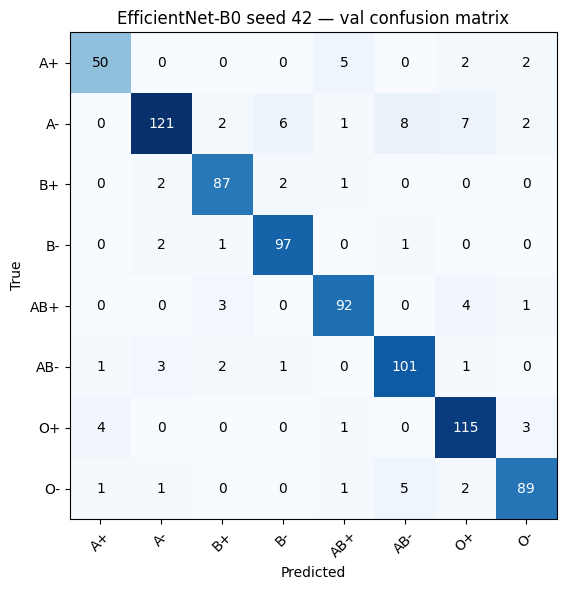

In [ ]:
# ===== STEP 10: Phase 7 diagnostics — EfficientNet-B0 seed 42 (validation only) =====
import json, numpy as np, pandas as pd, torch, torch.nn as nn
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms as T
from sklearn.metrics import (confusion_matrix, classification_report,
                             f1_score, balanced_accuracy_score, accuracy_score)

assert torch.cuda.is_available(), "CUDA not available"
dev = "cuda"

P     = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
CLEAN = Path('/content/data/clean')
CK    = P/'outputs'/'checkpoints'
assert (CK/'efficientnet_b0_seed42_best.pt').exists(), "checkpoint missing"

l2i = json.load(open(P/'outputs/label_to_idx.json'))
DISPLAY_ORDER = ['A+','A-','B+','B-','AB+','AB-','O+','O-']
assert set(DISPLAY_ORDER) == set(l2i.keys())
idx_to_display = {l2i[l]: l for l in DISPLAY_ORDER}

va = pd.read_csv(P/'splits/val.csv')          # TEST CSV NOT loaded
print(f"Val set: {len(va)} images")

rs   = T.Resize((224, 224))
norm = T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
tf_eval = T.Compose([rs, T.ToTensor(), norm])

class DS(Dataset):
    def __init__(s, df, tf): s.df, s.tf = df.reset_index(drop=True), tf
    def __len__(s): return len(s.df)
    def __getitem__(s, i):
        r = s.df.iloc[i]
        return s.tf(Image.open(CLEAN/r['path']).convert('RGB')), l2i[r['label']]

dl_va = DataLoader(DS(va, tf_eval), 64, shuffle=False, num_workers=2)

model = models.efficientnet_b0(weights=None)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, 8)
model.load_state_dict(torch.load(CK/'efficientnet_b0_seed42_best.pt', map_location=dev))
model = model.to(dev).eval()
print("Checkpoint loaded.")

ys, ps = [], []
with torch.no_grad():
    for x, y in dl_va:
        out = model(x.to(dev))
        ys += y.tolist()
        ps += out.argmax(1).cpu().tolist()

ys_str = np.array([idx_to_display[i] for i in ys])
ps_str = np.array([idx_to_display[i] for i in ps])

acc  = accuracy_score(ys_str, ps_str)
mf1  = f1_score(ys_str, ps_str, average='macro')
bacc = balanced_accuracy_score(ys_str, ps_str)

print("\n" + "="*50)
print(f"EfficientNet-B0 seed 42 — val accuracy:   {acc:.4f}")
print(f"EfficientNet-B0 seed 42 — val macro-F1:   {mf1:.4f}")
print(f"EfficientNet-B0 seed 42 — val bal. acc:   {bacc:.4f}")
print("="*50)

cm = confusion_matrix(ys_str, ps_str, labels=DISPLAY_ORDER)
cm_df = pd.DataFrame(cm, index=[f"true_{l}" for l in DISPLAY_ORDER],
                        columns=[f"pred_{l}" for l in DISPLAY_ORDER])
print("\nConfusion matrix (rows=true, cols=pred):")
print(cm_df.to_string())

report = classification_report(ys_str, ps_str, labels=DISPLAY_ORDER,
                                output_dict=True, zero_division=0)
per_class = pd.DataFrame({
    'class':     DISPLAY_ORDER,
    'precision': [report[l]['precision'] for l in DISPLAY_ORDER],
    'recall':    [report[l]['recall'] for l in DISPLAY_ORDER],
    'f1':        [report[l]['f1-score'] for l in DISPLAY_ORDER],
    'support':   [int(report[l]['support']) for l in DISPLAY_ORDER],
})
print("\nPer-class (val):")
print(per_class.to_string(index=False))

cm_off = cm.copy(); np.fill_diagonal(cm_off, 0)
confs = [(DISPLAY_ORDER[i], DISPLAY_ORDER[j], int(cm_off[i,j]))
         for i in range(8) for j in range(8) if i != j and cm_off[i,j] > 0]
confs.sort(key=lambda t: -t[2])
print("\nTop confusions (true -> predicted, count):")
for t, p, n in confs[:8]:
    print(f"  true {t} -> pred {p}: {n}")

OUT = P/'outputs'
cm_df.to_csv(OUT/'phase7_efficientnet_b0_seed42_val_confusion_matrix.csv')
per_class.to_csv(OUT/'phase7_efficientnet_b0_seed42_val_per_class.csv', index=False)
pd.DataFrame([dict(model='efficientnet_b0', seed=42, n_val=len(ys_str),
                   accuracy=acc, macro_f1=mf1, balanced_accuracy=bacc)]).to_csv(
    OUT/'phase7_efficientnet_b0_seed42_val_summary.csv', index=False)

try:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(7,6))
    ax.imshow(cm, cmap='Blues')
    ax.set_xticks(range(8)); ax.set_yticks(range(8))
    ax.set_xticklabels(DISPLAY_ORDER, rotation=45)
    ax.set_yticklabels(DISPLAY_ORDER)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    for i in range(8):
        for j in range(8):
            ax.text(j, i, cm[i,j], ha='center', va='center',
                    color='white' if cm[i,j] > cm.max()/2 else 'black')
    plt.title('EfficientNet-B0 seed 42 — val confusion matrix')
    plt.tight_layout()
    plt.savefig(OUT/'phase7_efficientnet_b0_seed42_val_confusion_matrix.png', dpi=150)
    print("\nSaved confusion-matrix plot.")
except Exception as e:
    print(f"(plot skipped: {e})")

print("\nAll outputs saved to:", OUT)

In [ ]:
# ===== STEP 12: build /content/data/clean_clahe/ for train+val paths =====
import numpy as np, pandas as pd
from pathlib import Path
from PIL import Image
from skimage.exposure import equalize_adapthist

SRC = Path('/content/data/clean')
DST = Path('/content/data/clean_clahe')
assert SRC.exists(), "clean/ missing — run D2 first"

P  = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
tr = pd.read_csv(P/'splits/train.csv')
va = pd.read_csv(P/'splits/val.csv')          # TEST CSV NOT loaded

all_paths = set(tr['path']).union(set(va['path']))
print(f"Paths to build: {len(all_paths)}")

count, skipped = 0, 0
for rel in all_paths:
    src_f = SRC/rel
    dst_f = DST/rel
    if not src_f.exists():
        skipped += 1
        continue
    dst_f.parent.mkdir(parents=True, exist_ok=True)
    arr = np.array(Image.open(src_f).convert('L'))            # uint8 [0,255]
    clahe_f = equalize_adapthist(arr, clip_limit=0.01)         # float [0,1], kernel_size=None
    clahe_u8 = (clahe_f * 255.0).clip(0, 255).astype(np.uint8)
    Image.fromarray(clahe_u8).convert('RGB').save(dst_f)
    count += 1

print(f"Built {count} images. Skipped {skipped} missing sources.")
print(f"Destination: {DST}")

# --- sanity: prove CLAHE changed the pixels on a sample ---
sample = tr['path'].iloc[0]
src_arr = np.array(Image.open(SRC/sample).convert('L'))
dst_arr = np.array(Image.open(DST/sample).convert('L'))
print(f"\nSample: {sample}")
print(f"  input : min={src_arr.min():3d} max={src_arr.max():3d} mean={src_arr.mean():6.2f} std={src_arr.std():5.2f}")
print(f"  output: min={dst_arr.min():3d} max={dst_arr.max():3d} mean={dst_arr.mean():6.2f} std={dst_arr.std():5.2f}")
print(f"  identical: {np.array_equal(src_arr, dst_arr)}  (should be False)")
print(f"  output mode: {Image.open(DST/sample).mode}  (should be RGB)")

Paths to build: 4995
Built 4995 images. Skipped 0 missing sources.
Destination: /content/data/clean_clahe

Sample: O-/cluster_7_3987.BMP
  input : min=  0 max=255 mean=129.00 std=111.00
  output: min=  0 max=255 mean=135.98 std=112.95
  identical: False  (should be False)
  output mode: RGB  (should be RGB)


In [ ]:
# ===== STEP 13: EfficientNet-B0 + CLAHE, seed 42 (Phase 8a ablation) =====
import json, random, time, numpy as np, pandas as pd, torch, torch.nn as nn
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms as T
from sklearn.metrics import f1_score

BACKBONE = "efficientnet_b0"
TAG      = "clahe"              # <-- distinguishes CLAHE run from C1 R4
SEED, BS = 42, 32
HEAD_EP, FT_EP, PATIENCE = 3, 27, 8

assert torch.cuda.is_available(), "CUDA not available"
dev = "cuda"
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

P     = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
CLEAN = Path('/content/data/clean_clahe')       # <-- CLAHE images
CK    = P/'outputs'/'checkpoints'; CK.mkdir(parents=True, exist_ok=True)
assert CLEAN.exists(), "clean_clahe/ missing — run Step 12 first"

l2i = json.load(open(P/'outputs/label_to_idx.json'))
tr  = pd.read_csv(P/'splits/train.csv')
va  = pd.read_csv(P/'splits/val.csv')          # TEST CSV NOT loaded

rs   = T.Resize((224, 224))
norm = T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
tf_train = T.Compose([rs, T.RandomAffine(10, translate=(0.05,0.05), scale=(0.95,1.05), fill=255),
                      T.ColorJitter(0.1, 0.1), T.ToTensor(), norm])
tf_eval  = T.Compose([rs, T.ToTensor(), norm])

class DS(Dataset):
    def __init__(s, df, tf): s.df, s.tf = df.reset_index(drop=True), tf
    def __len__(s): return len(s.df)
    def __getitem__(s, i):
        r = s.df.iloc[i]
        return s.tf(Image.open(CLEAN/r['path']).convert('RGB')), l2i[r['label']]

g = torch.Generator().manual_seed(SEED)
dl_tr = DataLoader(DS(tr, tf_train), BS, shuffle=True, num_workers=2, generator=g, drop_last=True)
dl_va = DataLoader(DS(va, tf_eval), BS*2, shuffle=False, num_workers=2)

model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, 8)
head = model.classifier
model = model.to(dev)

cw     = torch.load(P/'outputs/class_weights.pt').float().to(dev)
crit   = nn.CrossEntropyLoss(weight=cw, label_smoothing=0.1)
scaler = torch.amp.GradScaler("cuda")

def run_epoch(loader, opt=None):
    train = opt is not None
    model.train(train); ys, ps, tot = [], [], 0.0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(dev), y.to(dev)
            with torch.autocast("cuda", dtype=torch.float16):
                out = model(x); loss = crit(out, y)
            if train:
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item()*len(y); ys += y.tolist(); ps += out.argmax(1).tolist()
    return tot/len(ys), float(np.mean(np.array(ys)==np.array(ps))), f1_score(ys, ps, average='macro')

log, best, bad = [], -1, 0
ckpt_path = CK/f'{BACKBONE}_{TAG}_seed{SEED}_best.pt'          # <-- clahe tag
log_path  = P/f'outputs/{BACKBONE}_{TAG}_seed{SEED}_train_log.csv'

def fit(epochs, opt, sched, stage):
    global best, bad
    for ep in range(epochs):
        t0 = time.time()
        trl, tra, trf = run_epoch(dl_tr, opt)
        val, vaa, vaf = run_epoch(dl_va)
        if sched: sched.step()
        log.append(dict(stage=stage, ep=ep+1, tr_loss=trl, tr_acc=tra, tr_f1=trf,
                        va_loss=val, va_acc=vaa, va_f1=vaf))
        print(f"[{stage}] {ep+1:02d} tr_acc {tra:.3f} va_acc {vaa:.3f} va_F1 {vaf:.3f} ({time.time()-t0:.0f}s)")
        if vaf > best:
            best, bad = vaf, 0
            torch.save(model.state_dict(), ckpt_path)
        elif stage == "full":
            bad += 1
            if bad >= PATIENCE: print("Early stop"); return
        pd.DataFrame(log).to_csv(log_path, index=False)

for p in model.parameters(): p.requires_grad = False
for p in head.parameters():  p.requires_grad = True
fit(HEAD_EP, torch.optim.AdamW(head.parameters(), lr=1e-3, weight_decay=1e-4), None, "head")

for p in model.parameters(): p.requires_grad = True
opt = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
fit(FT_EP, opt, torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=FT_EP, eta_min=1e-6), "full")

pd.DataFrame(log).to_csv(log_path, index=False)
print(f"\nBest val macro-F1: {best:.4f}  |  checkpoint: {ckpt_path.name}  |  log: {log_path.name}")

[head] 01 tr_acc 0.380 va_acc 0.496 va_F1 0.491 (29s)
[head] 02 tr_acc 0.486 va_acc 0.541 va_F1 0.535 (21s)
[head] 03 tr_acc 0.522 va_acc 0.576 va_F1 0.575 (28s)
[full] 01 tr_acc 0.677 va_acc 0.783 va_F1 0.781 (24s)
[full] 02 tr_acc 0.792 va_acc 0.828 va_F1 0.826 (23s)
[full] 03 tr_acc 0.821 va_acc 0.841 va_F1 0.838 (23s)
[full] 04 tr_acc 0.841 va_acc 0.863 va_F1 0.863 (23s)
[full] 05 tr_acc 0.870 va_acc 0.866 va_F1 0.869 (22s)
[full] 06 tr_acc 0.881 va_acc 0.864 va_F1 0.864 (24s)
[full] 07 tr_acc 0.898 va_acc 0.881 va_F1 0.883 (22s)
[full] 08 tr_acc 0.906 va_acc 0.877 va_F1 0.878 (24s)
[full] 09 tr_acc 0.915 va_acc 0.848 va_F1 0.851 (22s)
[full] 10 tr_acc 0.919 va_acc 0.894 va_F1 0.895 (23s)
[full] 11 tr_acc 0.925 va_acc 0.888 va_F1 0.886 (23s)
[full] 12 tr_acc 0.932 va_acc 0.884 va_F1 0.886 (22s)
[full] 13 tr_acc 0.939 va_acc 0.892 va_F1 0.891 (23s)
[full] 14 tr_acc 0.943 va_acc 0.900 va_F1 0.901 (22s)
[full] 15 tr_acc 0.946 va_acc 0.894 va_F1 0.895 (23s)
[full] 16 tr_acc 0.954 va_ac

In [ ]:
# ===== STEP 14: fp32 re-eval of CLAHE seed 42 + Section 3.10 verdict =====
import json, numpy as np, pandas as pd, torch, torch.nn as nn
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms as T
from sklearn.metrics import f1_score, balanced_accuracy_score, accuracy_score

assert torch.cuda.is_available(), "CUDA not available"
dev = "cuda"

P     = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
CLEAN = Path('/content/data/clean_clahe')     # <-- CLAHE images
CK    = P/'outputs'/'checkpoints'

l2i = json.load(open(P/'outputs/label_to_idx.json'))
DISPLAY_ORDER = ['A+','A-','B+','B-','AB+','AB-','O+','O-']
idx_to_display = {l2i[l]: l for l in DISPLAY_ORDER}
va = pd.read_csv(P/'splits/val.csv')          # TEST CSV NOT loaded

rs   = T.Resize((224, 224))
norm = T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
tf_eval = T.Compose([rs, T.ToTensor(), norm])

class DS(Dataset):
    def __init__(s, df, tf): s.df, s.tf = df.reset_index(drop=True), tf
    def __len__(s): return len(s.df)
    def __getitem__(s, i):
        r = s.df.iloc[i]
        return s.tf(Image.open(CLEAN/r['path']).convert('RGB')), l2i[r['label']]

dl_va = DataLoader(DS(va, tf_eval), 64, shuffle=False, num_workers=2)

ckpt = CK/'efficientnet_b0_clahe_seed42_best.pt'
assert ckpt.exists(), f"missing {ckpt.name}"
m = models.efficientnet_b0(weights=None)
m.classifier[1] = nn.Linear(m.classifier[1].in_features, 8)
m.load_state_dict(torch.load(ckpt, map_location=dev))
m = m.to(dev).eval()

ys, ps, probs = [], [], []
with torch.no_grad():
    for x, y in dl_va:
        out = m(x.to(dev))
        probs.append(torch.softmax(out, dim=1).cpu().numpy())
        ys += y.tolist()
        ps += out.argmax(1).cpu().tolist()
probs = np.concatenate(probs, axis=0)

ys_str = np.array([idx_to_display[i] for i in ys])
ps_str = np.array([idx_to_display[i] for i in ps])
acc  = accuracy_score(ys_str, ps_str)
mf1  = f1_score(ys_str, ps_str, average='macro')
bacc = balanced_accuracy_score(ys_str, ps_str)

np.savez(P/'outputs/phase7_efficientnet_b0_clahe_seed42_val_preds.npz',
         probs=probs, y_true_idx=np.array(ys), y_pred_idx=np.array(ps),
         paths=va['path'].values, label_order=np.array(list(l2i.keys())))

print("="*60)
print(f"CLAHE seed 42 — fp32 val accuracy:  {acc:.4f}")
print(f"CLAHE seed 42 — fp32 val macro-F1:  {mf1:.4f}")
print(f"CLAHE seed 42 — fp32 val bal. acc:  {bacc:.4f}")
print("="*60)

# Section 3.10 verdict
C1_MEAN   = 0.9022      # EfficientNet-B0 C1 3-seed mean (fp32)
FLOOR     = 0.005       # 0.5 pp floor
THRESHOLD = C1_MEAN + FLOOR     # 0.9072
print(f"\nC1 3-seed mean (fp32):    {C1_MEAN:.4f}")
print(f"Threshold (mean + 0.5pp): {THRESHOLD:.4f}")
print(f"CLAHE seed 42 (fp32):     {mf1:.4f}")
print(f"Delta to threshold:       {(mf1 - THRESHOLD)*100:+.2f} pp")
verdict = "PROMISING — run 2 more seeds" if mf1 >= THRESHOLD else "NOT PROMISING — keep C1, record result"
print(f"\nSection 3.10 verdict: {verdict}")

FileNotFoundError: Caught FileNotFoundError in DataLoader worker process 0.
Original Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/_utils/worker.py", line 358, in _worker_loop
    data = fetcher.fetch(index)  # type: ignore[possibly-undefined]
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/_utils/fetch.py", line 54, in fetch
    data = [self.dataset[idx] for idx in possibly_batched_index]
            ~~~~~~~~~~~~^^^^^
  File "/tmp/ipykernel_507/2247330826.py", line 30, in __getitem__
    return s.tf(Image.open(CLEAN/r['path']).convert('RGB')), l2i[r['label']]
                ~~~~~~~~~~^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/PIL/Image.py", line 3513, in open
    fp = builtins.open(filename, "rb")
FileNotFoundError: [Errno 2] No such file or directory: '/content/data/clean_clahe/O-/cluster_7_3412.BMP'


In [ ]:
# ===== Diagnostic: what survived the runtime reset? =====
from pathlib import Path
import pandas as pd

P  = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
tr = pd.read_csv(P/'splits/train.csv')
va = pd.read_csv(P/'splits/val.csv')

for p in ['/content/data',
          '/content/data/raw',
          '/content/data/clean',
          '/content/data/clean_clahe']:
    pp = Path(p)
    print(f"{p}: exists={pp.exists()}")
    if pp.exists() and pp.is_dir():
        subdirs = [d for d in pp.iterdir() if d.is_dir()]
        print(f"   subdirs: {len(subdirs)}")
        for d in sorted(subdirs)[:3]:
            try:
                n = len(list(d.iterdir()))
                print(f"     {d.name}: {n} files")
            except Exception as e:
                print(f"     {d.name}: (error {e})")

print("\nCheck specific missing file from the traceback:")
target = Path('/content/data/clean_clahe/O-/cluster_7_3412.BMP')
print(f"  {target}: exists={target.exists()}")

print("\nCheck Drive-side artifacts (should still exist):")
for name in ['outputs/checkpoints/efficientnet_b0_clahe_seed42_best.pt',
             'outputs/efficientnet_b0_clahe_seed42_train_log.csv',
             'outputs/efficientnet_b0_seed42_best.pt',
             'outputs/resnet50_seed42_best.pt']:
    f = P/name
    print(f"  {name}: exists={f.exists()}" +
          (f" ({f.stat().st_size/1e6:.1f} MB)" if f.exists() else ""))

/content/data: exists=True
   subdirs: 2
     clean: 8 files
     raw: 1 files
/content/data/raw: exists=True
   subdirs: 1
     datasets: 8 files
/content/data/clean: exists=True
   subdirs: 8
     A+: 402 files
     A-: 1009 files
     AB+: 708 files
/content/data/clean_clahe: exists=False

Check specific missing file from the traceback:
  /content/data/clean_clahe/O-/cluster_7_3412.BMP: exists=False

Check Drive-side artifacts (should still exist):
  outputs/checkpoints/efficientnet_b0_clahe_seed42_best.pt: exists=True (16.4 MB)
  outputs/efficientnet_b0_clahe_seed42_train_log.csv: exists=True (0.0 MB)
  outputs/efficientnet_b0_seed42_best.pt: exists=False
  outputs/resnet50_seed42_best.pt: exists=False


In [ ]:
# ===== Inventory: every checkpoint + log + free space =====
from pathlib import Path
import shutil, os, time

P   = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
CK  = P/'outputs'/'checkpoints'
OUT = P/'outputs'

print("=== outputs/checkpoints/ ===")
if CK.exists():
    ckpts = sorted(CK.iterdir())
    if not ckpts:
        print("  (empty!)")
    for f in ckpts:
        st = f.stat()
        print(f"  {f.name:55s} {st.st_size/1e6:7.2f} MB  mtime={time.strftime('%Y-%m-%d %H:%M', time.localtime(st.st_mtime))}")
else:
    print(f"  (directory missing: {CK})")

print("\n=== outputs/*train_log.csv ===")
if OUT.exists():
    for f in sorted(OUT.glob('*train_log.csv')):
        st = f.stat()
        print(f"  {f.name:55s} {st.st_size/1e3:7.2f} KB  mtime={time.strftime('%Y-%m-%d %H:%M', time.localtime(st.st_mtime))}")

print("\n=== outputs/phase7_*val_preds.npz ===")
if OUT.exists():
    for f in sorted(OUT.glob('phase7_*val_preds.npz')):
        st = f.stat()
        print(f"  {f.name:55s} {st.st_size/1e6:7.3f} MB  mtime={time.strftime('%Y-%m-%d %H:%M', time.localtime(st.st_mtime))}")

print("\n=== outputs/backbone_comparison_fp32.csv ===")
f = OUT/'backbone_comparison_fp32.csv'
print(f"  exists={f.exists()}" + (f" ({f.stat().st_size} bytes)" if f.exists() else ""))

print("\n=== Drive mount free space ===")
try:
    usage = shutil.disk_usage('/content/drive')
    print(f"  total={usage.total/1e9:.2f} GB  used={usage.used/1e9:.2f} GB  free={usage.free/1e9:.2f} GB")
except Exception as e:
    print(f"  (could not check: {e})")

print("\n=== /content/data/ ===")
for p in ['/content/data/clean', '/content/data/clean_clahe', '/content/data/raw/datasets']:
    pp = Path(p)
    if pp.exists():
        n = sum(1 for _ in pp.rglob('*') if _.is_file())
        print(f"  {p}: exists=True, {n} files")
    else:
        print(f"  {p}: exists=False")

=== outputs/checkpoints/ ===
  efficientnet_b0_clahe_seed42_best.pt                      16.38 MB  mtime=2026-11-05 02:43
  efficientnet_b0_seed42_best.pt                            16.38 MB  mtime=2026-11-04 15:24
  efficientnet_b0_seed43_best.pt                            16.38 MB  mtime=2026-11-04 15:37
  efficientnet_b0_seed44_best.pt                            16.38 MB  mtime=2026-11-05 02:04
  resnet50_seed42_best.pt                                   94.42 MB  mtime=2026-11-04 14:35
  resnet50_seed43_best.pt                                   94.42 MB  mtime=2026-11-04 14:48
  resnet50_seed44_best.pt                                   94.42 MB  mtime=2026-11-04 15:01

=== outputs/*train_log.csv ===
  efficientnet_b0_clahe_seed42_train_log.csv                 3.53 KB  mtime=2026-11-05 02:46
  efficientnet_b0_seed42_train_log.csv                       3.65 KB  mtime=2026-11-04 15:27
  efficientnet_b0_seed43_train_log.csv                       2.69 KB  mtime=2026-11-04 15:40
  efficie

In [ ]:
# ===== STEP 12-RETRY: rebuild /content/data/clean_clahe/ =====
import numpy as np, pandas as pd
from pathlib import Path
from PIL import Image
from skimage.exposure import equalize_adapthist

SRC = Path('/content/data/clean')
DST = Path('/content/data/clean_clahe')
assert SRC.exists(), "clean/ missing — D2 output gone, needs deeper recovery"

P  = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
tr = pd.read_csv(P/'splits/train.csv')
va = pd.read_csv(P/'splits/val.csv')          # TEST CSV NOT loaded

all_paths = set(tr['path']).union(set(va['path']))
print(f"Paths to build: {len(all_paths)}")

count, skipped = 0, 0
for rel in all_paths:
    src_f = SRC/rel
    dst_f = DST/rel
    if not src_f.exists():
        skipped += 1
        continue
    dst_f.parent.mkdir(parents=True, exist_ok=True)
    arr = np.array(Image.open(src_f).convert('L'))
    clahe_f = equalize_adapthist(arr, clip_limit=0.01)
    clahe_u8 = (clahe_f * 255.0).clip(0, 255).astype(np.uint8)
    Image.fromarray(clahe_u8).convert('RGB').save(dst_f)
    count += 1

print(f"Built {count} images. Skipped {skipped} missing sources.")
print(f"Destination: {DST}")

# sanity: the exact file from the original traceback
target = DST/'O-/cluster_7_3412.BMP'
print(f"\nPreviously-missing file now exists: {target.exists()}")
if target.exists():
    a = np.array(Image.open(target).convert('L'))
    print(f"  stats: min={a.min()} max={a.max()} mean={a.mean():.2f} std={a.std():.2f}")

Paths to build: 4995
Built 4995 images. Skipped 0 missing sources.
Destination: /content/data/clean_clahe

Previously-missing file now exists: True
  stats: min=0 max=255 mean=198.63 std=87.21


In [ ]:
# ===== STEP 14 (retry): fp32 re-eval of CLAHE seed 42 + Section 3.10 verdict =====
import json, numpy as np, pandas as pd, torch, torch.nn as nn
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms as T
from sklearn.metrics import f1_score, balanced_accuracy_score, accuracy_score

assert torch.cuda.is_available(), "CUDA not available"
dev = "cuda"

P     = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
CLEAN = Path('/content/data/clean_clahe')
CK    = P/'outputs'/'checkpoints'

l2i = json.load(open(P/'outputs/label_to_idx.json'))
DISPLAY_ORDER = ['A+','A-','B+','B-','AB+','AB-','O+','O-']
idx_to_display = {l2i[l]: l for l in DISPLAY_ORDER}
va = pd.read_csv(P/'splits/val.csv')          # TEST CSV NOT loaded

rs   = T.Resize((224, 224))
norm = T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
tf_eval = T.Compose([rs, T.ToTensor(), norm])

class DS(Dataset):
    def __init__(s, df, tf): s.df, s.tf = df.reset_index(drop=True), tf
    def __len__(s): return len(s.df)
    def __getitem__(s, i):
        r = s.df.iloc[i]
        return s.tf(Image.open(CLEAN/r['path']).convert('RGB')), l2i[r['label']]

dl_va = DataLoader(DS(va, tf_eval), 64, shuffle=False, num_workers=2)

ckpt = CK/'efficientnet_b0_clahe_seed42_best.pt'
assert ckpt.exists(), f"missing {ckpt.name}"
m = models.efficientnet_b0(weights=None)
m.classifier[1] = nn.Linear(m.classifier[1].in_features, 8)
m.load_state_dict(torch.load(ckpt, map_location=dev))
m = m.to(dev).eval()

ys, ps, probs = [], [], []
with torch.no_grad():
    for x, y in dl_va:
        out = m(x.to(dev))
        probs.append(torch.softmax(out, dim=1).cpu().numpy())
        ys += y.tolist()
        ps += out.argmax(1).cpu().tolist()
probs = np.concatenate(probs, axis=0)

ys_str = np.array([idx_to_display[i] for i in ys])
ps_str = np.array([idx_to_display[i] for i in ps])
acc  = accuracy_score(ys_str, ps_str)
mf1  = f1_score(ys_str, ps_str, average='macro')
bacc = balanced_accuracy_score(ys_str, ps_str)

np.savez(P/'outputs/phase7_efficientnet_b0_clahe_seed42_val_preds.npz',
         probs=probs, y_true_idx=np.array(ys), y_pred_idx=np.array(ps),
         paths=va['path'].values, label_order=np.array(list(l2i.keys())))

print("="*60)
print(f"CLAHE seed 42 — fp32 val accuracy:  {acc:.4f}")
print(f"CLAHE seed 42 — fp32 val macro-F1:  {mf1:.4f}")
print(f"CLAHE seed 42 — fp32 val bal. acc:  {bacc:.4f}")
print("="*60)

# Section 3.10 verdict
C1_MEAN   = 0.9022
FLOOR     = 0.005
THRESHOLD = C1_MEAN + FLOOR
print(f"\nC1 3-seed mean (fp32):    {C1_MEAN:.4f}")
print(f"Threshold (mean + 0.5pp): {THRESHOLD:.4f}")
print(f"CLAHE seed 42 (fp32):     {mf1:.4f}")
print(f"Delta to threshold:       {(mf1 - THRESHOLD)*100:+.2f} pp")
verdict = "PROMISING — run 2 more seeds" if mf1 >= THRESHOLD else "NOT PROMISING — keep C1, record result"
print(f"\nSection 3.10 verdict: {verdict}")

CLAHE seed 42 — fp32 val accuracy:  0.9012
CLAHE seed 42 — fp32 val macro-F1:  0.9006
CLAHE seed 42 — fp32 val bal. acc:  0.9032

C1 3-seed mean (fp32):    0.9022
Threshold (mean + 0.5pp): 0.9072
CLAHE seed 42 (fp32):     0.9006
Delta to threshold:       -0.66 pp

Section 3.10 verdict: NOT PROMISING — keep C1, record result


In [ ]:
# ===== STEP 15: Phase 8b ablation 1 — EfficientNet-B0 C1 seed 42, NO class weighting =====
import json, random, time, numpy as np, pandas as pd, torch, torch.nn as nn
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms as T
from sklearn.metrics import f1_score

BACKBONE = "efficientnet_b0"
TAG      = "no_cw"
SEED, BS = 42, 32
HEAD_EP, FT_EP, PATIENCE = 3, 27, 8

assert torch.cuda.is_available(), "CUDA not available"
dev = "cuda"
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

P     = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
CLEAN = Path('/content/data/clean')                # C1 images
CK    = P/'outputs'/'checkpoints'; CK.mkdir(parents=True, exist_ok=True)
assert CLEAN.exists(), "clean/ missing"

l2i = json.load(open(P/'outputs/label_to_idx.json'))
tr  = pd.read_csv(P/'splits/train.csv')
va  = pd.read_csv(P/'splits/val.csv')          # TEST CSV NOT loaded

rs   = T.Resize((224, 224))
norm = T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
tf_train = T.Compose([rs, T.RandomAffine(10, translate=(0.05,0.05), scale=(0.95,1.05), fill=255),
                      T.ColorJitter(0.1, 0.1), T.ToTensor(), norm])
tf_eval  = T.Compose([rs, T.ToTensor(), norm])

class DS(Dataset):
    def __init__(s, df, tf): s.df, s.tf = df.reset_index(drop=True), tf
    def __len__(s): return len(s.df)
    def __getitem__(s, i):
        r = s.df.iloc[i]
        return s.tf(Image.open(CLEAN/r['path']).convert('RGB')), l2i[r['label']]

g = torch.Generator().manual_seed(SEED)
dl_tr = DataLoader(DS(tr, tf_train), BS, shuffle=True, num_workers=2, generator=g, drop_last=True)
dl_va = DataLoader(DS(va, tf_eval), BS*2, shuffle=False, num_workers=2)

model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, 8)
head = model.classifier
model = model.to(dev)

# *** THE ONLY SUBSTANTIVE CHANGE: no class weights ***
crit   = nn.CrossEntropyLoss(label_smoothing=0.1)
scaler = torch.amp.GradScaler("cuda")

def run_epoch(loader, opt=None):
    train = opt is not None
    model.train(train); ys, ps, tot = [], [], 0.0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(dev), y.to(dev)
            with torch.autocast("cuda", dtype=torch.float16):
                out = model(x); loss = crit(out, y)
            if train:
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item()*len(y); ys += y.tolist(); ps += out.argmax(1).tolist()
    return tot/len(ys), float(np.mean(np.array(ys)==np.array(ps))), f1_score(ys, ps, average='macro')

log, best, bad = [], -1, 0
ckpt_path = CK/f'{BACKBONE}_{TAG}_seed{SEED}_best.pt'
log_path  = P/f'outputs/{BACKBONE}_{TAG}_seed{SEED}_train_log.csv'

def fit(epochs, opt, sched, stage):
    global best, bad
    for ep in range(epochs):
        t0 = time.time()
        trl, tra, trf = run_epoch(dl_tr, opt)
        val, vaa, vaf = run_epoch(dl_va)
        if sched: sched.step()
        log.append(dict(stage=stage, ep=ep+1, tr_loss=trl, tr_acc=tra, tr_f1=trf,
                        va_loss=val, va_acc=vaa, va_f1=vaf))
        print(f"[{stage}] {ep+1:02d} tr_acc {tra:.3f} va_acc {vaa:.3f} va_F1 {vaf:.3f} ({time.time()-t0:.0f}s)")
        if vaf > best:
            best, bad = vaf, 0
            torch.save(model.state_dict(), ckpt_path)
        elif stage == "full":
            bad += 1
            if bad >= PATIENCE: print("Early stop"); return
        pd.DataFrame(log).to_csv(log_path, index=False)

for p in model.parameters(): p.requires_grad = False
for p in head.parameters():  p.requires_grad = True
fit(HEAD_EP, torch.optim.AdamW(head.parameters(), lr=1e-3, weight_decay=1e-4), None, "head")

for p in model.parameters(): p.requires_grad = True
opt = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
fit(FT_EP, opt, torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=FT_EP, eta_min=1e-6), "full")

pd.DataFrame(log).to_csv(log_path, index=False)
print(f"\nBest val macro-F1: {best:.4f}  |  checkpoint: {ckpt_path.name}  |  log: {log_path.name}")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 67.7MB/s]


[head] 01 tr_acc 0.382 va_acc 0.501 va_F1 0.488 (33s)
[head] 02 tr_acc 0.486 va_acc 0.531 va_F1 0.517 (22s)
[head] 03 tr_acc 0.528 va_acc 0.567 va_F1 0.552 (18s)
[full] 01 tr_acc 0.689 va_acc 0.789 va_F1 0.788 (26s)
[full] 02 tr_acc 0.805 va_acc 0.829 va_F1 0.826 (24s)
[full] 03 tr_acc 0.836 va_acc 0.852 va_F1 0.849 (24s)
[full] 04 tr_acc 0.852 va_acc 0.872 va_F1 0.870 (23s)
[full] 05 tr_acc 0.877 va_acc 0.869 va_F1 0.867 (23s)
[full] 06 tr_acc 0.888 va_acc 0.863 va_F1 0.861 (24s)
[full] 07 tr_acc 0.897 va_acc 0.899 va_F1 0.899 (23s)
[full] 08 tr_acc 0.916 va_acc 0.887 va_F1 0.887 (25s)
[full] 09 tr_acc 0.923 va_acc 0.881 va_F1 0.882 (25s)
[full] 10 tr_acc 0.927 va_acc 0.892 va_F1 0.893 (25s)
[full] 11 tr_acc 0.932 va_acc 0.880 va_F1 0.879 (26s)
[full] 12 tr_acc 0.941 va_acc 0.895 va_F1 0.896 (24s)
[full] 13 tr_acc 0.942 va_acc 0.904 va_F1 0.902 (26s)
[full] 14 tr_acc 0.954 va_acc 0.895 va_F1 0.895 (26s)
[full] 15 tr_acc 0.954 va_acc 0.902 va_F1 0.901 (24s)
[full] 16 tr_acc 0.960 va_ac

In [ ]:
# ===== STEP 16: fp32 re-eval of no_cw seed 42 + Phase 8b verdict =====
import json, numpy as np, pandas as pd, torch, torch.nn as nn
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms as T
from sklearn.metrics import (f1_score, balanced_accuracy_score, accuracy_score,
                             classification_report)

assert torch.cuda.is_available(), "CUDA not available"
dev = "cuda"

P     = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
CLEAN = Path('/content/data/clean')          # C1 images
CK    = P/'outputs'/'checkpoints'

l2i = json.load(open(P/'outputs/label_to_idx.json'))
DISPLAY_ORDER = ['A+','A-','B+','B-','AB+','AB-','O+','O-']
idx_to_display = {l2i[l]: l for l in DISPLAY_ORDER}
va = pd.read_csv(P/'splits/val.csv')          # TEST CSV NOT loaded

rs   = T.Resize((224, 224))
norm = T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
tf_eval = T.Compose([rs, T.ToTensor(), norm])

class DS(Dataset):
    def __init__(s, df, tf): s.df, s.tf = df.reset_index(drop=True), tf
    def __len__(s): return len(s.df)
    def __getitem__(s, i):
        r = s.df.iloc[i]
        return s.tf(Image.open(CLEAN/r['path']).convert('RGB')), l2i[r['label']]

dl_va = DataLoader(DS(va, tf_eval), 64, shuffle=False, num_workers=2)

ckpt = CK/'efficientnet_b0_no_cw_seed42_best.pt'
assert ckpt.exists(), f"missing {ckpt.name}"
m = models.efficientnet_b0(weights=None)
m.classifier[1] = nn.Linear(m.classifier[1].in_features, 8)
m.load_state_dict(torch.load(ckpt, map_location=dev))
m = m.to(dev).eval()

ys, ps, probs = [], [], []
with torch.no_grad():
    for x, y in dl_va:
        out = m(x.to(dev))
        probs.append(torch.softmax(out, dim=1).cpu().numpy())
        ys += y.tolist()
        ps += out.argmax(1).cpu().tolist()
probs = np.concatenate(probs, axis=0)

ys_str = np.array([idx_to_display[i] for i in ys])
ps_str = np.array([idx_to_display[i] for i in ps])
acc  = accuracy_score(ys_str, ps_str)
mf1  = f1_score(ys_str, ps_str, average='macro')
bacc = balanced_accuracy_score(ys_str, ps_str)

np.savez(P/'outputs/phase7_efficientnet_b0_no_cw_seed42_val_preds.npz',
         probs=probs, y_true_idx=np.array(ys), y_pred_idx=np.array(ps),
         paths=va['path'].values, label_order=np.array(list(l2i.keys())))

print("="*60)
print(f"NO-CW seed 42 — fp32 val accuracy:  {acc:.4f}")
print(f"NO-CW seed 42 — fp32 val macro-F1:  {mf1:.4f}")
print(f"NO-CW seed 42 — fp32 val bal. acc:  {bacc:.4f}")
print("="*60)

# per-class F1 to see whether the A+ class degraded
report = classification_report(ys_str, ps_str, labels=DISPLAY_ORDER,
                                output_dict=True, zero_division=0)
per_class = pd.DataFrame({
    'class':     DISPLAY_ORDER,
    'precision': [report[l]['precision'] for l in DISPLAY_ORDER],
    'recall':    [report[l]['recall'] for l in DISPLAY_ORDER],
    'f1':        [report[l]['f1-score'] for l in DISPLAY_ORDER],
    'support':   [int(report[l]['support']) for l in DISPLAY_ORDER],
})
print("\nPer-class (val) — no class weighting:")
print(per_class.to_string(index=False))

# Phase 8b verdict (Section 3.7: 1 seed first; expand only if > baseline by noise margin)
C1_SEED42 = 0.9056      # C1 with class weights, seed 42 (fp32)
C1_MEAN   = 0.9022
BAR       = 0.0085      # ResNet baseline SD; the section 5 "noise" rule
print(f"\nC1 seed 42 (with class weights, fp32): {C1_SEED42:.4f}")
print(f"C1 3-seed mean (fp32):                 {C1_MEAN:.4f}")
print(f"NO-CW seed 42 (fp32):                  {mf1:.4f}")
print(f"Delta vs C1 seed 42:                   {(mf1 - C1_SEED42)*100:+.2f} pp")
print(f"Delta vs C1 3-seed mean:               {(mf1 - C1_MEAN)*100:+.2f} pp")

expand = (mf1 - C1_MEAN) > BAR
print(f"\nPhase 8b rule: expand to 3 seeds only if delta vs C1 mean > {BAR:.4f}")
print(f"Verdict: {'EXPAND — run seeds 43/44' if expand else 'DO NOT EXPAND — record and move on'}")

NO-CW seed 42 — fp32 val accuracy:  0.9036
NO-CW seed 42 — fp32 val macro-F1:  0.9022
NO-CW seed 42 — fp32 val bal. acc:  0.9041

Per-class (val) — no class weighting:
class  precision   recall       f1  support
   A+   0.850000 0.864407 0.857143       59
   A-   0.913043 0.857143 0.884211      147
   B+   0.903226 0.913043 0.908108       92
   B-   0.906542 0.960396 0.932692      101
  AB+   0.873874 0.970000 0.919431      100
  AB-   0.932039 0.880734 0.905660      109
   O+   0.882812 0.918699 0.900398      123
   O-   0.955556 0.868687 0.910053       99

C1 seed 42 (with class weights, fp32): 0.9056
C1 3-seed mean (fp32):                 0.9022
NO-CW seed 42 (fp32):                  0.9022
Delta vs C1 seed 42:                   -0.34 pp
Delta vs C1 3-seed mean:               +0.00 pp

Phase 8b rule: expand to 3 seeds only if delta vs C1 mean > 0.0085
Verdict: DO NOT EXPAND — record and move on


In [ ]:
# ===== STEP 17: Phase 8b ablation 2 — EfficientNet-B0 C1 seed 42, NO augmentation =====
import json, random, time, numpy as np, pandas as pd, torch, torch.nn as nn
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms as T
from sklearn.metrics import f1_score

BACKBONE = "efficientnet_b0"
TAG      = "no_aug"
SEED, BS = 42, 32
HEAD_EP, FT_EP, PATIENCE = 3, 27, 8

assert torch.cuda.is_available(), "CUDA not available"
dev = "cuda"
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

P     = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
CLEAN = Path('/content/data/clean')                # C1 images
CK    = P/'outputs'/'checkpoints'; CK.mkdir(parents=True, exist_ok=True)
assert CLEAN.exists(), "clean/ missing"

l2i = json.load(open(P/'outputs/label_to_idx.json'))
tr  = pd.read_csv(P/'splits/train.csv')
va  = pd.read_csv(P/'splits/val.csv')          # TEST CSV NOT loaded

rs   = T.Resize((224, 224))
norm = T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
tf_eval = T.Compose([rs, T.ToTensor(), norm])
# *** ONLY SUBSTANTIVE CHANGE: no augmentation — train uses the eval transform ***
tf_train = tf_eval

class DS(Dataset):
    def __init__(s, df, tf): s.df, s.tf = df.reset_index(drop=True), tf
    def __len__(s): return len(s.df)
    def __getitem__(s, i):
        r = s.df.iloc[i]
        return s.tf(Image.open(CLEAN/r['path']).convert('RGB')), l2i[r['label']]

g = torch.Generator().manual_seed(SEED)
dl_tr = DataLoader(DS(tr, tf_train), BS, shuffle=True, num_workers=2, generator=g, drop_last=True)
dl_va = DataLoader(DS(va, tf_eval), BS*2, shuffle=False, num_workers=2)

model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, 8)
head = model.classifier
model = model.to(dev)

cw     = torch.load(P/'outputs/class_weights.pt').float().to(dev)   # class weights KEPT
crit   = nn.CrossEntropyLoss(weight=cw, label_smoothing=0.1)
scaler = torch.amp.GradScaler("cuda")

def run_epoch(loader, opt=None):
    train = opt is not None
    model.train(train); ys, ps, tot = [], [], 0.0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(dev), y.to(dev)
            with torch.autocast("cuda", dtype=torch.float16):
                out = model(x); loss = crit(out, y)
            if train:
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item()*len(y); ys += y.tolist(); ps += out.argmax(1).tolist()
    return tot/len(ys), float(np.mean(np.array(ys)==np.array(ps))), f1_score(ys, ps, average='macro')

log, best, bad = [], -1, 0
ckpt_path = CK/f'{BACKBONE}_{TAG}_seed{SEED}_best.pt'
log_path  = P/f'outputs/{BACKBONE}_{TAG}_seed{SEED}_train_log.csv'

def fit(epochs, opt, sched, stage):
    global best, bad
    for ep in range(epochs):
        t0 = time.time()
        trl, tra, trf = run_epoch(dl_tr, opt)
        val, vaa, vaf = run_epoch(dl_va)
        if sched: sched.step()
        log.append(dict(stage=stage, ep=ep+1, tr_loss=trl, tr_acc=tra, tr_f1=trf,
                        va_loss=val, va_acc=vaa, va_f1=vaf))
        print(f"[{stage}] {ep+1:02d} tr_acc {tra:.3f} va_acc {vaa:.3f} va_F1 {vaf:.3f} ({time.time()-t0:.0f}s)")
        if vaf > best:
            best, bad = vaf, 0
            torch.save(model.state_dict(), ckpt_path)
        elif stage == "full":
            bad += 1
            if bad >= PATIENCE: print("Early stop"); return
        pd.DataFrame(log).to_csv(log_path, index=False)

for p in model.parameters(): p.requires_grad = False
for p in head.parameters():  p.requires_grad = True
fit(HEAD_EP, torch.optim.AdamW(head.parameters(), lr=1e-3, weight_decay=1e-4), None, "head")

for p in model.parameters(): p.requires_grad = True
opt = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
fit(FT_EP, opt, torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=FT_EP, eta_min=1e-6), "full")

pd.DataFrame(log).to_csv(log_path, index=False)
print(f"\nBest val macro-F1: {best:.4f}  |  checkpoint: {ckpt_path.name}  |  log: {log_path.name}")

[head] 01 tr_acc 0.424 va_acc 0.537 va_F1 0.531 (23s)
[head] 02 tr_acc 0.571 va_acc 0.586 va_F1 0.583 (29s)
[head] 03 tr_acc 0.619 va_acc 0.619 va_F1 0.618 (20s)
[full] 01 tr_acc 0.743 va_acc 0.807 va_F1 0.810 (19s)
[full] 02 tr_acc 0.860 va_acc 0.849 va_F1 0.850 (20s)
[full] 03 tr_acc 0.916 va_acc 0.837 va_F1 0.836 (19s)
[full] 04 tr_acc 0.936 va_acc 0.871 va_F1 0.872 (20s)
[full] 05 tr_acc 0.958 va_acc 0.861 va_F1 0.863 (19s)
[full] 06 tr_acc 0.966 va_acc 0.854 va_F1 0.855 (19s)
[full] 07 tr_acc 0.976 va_acc 0.858 va_F1 0.859 (18s)
[full] 08 tr_acc 0.984 va_acc 0.866 va_F1 0.867 (18s)
[full] 09 tr_acc 0.987 va_acc 0.864 va_F1 0.864 (18s)
[full] 10 tr_acc 0.993 va_acc 0.869 va_F1 0.867 (19s)
[full] 11 tr_acc 0.993 va_acc 0.870 va_F1 0.867 (18s)
[full] 12 tr_acc 0.993 va_acc 0.866 va_F1 0.864 (18s)
Early stop

Best val macro-F1: 0.8724  |  checkpoint: efficientnet_b0_no_aug_seed42_best.pt  |  log: efficientnet_b0_no_aug_seed42_train_log.csv


In [ ]:
# ===== STEP 18: fp32 re-eval of no_aug seed 42 + Phase 8b verdict =====
import json, numpy as np, pandas as pd, torch, torch.nn as nn
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms as T
from sklearn.metrics import (f1_score, balanced_accuracy_score, accuracy_score,
                             classification_report)

assert torch.cuda.is_available(), "CUDA not available"
dev = "cuda"

P     = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
CLEAN = Path('/content/data/clean')
CK    = P/'outputs'/'checkpoints'

l2i = json.load(open(P/'outputs/label_to_idx.json'))
DISPLAY_ORDER = ['A+','A-','B+','B-','AB+','AB-','O+','O-']
idx_to_display = {l2i[l]: l for l in DISPLAY_ORDER}
va = pd.read_csv(P/'splits/val.csv')          # TEST CSV NOT loaded

rs   = T.Resize((224, 224))
norm = T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
tf_eval = T.Compose([rs, T.ToTensor(), norm])

class DS(Dataset):
    def __init__(s, df, tf): s.df, s.tf = df.reset_index(drop=True), tf
    def __len__(s): return len(s.df)
    def __getitem__(s, i):
        r = s.df.iloc[i]
        return s.tf(Image.open(CLEAN/r['path']).convert('RGB')), l2i[r['label']]

dl_va = DataLoader(DS(va, tf_eval), 64, shuffle=False, num_workers=2)

ckpt = CK/'efficientnet_b0_no_aug_seed42_best.pt'
assert ckpt.exists(), f"missing {ckpt.name}"
m = models.efficientnet_b0(weights=None)
m.classifier[1] = nn.Linear(m.classifier[1].in_features, 8)
m.load_state_dict(torch.load(ckpt, map_location=dev))
m = m.to(dev).eval()

ys, ps, probs = [], [], []
with torch.no_grad():
    for x, y in dl_va:
        out = m(x.to(dev))
        probs.append(torch.softmax(out, dim=1).cpu().numpy())
        ys += y.tolist()
        ps += out.argmax(1).cpu().tolist()
probs = np.concatenate(probs, axis=0)

ys_str = np.array([idx_to_display[i] for i in ys])
ps_str = np.array([idx_to_display[i] for i in ps])
acc  = accuracy_score(ys_str, ps_str)
mf1  = f1_score(ys_str, ps_str, average='macro')
bacc = balanced_accuracy_score(ys_str, ps_str)

np.savez(P/'outputs/phase7_efficientnet_b0_no_aug_seed42_val_preds.npz',
         probs=probs, y_true_idx=np.array(ys), y_pred_idx=np.array(ps),
         paths=va['path'].values, label_order=np.array(list(l2i.keys())))

print("="*60)
print(f"NO-AUG seed 42 — fp32 val accuracy:  {acc:.4f}")
print(f"NO-AUG seed 42 — fp32 val macro-F1:  {mf1:.4f}")
print(f"NO-AUG seed 42 — fp32 val bal. acc:  {bacc:.4f}")
print("="*60)

report = classification_report(ys_str, ps_str, labels=DISPLAY_ORDER,
                                output_dict=True, zero_division=0)
per_class = pd.DataFrame({
    'class':     DISPLAY_ORDER,
    'precision': [report[l]['precision'] for l in DISPLAY_ORDER],
    'recall':    [report[l]['recall'] for l in DISPLAY_ORDER],
    'f1':        [report[l]['f1-score'] for l in DISPLAY_ORDER],
    'support':   [int(report[l]['support']) for l in DISPLAY_ORDER],
})
print("\nPer-class (val) — no augmentation:")
print(per_class.to_string(index=False))

C1_SEED42 = 0.9056
C1_MEAN   = 0.9022
BAR       = 0.005       # Phase 8b bar per clarified rule
print(f"\nC1 seed 42 (with augmentation, fp32): {C1_SEED42:.4f}")
print(f"C1 3-seed mean (fp32):                {C1_MEAN:.4f}")
print(f"NO-AUG seed 42 (fp32):                {mf1:.4f}")
print(f"Delta vs C1 seed 42:                  {(mf1 - C1_SEED42)*100:+.2f} pp")
print(f"Delta vs C1 3-seed mean:              {(mf1 - C1_MEAN)*100:+.2f} pp")
expand = (mf1 - C1_MEAN) > BAR
print(f"\nPhase 8b rule: expand only if delta vs C1 mean > {BAR:.4f}")
print(f"Verdict: {'EXPAND — run seeds 43/44' if expand else 'DO NOT EXPAND — record and move on'}")

NO-AUG seed 42 — fp32 val accuracy:  0.8699
NO-AUG seed 42 — fp32 val macro-F1:  0.8712
NO-AUG seed 42 — fp32 val bal. acc:  0.8750

Per-class (val) — no augmentation:
class  precision   recall       f1  support
   A+   0.854839 0.898305 0.876033       59
   A-   0.880597 0.802721 0.839858      147
   B+   0.920455 0.880435 0.900000       92
   B-   0.842105 0.950495 0.893023      101
  AB+   0.884615 0.920000 0.901961      100
  AB-   0.866071 0.889908 0.877828      109
   O+   0.884298 0.869919 0.877049      123
   O-   0.821053 0.787879 0.804124       99

C1 seed 42 (with augmentation, fp32): 0.9056
C1 3-seed mean (fp32):                0.9022
NO-AUG seed 42 (fp32):                0.8712
Delta vs C1 seed 42:                  -3.44 pp
Delta vs C1 3-seed mean:              -3.10 pp

Phase 8b rule: expand only if delta vs C1 mean > 0.0050
Verdict: DO NOT EXPAND — record and move on


Logits shape: (830, 8)
Best temperature: T = 0.6715

metric        pre-calibration   post-calibration
------------------------------------------------------------------------
NLL                    0.3284             0.2777
Brier                  0.1514             0.1427
ECE (15 bins)             0.0840             0.0225
Note: post-calibration ECE is optimistic (T fit on same val data).
      The honest ECE is measured at Phase 9 on the test set with this T.

Saved T=0.6715 and val logits to outputs/phase8c_temperature_efficientnet_b0_seed42.npz
Saved reliability plot to outputs/phase8c_reliability_efficientnet_b0_seed42.png


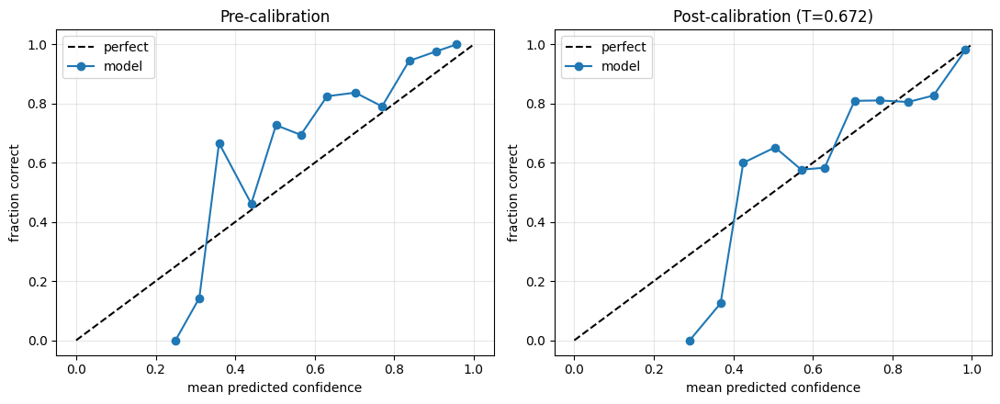

In [ ]:
# ===== STEP 19: Phase 8c — temperature calibration of EfficientNet-B0 C1 seed 42 =====
import json, numpy as np, pandas as pd, torch, torch.nn as nn
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms as T

assert torch.cuda.is_available(), "CUDA not available"
dev = "cuda"

P     = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
CLEAN = Path('/content/data/clean')
CK    = P/'outputs'/'checkpoints'

l2i = json.load(open(P/'outputs/label_to_idx.json'))
DISPLAY_ORDER = ['A+','A-','B+','B-','AB+','AB-','O+','O-']
va = pd.read_csv(P/'splits/val.csv')          # TEST CSV NOT loaded

rs   = T.Resize((224, 224))
norm = T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
tf_eval = T.Compose([rs, T.ToTensor(), norm])

class DS(Dataset):
    def __init__(s, df, tf): s.df, s.tf = df.reset_index(drop=True), tf
    def __len__(s): return len(s.df)
    def __getitem__(s, i):
        r = s.df.iloc[i]
        return s.tf(Image.open(CLEAN/r['path']).convert('RGB')), l2i[r['label']]

dl_va = DataLoader(DS(va, tf_eval), 64, shuffle=False, num_workers=2)

m = models.efficientnet_b0(weights=None)
m.classifier[1] = nn.Linear(m.classifier[1].in_features, 8)
m.load_state_dict(torch.load(CK/'efficientnet_b0_seed42_best.pt', map_location=dev))
m = m.to(dev).eval()

# --- extract logits (not probs) ---
ys, logits = [], []
with torch.no_grad():
    for x, y in dl_va:
        out = m(x.to(dev))
        logits.append(out.cpu().numpy())
        ys += y.tolist()
logits = np.concatenate(logits, axis=0).astype(np.float64)   # (830, 8)
ys = np.array(ys)
print(f"Logits shape: {logits.shape}")

# --- metrics ---
def softmax_np(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

def nll(probs, y):
    return float(-np.log(np.clip(probs[np.arange(len(y)), y], 1e-12, 1.0)).mean())

def brier(probs, y):
    onehot = np.eye(probs.shape[1])[y]
    return float(((probs - onehot) ** 2).sum(axis=1).mean())

def ece(probs, y, n_bins=15):
    conf = probs.max(axis=1)
    pred = probs.argmax(axis=1)
    acc  = (pred == y).astype(float)
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    e = 0.0
    for i in range(n_bins):
        lo, hi = bins[i], bins[i+1]
        mask = (conf >= lo) & (conf < hi if i < n_bins-1 else conf <= hi)
        if mask.sum() == 0: continue
        e += mask.mean() * abs(acc[mask].mean() - conf[mask].mean())
    return float(e)

# --- fit T by grid search on NLL ---
Ts = np.exp(np.linspace(np.log(0.1), np.log(10.0), 400))
nlls = [nll(softmax_np(logits / T), ys) for T in Ts]
T_best = float(Ts[int(np.argmin(nlls))])
print(f"Best temperature: T = {T_best:.4f}")

probs_pre  = softmax_np(logits)
probs_post = softmax_np(logits / T_best)

print("\n" + "="*72)
print(f"{'metric':10s} {'pre-calibration':>18s} {'post-calibration':>18s}")
print("-"*72)
print(f"{'NLL':10s} {nll(probs_pre, ys):>18.4f} {nll(probs_post, ys):>18.4f}")
print(f"{'Brier':10s} {brier(probs_pre, ys):>18.4f} {brier(probs_post, ys):>18.4f}")
print(f"{'ECE (15 bins)':10s} {ece(probs_pre, ys):>18.4f} {ece(probs_post, ys):>18.4f}")
print("="*72)
print("Note: post-calibration ECE is optimistic (T fit on same val data).")
print("      The honest ECE is measured at Phase 9 on the test set with this T.")

# --- save T and logits ---
np.savez(P/'outputs/phase8c_temperature_efficientnet_b0_seed42.npz',
         T=T_best, logits=logits, y_true=ys,
         label_order=np.array(list(l2i.keys())))
print(f"\nSaved T={T_best:.4f} and val logits to outputs/phase8c_temperature_efficientnet_b0_seed42.npz")

# --- reliability plot ---
try:
    import matplotlib.pyplot as plt
    def reliability_bins(probs, y, n_bins=15):
        conf = probs.max(axis=1)
        pred = probs.argmax(axis=1)
        acc  = (pred == y).astype(float)
        bins = np.linspace(0.0, 1.0, n_bins + 1)
        cs, as_, ns = [], [], []
        for i in range(n_bins):
            lo, hi = bins[i], bins[i+1]
            mask = (conf >= lo) & (conf < hi if i < n_bins-1 else conf <= hi)
            if mask.sum() == 0: continue
            cs.append(conf[mask].mean()); as_.append(acc[mask].mean()); ns.append(int(mask.sum()))
        return np.array(cs), np.array(as_), np.array(ns)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    for ax, probs, title in zip(axes, [probs_pre, probs_post],
                                 ["Pre-calibration", f"Post-calibration (T={T_best:.3f})"]):
        cs, as_, ns = reliability_bins(probs, ys)
        ax.plot([0,1],[0,1], 'k--', label='perfect')
        ax.plot(cs, as_, 'o-', label='model')
        ax.set_xlabel('mean predicted confidence')
        ax.set_ylabel('fraction correct')
        ax.set_title(title)
        ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(P/'outputs/phase8c_reliability_efficientnet_b0_seed42.png', dpi=150)
    print("Saved reliability plot to outputs/phase8c_reliability_efficientnet_b0_seed42.png")
except Exception as e:
    print(f"(plot skipped: {e})")

Loaded 3 seeds; ensemble shape: (830, 8); paths: 830

=== Ensemble (raw probs) ===
accuracy=0.9060  macro_f1=0.9065  balanced_acc=0.9107
NLL=0.3271  Brier=0.1477  ECE=0.1032

Ensemble temperature: T_ens = 0.5983

=== Ensemble (calibrated) ===
accuracy=0.9060  macro_f1=0.9065  balanced_acc=0.9107
NLL=0.2506  Brier=0.1334  ECE=0.0139

Single-seed macro-F1: 0.9056, 0.9014, 0.8996
Single-seed mean ± SD: 0.9022 ± 0.0031
Ensemble (raw) macro-F1: 0.9065   Δ vs single mean: +0.43 pp
Ensemble (cal) macro-F1: 0.9065  Δ vs single mean: +0.43 pp

Risk-coverage curve (calibrated ensemble):
 coverage  n_included  accuracy  error  confidence_threshold
   0.1000          83    1.0000 0.0000                0.9981
   0.1500         125    1.0000 0.0000                0.9975
   0.2000         166    1.0000 0.0000                0.9968
   0.2500         208    1.0000 0.0000                0.9961
   0.3000         249    1.0000 0.0000                0.9951
   0.3500         290    1.0000 0.0000            

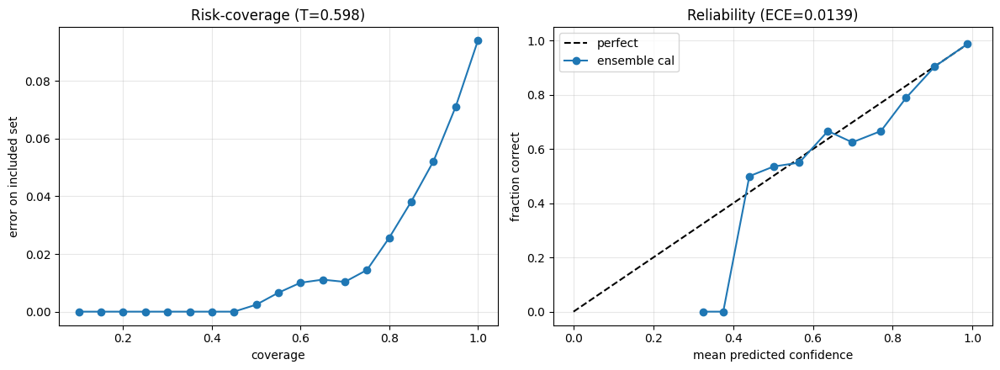

In [ ]:
# ===== STEP 20 (corrected): Phase 8d — 3-seed EfficientNet-B0 C1 ensemble + calib + selective prediction =====
import json, numpy as np, pandas as pd
from pathlib import Path
from sklearn.metrics import f1_score, accuracy_score, balanced_accuracy_score

P     = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
OUT   = P/'outputs'

l2i = json.load(open(P/'outputs/label_to_idx.json'))
DISPLAY_ORDER = ['A+','A-','B+','B-','AB+','AB-','O+','O-']
idx_to_display = {l2i[l]: l for l in DISPLAY_ORDER}

# ---- load 3 seeds (numeric fields only; do NOT touch d['paths']) ----
seeds = [42, 43, 44]
probs_list, ys_ref = [], None
for s in seeds:
    d = np.load(OUT/f'phase7_efficientnet_b0_seed{s}_val_preds.npz')
    probs_list.append(d['probs'])
    if ys_ref is None:
        ys_ref = d['y_true_idx']
    else:
        assert np.array_equal(ys_ref, d['y_true_idx']), "seed y_true mismatch"

# paths come from val.csv, NOT from the npz (avoids the object-array issue)
va = pd.read_csv(P/'splits/val.csv')
paths_ref = np.asarray(va['path'].values, dtype=str)      # unicode <U..., no pickle needed

probs_ens = np.mean(probs_list, axis=0)
ys = ys_ref
ys_str = np.array([idx_to_display[i] for i in ys])
print(f"Loaded {len(seeds)} seeds; ensemble shape: {probs_ens.shape}; paths: {len(paths_ref)}")

# ---- helpers ----
def softmax_np(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

def nll(probs, y):
    return float(-np.log(np.clip(probs[np.arange(len(y)), y], 1e-12, 1.0)).mean())

def brier(probs, y):
    onehot = np.eye(probs.shape[1])[y]
    return float(((probs - onehot) ** 2).sum(axis=1).mean())

def ece(probs, y, n_bins=15):
    conf = probs.max(axis=1); pred = probs.argmax(axis=1)
    acc = (pred == y).astype(float)
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    e = 0.0
    for i in range(n_bins):
        lo, hi = bins[i], bins[i+1]
        mask = (conf >= lo) & (conf < hi if i < n_bins-1 else conf <= hi)
        if mask.sum() == 0: continue
        e += mask.mean() * abs(acc[mask].mean() - conf[mask].mean())
    return float(e)

# ---- ensemble raw ----
ps_ens = probs_ens.argmax(axis=1)
ps_ens_str = np.array([idx_to_display[i] for i in ps_ens])
acc_pre  = accuracy_score(ys_str, ps_ens_str)
mf1_pre  = f1_score(ys_str, ps_ens_str, average='macro')
bacc_pre = balanced_accuracy_score(ys_str, ps_ens_str)
print("\n=== Ensemble (raw probs) ===")
print(f"accuracy={acc_pre:.4f}  macro_f1={mf1_pre:.4f}  balanced_acc={bacc_pre:.4f}")
print(f"NLL={nll(probs_ens, ys):.4f}  Brier={brier(probs_ens, ys):.4f}  ECE={ece(probs_ens, ys):.4f}")

# ---- fit T on ensemble probs ----
logits_ens_equiv = np.log(np.clip(probs_ens, 1e-12, 1.0))
Ts = np.exp(np.linspace(np.log(0.1), np.log(10.0), 400))
nlls = [nll(softmax_np(logits_ens_equiv / T), ys) for T in Ts]
T_ens = float(Ts[int(np.argmin(nlls))])
print(f"\nEnsemble temperature: T_ens = {T_ens:.4f}")

probs_ens_cal = softmax_np(logits_ens_equiv / T_ens)
ps_ens_cal  = probs_ens_cal.argmax(axis=1)
ps_ens_cal_str = np.array([idx_to_display[i] for i in ps_ens_cal])
acc_post  = accuracy_score(ys_str, ps_ens_cal_str)
mf1_post  = f1_score(ys_str, ps_ens_cal_str, average='macro')
bacc_post = balanced_accuracy_score(ys_str, ps_ens_cal_str)
print("\n=== Ensemble (calibrated) ===")
print(f"accuracy={acc_post:.4f}  macro_f1={mf1_post:.4f}  balanced_acc={bacc_post:.4f}")
print(f"NLL={nll(probs_ens_cal, ys):.4f}  Brier={brier(probs_ens_cal, ys):.4f}  ECE={ece(probs_ens_cal, ys):.4f}")

# ---- single-seed reference ----
mf1s = []
for s in seeds:
    d = np.load(OUT/f'phase7_efficientnet_b0_seed{s}_val_preds.npz')
    p = d['probs'].argmax(axis=1)
    p_str = np.array([idx_to_display[i] for i in p])
    mf1s.append(f1_score(ys_str, p_str, average='macro'))
mf1s = np.array(mf1s)
print(f"\nSingle-seed macro-F1: {', '.join(f'{v:.4f}' for v in mf1s)}")
print(f"Single-seed mean ± SD: {mf1s.mean():.4f} ± {mf1s.std(ddof=1):.4f}")
print(f"Ensemble (raw) macro-F1: {mf1_pre:.4f}   Δ vs single mean: {(mf1_pre - mf1s.mean())*100:+.2f} pp")
print(f"Ensemble (cal) macro-F1: {mf1_post:.4f}  Δ vs single mean: {(mf1_post - mf1s.mean())*100:+.2f} pp")

# ---- risk-coverage curve ----
conf  = probs_ens_cal.max(axis=1)
pred  = probs_ens_cal.argmax(axis=1)
correct = (pred == ys).astype(float)
order = np.argsort(-conf)
sorted_correct = correct[order]
sorted_conf    = conf[order]

coverages = np.linspace(0.10, 1.00, 19)
rows = []
for c in coverages:
    k = int(round(c * len(ys)))
    if k == 0: continue
    rows.append(dict(coverage=float(c), n_included=k,
                     accuracy=float(sorted_correct[:k].mean()),
                     error=float(1.0 - sorted_correct[:k].mean()),
                     confidence_threshold=float(sorted_conf[k-1])))
rc_df = pd.DataFrame(rows)
print("\nRisk-coverage curve (calibrated ensemble):")
print(rc_df.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
rc_df.to_csv(OUT/'phase8d_ensemble_risk_coverage.csv', index=False)

print("\nSuggested abstention thresholds (from val):")
for target_cov in (0.95, 0.90, 0.85, 0.80):
    row = rc_df.iloc[(rc_df['coverage'] - target_cov).abs().argsort()[:1]].iloc[0]
    print(f"  coverage {row['coverage']:.2f} -> threshold {row['confidence_threshold']:.4f}, "
          f"accuracy on included {row['accuracy']:.4f}")

# ---- save (paths as unicode, not object → future loads don't need allow_pickle) ----
np.savez(OUT/'phase8d_ensemble_efficientnet_b0_val.npz',
         probs_cal=probs_ens_cal, probs_raw=probs_ens,
         y_true=ys, y_pred_cal=ps_ens_cal,
         paths=paths_ref, T_ens=T_ens,
         label_order=np.array(list(l2i.keys())))
print(f"\nSaved phase8d_ensemble_efficientnet_b0_val.npz "
      f"(paths dtype: {paths_ref.dtype})")

# ---- plots ----
try:
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].plot(rc_df['coverage'], rc_df['error'], 'o-')
    axes[0].set_xlabel('coverage'); axes[0].set_ylabel('error on included set')
    axes[0].set_title(f'Risk-coverage (T={T_ens:.3f})'); axes[0].grid(alpha=0.3)

    def reliability_bins(probs, y, n_bins=15):
        c = probs.max(axis=1); p = probs.argmax(axis=1)
        a = (p == y).astype(float)
        bins = np.linspace(0.0, 1.0, n_bins + 1)
        cs, as_ = [], []
        for i in range(n_bins):
            lo, hi = bins[i], bins[i+1]
            mask = (c >= lo) & (c < hi if i < n_bins-1 else c <= hi)
            if mask.sum() == 0: continue
            cs.append(c[mask].mean()); as_.append(a[mask].mean())
        return np.array(cs), np.array(as_)

    cs, as_ = reliability_bins(probs_ens_cal, ys)
    axes[1].plot([0,1],[0,1],'k--',label='perfect')
    axes[1].plot(cs, as_,'o-',label='ensemble cal')
    axes[1].set_xlabel('mean predicted confidence'); axes[1].set_ylabel('fraction correct')
    axes[1].set_title(f'Reliability (ECE={ece(probs_ens_cal, ys):.4f})')
    axes[1].legend(); axes[1].grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(OUT/'phase8d_ensemble_risk_reliability.png', dpi=150)
    print("Saved phase8d_ensemble_risk_reliability.png")
except Exception as e:
    print(f"(plot skipped: {e})")

In [ ]:
# ===== STEP 22: Pre-registration — checkpoint checksums =====
import hashlib
from pathlib import Path

P  = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
CK = P/'outputs'/'checkpoints'

seeds = [42, 43, 44]
print("Pre-registration: EfficientNet-B0 C1 3-seed ensemble\n")

checksums = {}
for s in seeds:
    ckpt = CK/f'efficientnet_b0_seed{s}_best.pt'
    assert ckpt.exists(), f"MISSING {ckpt.name}"

    # Compute SHA-256
    h = hashlib.sha256()
    with open(ckpt, 'rb') as f:
        for chunk in iter(lambda: f.read(8192), b""):
            h.update(chunk)
    checksums[s] = h.hexdigest()
    print(f"Seed {s}: {ckpt.name}  ({ckpt.stat().st_size/1e6:.2f} MB)")
    print(f"  SHA-256: {checksums[s]}")

print("\n--- Final Configuration Confirmation ---")
print("Model: 3-seed ensemble (EfficientNet-B0 C1, seeds 42/43/44)")
print("Averaging: Arithmetic mean of seed softmax probabilities")
print("Calibration: T_ens = 0.5983 applied to mean probabilities")
print("Selective: Threshold = 0.6865 (90% val coverage)")

# Save a manifest file
manifest = P/'outputs/phase9_preregistration_manifest.txt'
with open(manifest, 'w') as f:
    f.write("Phase 9 Pre-registration Manifest\n")
    f.write("================================\n")
    f.write("Ensemble: EfficientNet-B0 C1, seeds 42/43/44\n")
    f.write("T_ens: 0.5983\n")
    f.write("Selective threshold: 0.6865\n")
    for s, c in checksums.items():
        f.write(f"seed{s}: {c}\n")
print(f"\nSaved manifest to {manifest.name}")

Pre-registration: EfficientNet-B0 C1 3-seed ensemble

Seed 42: efficientnet_b0_seed42_best.pt  (16.38 MB)
  SHA-256: 9eb9d4df4203a472c82f6d1d0817af6e49c739dd560fd33b9aec98d87da140cd
Seed 43: efficientnet_b0_seed43_best.pt  (16.38 MB)
  SHA-256: 40543b8536763f722d5ff0b77e734b780ace3644bf40d37fee3798c41ab8df15
Seed 44: efficientnet_b0_seed44_best.pt  (16.38 MB)
  SHA-256: 7469e648b5f121ede55e513b5d9759b8b56bc89f4312cd9c33019ef1910a688e

--- Final Configuration Confirmation ---
Model: 3-seed ensemble (EfficientNet-B0 C1, seeds 42/43/44)
Averaging: Arithmetic mean of seed softmax probabilities
Calibration: T_ens = 0.5983 applied to mean probabilities
Selective: Threshold = 0.6865 (90% val coverage)

Saved manifest to phase9_preregistration_manifest.txt


TEST SET: 842 images
Loading seed 42...
  seed 42 acc: 0.8836  (n=842)
Loading seed 43...
  seed 43 acc: 0.8694  (n=842)
Loading seed 44...
  seed 44 acc: 0.8777  (n=842)

Total test labels accumulated: 842

PHASE 9 — FINAL TEST RESULTS

--- Full 8-class (100% coverage, calibrated ensemble) ---
Accuracy:          0.8824 (88.24%)
Macro-F1:          0.8807 (88.07%)
Balanced accuracy: 0.8829 (88.29%)

Target: 93.5% acc / 92.3% F1
Delta:  -5.26 pp acc / -4.23 pp F1
Result: TARGET NOT MET (honest-outcome clause applies)

--- Selective prediction (threshold 0.6865) ---
Coverage:            0.8860 (746/842 images accepted)
Accuracy (accepted): 0.9330 (93.30%)
Macro-F1 (accepted): 0.9317 (93.17%)
Abstained:           96 images (11.4%)

--- Selective prediction (supplementary) ---
Pre-declared threshold 0.5489 (val 95% coverage) -> test coverage 0.9572, test acc 0.9020
Pre-declared threshold 0.6865 (val 90% coverage) -> test coverage 0.8860, test acc 0.9330

Confusion matrix (test, calibrated e

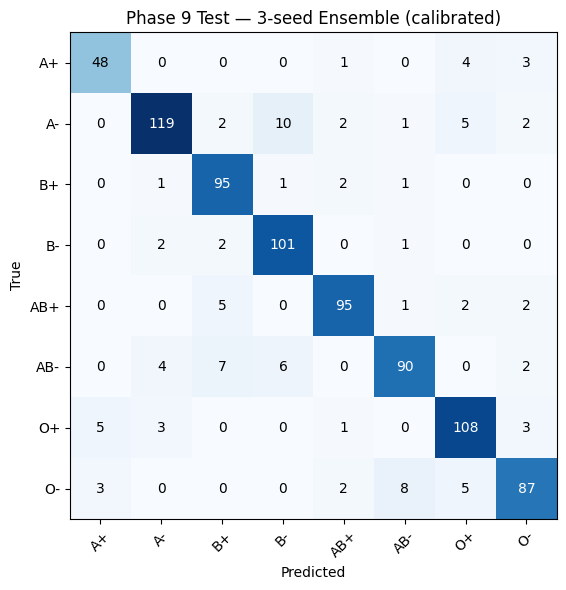

In [ ]:
# ===== STEP 23 (corrected): PHASE 9 — FINAL TEST EVALUATION (ONE TIME ONLY) =====
import json, time, numpy as np, pandas as pd, torch, torch.nn as nn
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms as T
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score,
                             confusion_matrix)

assert torch.cuda.is_available(), "CUDA not available"
dev = "cuda"

P     = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
CLEAN = Path('/content/data/clean')
CK    = P/'outputs'/'checkpoints'

l2i = json.load(open(P/'outputs/label_to_idx.json'))
DISPLAY_ORDER = ['A+','A-','B+','B-','AB+','AB-','O+','O-']
idx_to_display = {l2i[l]: l for l in DISPLAY_ORDER}

te = pd.read_csv(P/'splits/test.csv')
print(f"TEST SET: {len(te)} images")

rs   = T.Resize((224, 224))
norm = T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
tf_eval = T.Compose([rs, T.ToTensor(), norm])

class DS(Dataset):
    def __init__(s, df, tf): s.df, s.tf = df.reset_index(drop=True), tf
    def __len__(s): return len(s.df)
    def __getitem__(s, i):
        r = s.df.iloc[i]
        return s.tf(Image.open(CLEAN/r['path']).convert('RGB')), l2i[r['label']]

dl_te = DataLoader(DS(te, tf_eval), 64, shuffle=False, num_workers=2)

ys = None
probs_list = []
for seed in [42, 43, 44]:
    ckpt = CK/f'efficientnet_b0_seed{seed}_best.pt'
    print(f"Loading seed {seed}...")
    m = models.efficientnet_b0(weights=None)
    m.classifier[1] = nn.Linear(m.classifier[1].in_features, 8)
    m.load_state_dict(torch.load(ckpt, map_location=dev))
    m = m.to(dev).eval()

    ps, probs, seed_ys = [], [], []
    with torch.no_grad():
        for x, y in dl_te:
            out = m(x.to(dev))
            probs.append(torch.softmax(out, dim=1).cpu().numpy())
            ps += out.argmax(1).cpu().tolist()
            seed_ys += y.tolist()          # <-- accumulate for EVERY batch

    probs_list.append(np.concatenate(probs, axis=0))
    if ys is None:
        ys = seed_ys                        # set once from seed 42
    print(f"  seed {seed} acc: {accuracy_score(ys, ps):.4f}  (n={len(ps)})")

ys = np.array(ys)
ys_str = np.array([idx_to_display[i] for i in ys])
print(f"\nTotal test labels accumulated: {len(ys)}")

# 1. Ensemble (raw)
probs_ens_raw = np.mean(probs_list, axis=0)
ps_ens = probs_ens_raw.argmax(axis=1)

# 2. Ensemble (calibrated)
T_ENS = 0.5983
logits_equiv = np.log(np.clip(probs_ens_raw, 1e-12, 1.0))
probs_ens_cal = np.exp(logits_equiv / T_ENS)
probs_ens_cal /= probs_ens_cal.sum(axis=1, keepdims=True)
ps_cal = probs_ens_cal.argmax(axis=1)
ps_cal_str = np.array([idx_to_display[i] for i in ps_cal])

print("\n" + "="*60)
print("PHASE 9 — FINAL TEST RESULTS")
print("="*60)

acc_full  = accuracy_score(ys_str, ps_cal_str)
mf1_full  = f1_score(ys_str, ps_cal_str, average='macro')
bacc_full = balanced_accuracy_score(ys_str, ps_cal_str)

print(f"\n--- Full 8-class (100% coverage, calibrated ensemble) ---")
print(f"Accuracy:          {acc_full:.4f} ({acc_full*100:.2f}%)")
print(f"Macro-F1:          {mf1_full:.4f} ({mf1_full*100:.2f}%)")
print(f"Balanced accuracy: {bacc_full:.4f} ({bacc_full*100:.2f}%)")
print(f"\nTarget: 93.5% acc / 92.3% F1")
print(f"Delta:  {(acc_full - 0.935)*100:+.2f} pp acc / {(mf1_full - 0.923)*100:+.2f} pp F1")
print(f"Result: {'TARGET MET' if (acc_full >= 0.935 and mf1_full >= 0.923) else 'TARGET NOT MET (honest-outcome clause applies)'}")

# Selective Prediction
THRESH = 0.6865
max_probs = probs_ens_cal.max(axis=1)
accepted = max_probs >= THRESH

cov = np.nan
acc_sel = np.nan
mf1_sel = np.nan
if accepted.sum() > 0:
    acc_sel = accuracy_score(ys_str[accepted], ps_cal_str[accepted])
    mf1_sel = f1_score(ys_str[accepted], ps_cal_str[accepted], average='macro')
    cov = accepted.sum() / len(accepted)
    print(f"\n--- Selective prediction (threshold {THRESH}) ---")
    print(f"Coverage:            {cov:.4f} ({accepted.sum()}/{len(accepted)} images accepted)")
    print(f"Accuracy (accepted): {acc_sel:.4f} ({acc_sel*100:.2f}%)")
    print(f"Macro-F1 (accepted): {mf1_sel:.4f} ({mf1_sel*100:.2f}%)")
    print(f"Abstained:           {len(accepted)-accepted.sum()} images ({(1-cov)*100:.1f}%)")

# 95% coverage point (supplementary)
print(f"\n--- Selective prediction (supplementary) ---")
for target_cov, t_val in [(0.95, 0.5489), (0.90, 0.6865)]:
    acc_mask = max_probs >= t_val
    if acc_mask.sum() > 0:
        a = accuracy_score(ys_str[acc_mask], ps_cal_str[acc_mask])
        c = acc_mask.sum()/len(acc_mask)
        print(f"Pre-declared threshold {t_val:.4f} (val {target_cov*100:.0f}% coverage) -> "
              f"test coverage {c:.4f}, test acc {a:.4f}")

# Confusion matrix
cm = confusion_matrix(ys_str, ps_cal_str, labels=DISPLAY_ORDER)
cm_df = pd.DataFrame(cm, index=[f"true_{l}" for l in DISPLAY_ORDER],
                        columns=[f"pred_{l}" for l in DISPLAY_ORDER])
print("\nConfusion matrix (test, calibrated ensemble):")
print(cm_df.to_string())

# Save artifacts
OUT = P/'outputs'
np.savez(OUT/'phase9_test_results.npz',
         probs_raw=probs_ens_raw, probs_cal=probs_ens_cal,
         y_true=ys, y_pred=ps_cal,
         paths=np.array(te['path'].values, dtype=str),
         T_ens=T_ENS, threshold=THRESH,
         accepted=accepted,
         label_order=np.array(list(l2i.keys())))
cm_df.to_csv(OUT/'phase9_test_confusion_matrix.csv')

pd.DataFrame([dict(
    config='efficientnet_b0_3seed_ensemble_calibrated',
    n_test=len(ys_str),
    acc_full=acc_full, mf1_full=mf1_full, bacc_full=bacc_full,
    selective_cov=cov, selective_acc=acc_sel, selective_mf1=mf1_sel,
    threshold=THRESH, T_ens=T_ENS
)]).to_csv(OUT/'phase9_test_summary.csv', index=False)

print(f"\nAll Phase 9 artifacts saved to {OUT}")

try:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(7,6))
    ax.imshow(cm, cmap='Blues')
    ax.set_xticks(range(8)); ax.set_yticks(range(8))
    ax.set_xticklabels(DISPLAY_ORDER, rotation=45)
    ax.set_yticklabels(DISPLAY_ORDER)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    for i in range(8):
        for j in range(8):
            ax.text(j, i, cm[i,j], ha='center', va='center',
                    color='white' if cm[i,j] > cm.max()/2 else 'black')
    plt.title('Phase 9 Test — 3-seed Ensemble (calibrated)')
    plt.tight_layout()
    plt.savefig(OUT/'phase9_test_confusion_matrix.png', dpi=150)
    print("Saved phase9_test_confusion_matrix.png")
except Exception as e:
    print(f"(plot skipped: {e})")

In [ ]:
# ===== STEP 24A: Build background-only images (mask center) =====
import numpy as np, pandas as pd
from pathlib import Path
from PIL import Image

SRC = Path('/content/data/clean')
DST = Path('/content/data/clean_background')
assert SRC.exists(), "clean/ missing"

P  = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
tr = pd.read_csv(P/'splits/train.csv')
va = pd.read_csv(P/'splits/val.csv')

all_paths = set(tr['path']).union(set(va['path']))
print(f"Paths to build: {len(all_paths)}")

count = 0
for rel in all_paths:
    src_f = SRC/rel
    dst_f = DST/rel
    if not src_f.exists(): continue
    dst_f.parent.mkdir(parents=True, exist_ok=True)

    # Composite to RGB
    img = Image.open(src_f).convert('RGB')
    arr = np.array(img)

    # Mask the center: keep only a 20-pixel border
    # (Images are 96x103 -> resized to 224 later. 20px native = ~46px at 224)
    masked = arr.copy()
    masked[20:-20, 20:-20] = 255   # fill center with white

    Image.fromarray(masked).save(dst_f)
    count += 1

print(f"Built {count} background-masked images.")
print(f"Destination: {DST}")

# Visual sanity check on one sample
sample = tr['path'].iloc[0]
src_arr = np.array(Image.open(SRC/sample).convert('RGB'))
dst_arr = np.array(Image.open(DST/sample).convert('RGB'))
print(f"\nSample: {sample}")
print(f"  Original center mean: {src_arr[30:-30, 30:-30].mean():.1f}")
print(f"  Masked center mean:   {dst_arr[30:-30, 30:-30].mean():.1f} (should be 255)")
print(f"  Original border mean: {np.concatenate([src_arr[:20].flatten(), src_arr[-20:].flatten()]).mean():.1f}")
print(f"  Masked border mean:   {np.concatenate([dst_arr[:20].flatten(), dst_arr[-20:].flatten()]).mean():.1f} (should match original)")

Paths to build: 4995
Built 4995 background-masked images.
Destination: /content/data/clean_background

Sample: O-/cluster_7_3987.BMP
  Original center mean: 72.8
  Masked center mean:   255.0 (should be 255)
  Original border mean: 153.1
  Masked border mean:   153.1 (should match original)


In [ ]:
# ===== STEP 24B: Background-only audit (10 epochs) =====
import json, random, time, numpy as np, pandas as pd, torch, torch.nn as nn
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms as T
from sklearn.metrics import f1_score

BACKBONE = "efficientnet_b0"
TAG      = "bg_only"
SEED, BS = 42, 32
HEAD_EP, FT_EP, PATIENCE = 3, 7, 8    # Shortened run for audit

assert torch.cuda.is_available(), "CUDA not available"
dev = "cuda"
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

P     = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
CLEAN = Path('/content/data/clean_background')  # <-- Masked images
CK    = P/'outputs'/'checkpoints'; CK.mkdir(parents=True, exist_ok=True)
assert CLEAN.exists(), "clean_background/ missing — run Step 24A first"

l2i = json.load(open(P/'outputs/label_to_idx.json'))
tr  = pd.read_csv(P/'splits/train.csv')
va  = pd.read_csv(P/'splits/val.csv')

rs   = T.Resize((224, 224))
norm = T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
tf_train = T.Compose([rs, T.RandomAffine(10, translate=(0.05,0.05), scale=(0.95,1.05), fill=255),
                      T.ColorJitter(0.1, 0.1), T.ToTensor(), norm])
tf_eval  = T.Compose([rs, T.ToTensor(), norm])

class DS(Dataset):
    def __init__(s, df, tf): s.df, s.tf = df.reset_index(drop=True), tf
    def __len__(s): return len(s.df)
    def __getitem__(s, i):
        r = s.df.iloc[i]
        return s.tf(Image.open(CLEAN/r['path']).convert('RGB')), l2i[r['label']]

g = torch.Generator().manual_seed(SEED)
dl_tr = DataLoader(DS(tr, tf_train), BS, shuffle=True, num_workers=2, generator=g, drop_last=True)
dl_va = DataLoader(DS(va, tf_eval), BS*2, shuffle=False, num_workers=2)

model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, 8)
head = model.classifier
model = model.to(dev)

cw     = torch.load(P/'outputs/class_weights.pt').float().to(dev)
crit   = nn.CrossEntropyLoss(weight=cw, label_smoothing=0.1)
scaler = torch.amp.GradScaler("cuda")

def run_epoch(loader, opt=None):
    train = opt is not None
    model.train(train); ys, ps, tot = [], [], 0.0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(dev), y.to(dev)
            with torch.autocast("cuda", dtype=torch.float16):
                out = model(x); loss = crit(out, y)
            if train:
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item()*len(y); ys += y.tolist(); ps += out.argmax(1).tolist()
    return tot/len(ys), float(np.mean(np.array(ys)==np.array(ps))), f1_score(ys, ps, average='macro')

log, best, bad = [], -1, 0
ckpt_path = CK/f'{BACKBONE}_{TAG}_seed{SEED}_best.pt'
log_path  = P/f'outputs/{BACKBONE}_{TAG}_seed{SEED}_train_log.csv'

def fit(epochs, opt, sched, stage):
    global best, bad
    for ep in range(epochs):
        t0 = time.time()
        trl, tra, trf = run_epoch(dl_tr, opt)
        val, vaa, vaf = run_epoch(dl_va)
        if sched: sched.step()
        log.append(dict(stage=stage, ep=ep+1, tr_loss=trl, tr_acc=tra, tr_f1=trf,
                        va_loss=val, va_acc=vaa, va_f1=vaf))
        print(f"[{stage}] {ep+1:02d} tr_acc {tra:.3f} va_acc {vaa:.3f} va_F1 {vaf:.3f} ({time.time()-t0:.0f}s)")
        if vaf > best:
            best, bad = vaf, 0
            torch.save(model.state_dict(), ckpt_path)
        elif stage == "full":
            bad += 1
            if bad >= PATIENCE: print("Early stop"); return
        pd.DataFrame(log).to_csv(log_path, index=False)

for p in model.parameters(): p.requires_grad = False
for p in head.parameters():  p.requires_grad = True
fit(HEAD_EP, torch.optim.AdamW(head.parameters(), lr=1e-3, weight_decay=1e-4), None, "head")

for p in model.parameters(): p.requires_grad = True
opt = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
fit(FT_EP, opt, torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=FT_EP, eta_min=1e-6), "full")

pd.DataFrame(log).to_csv(log_path, index=False)
print(f"\nBest val macro-F1: {best:.4f}  |  checkpoint: {ckpt_path.name}  |  log: {log_path.name}")

# Comparison to majority baseline
print(f"Majority baseline (val): 0.1729")
print(f"Delta vs baseline: {(best - 0.1729)*100:+.2f} pp")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 67.9MB/s]


[head] 01 tr_acc 0.373 va_acc 0.504 va_F1 0.466 (33s)
[head] 02 tr_acc 0.500 va_acc 0.552 va_F1 0.535 (26s)
[head] 03 tr_acc 0.537 va_acc 0.596 va_F1 0.579 (26s)
[full] 01 tr_acc 0.654 va_acc 0.765 va_F1 0.770 (25s)
[full] 02 tr_acc 0.755 va_acc 0.816 va_F1 0.816 (22s)
[full] 03 tr_acc 0.789 va_acc 0.830 va_F1 0.833 (25s)
[full] 04 tr_acc 0.801 va_acc 0.839 va_F1 0.840 (36s)
[full] 05 tr_acc 0.830 va_acc 0.837 va_F1 0.837 (31s)
[full] 06 tr_acc 0.838 va_acc 0.855 va_F1 0.856 (23s)
[full] 07 tr_acc 0.844 va_acc 0.843 va_F1 0.846 (25s)

Best val macro-F1: 0.8558  |  checkpoint: efficientnet_b0_bg_only_seed42_best.pt  |  log: efficientnet_b0_bg_only_seed42_train_log.csv
Majority baseline (val): 0.1729
Delta vs baseline: +68.29 pp


In [ ]:
# ===== STEP 25A: Build center-only images (mask border) =====
import numpy as np, pandas as pd
from pathlib import Path
from PIL import Image

SRC = Path('/content/data/clean')
DST = Path('/content/data/clean_center_only')

P  = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
tr = pd.read_csv(P/'splits/train.csv')
va = pd.read_csv(P/'splits/val.csv')

all_paths = set(tr['path']).union(set(va['path']))
print(f"Paths to build: {len(all_paths)}")

count = 0
for rel in all_paths:
    src_f = SRC/rel
    dst_f = DST/rel
    if not src_f.exists(): continue
    dst_f.parent.mkdir(parents=True, exist_ok=True)

    img = Image.open(src_f).convert('RGB')
    arr = np.array(img)

    # Mask the border: keep only the center (remove outer 20 pixels)
    masked = arr.copy()
    masked[:20, :] = 255   # top border
    masked[-20:, :] = 255  # bottom border
    masked[:, :20] = 255   # left border
    masked[:, -20:] = 255  # right border

    Image.fromarray(masked).save(dst_f)
    count += 1

print(f"Built {count} center-only images.")
print(f"Destination: {DST}")

# Visual sanity check
sample = tr['path'].iloc[0]
dst_arr = np.array(Image.open(DST/sample).convert('RGB'))
print(f"\nSample: {sample}")
print(f"  Masked top border mean: {dst_arr[:20].mean():.1f} (should be 255)")
print(f"  Masked center mean:     {dst_arr[30:-30, 30:-30].mean():.1f} (should match original ~72.8)")

Paths to build: 4995
Built 4995 center-only images.
Destination: /content/data/clean_center_only

Sample: O-/cluster_7_3987.BMP
  Masked top border mean: 255.0 (should be 255)
  Masked center mean:     72.8 (should match original ~72.8)


In [ ]:
# ===== STEP 25B: Center-only audit (10 epochs) =====
import json, random, time, numpy as np, pandas as pd, torch, torch.nn as nn
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms as T
from sklearn.metrics import f1_score

BACKBONE = "efficientnet_b0"
TAG      = "center_only"
SEED, BS = 42, 32
HEAD_EP, FT_EP, PATIENCE = 3, 7, 8

assert torch.cuda.is_available(), "CUDA not available"
dev = "cuda"
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

P     = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
CLEAN = Path('/content/data/clean_center_only')  # <-- Center-only images
CK    = P/'outputs'/'checkpoints'; CK.mkdir(parents=True, exist_ok=True)
assert CLEAN.exists(), "clean_center_only/ missing — run Step 25A first"

l2i = json.load(open(P/'outputs/label_to_idx.json'))
tr  = pd.read_csv(P/'splits/train.csv')
va  = pd.read_csv(P/'splits/val.csv')

rs   = T.Resize((224, 224))
norm = T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
tf_train = T.Compose([rs, T.RandomAffine(10, translate=(0.05,0.05), scale=(0.95,1.05), fill=255),
                      T.ColorJitter(0.1, 0.1), T.ToTensor(), norm])
tf_eval  = T.Compose([rs, T.ToTensor(), norm])

class DS(Dataset):
    def __init__(s, df, tf): s.df, s.tf = df.reset_index(drop=True), tf
    def __len__(s): return len(s.df)
    def __getitem__(s, i):
        r = s.df.iloc[i]
        return s.tf(Image.open(CLEAN/r['path']).convert('RGB')), l2i[r['label']]

g = torch.Generator().manual_seed(SEED)
dl_tr = DataLoader(DS(tr, tf_train), BS, shuffle=True, num_workers=2, generator=g, drop_last=True)
dl_va = DataLoader(DS(va, tf_eval), BS*2, shuffle=False, num_workers=2)

model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, 8)
head = model.classifier
model = model.to(dev)

cw     = torch.load(P/'outputs/class_weights.pt').float().to(dev)
crit   = nn.CrossEntropyLoss(weight=cw, label_smoothing=0.1)
scaler = torch.amp.GradScaler("cuda")

def run_epoch(loader, opt=None):
    train = opt is not None
    model.train(train); ys, ps, tot = [], [], 0.0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(dev), y.to(dev)
            with torch.autocast("cuda", dtype=torch.float16):
                out = model(x); loss = crit(out, y)
            if train:
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item()*len(y); ys += y.tolist(); ps += out.argmax(1).tolist()
    return tot/len(ys), float(np.mean(np.array(ys)==np.array(ps))), f1_score(ys, ps, average='macro')

log, best, bad = [], -1, 0
ckpt_path = CK/f'{BACKBONE}_{TAG}_seed{SEED}_best.pt'
log_path  = P/f'outputs/{BACKBONE}_{TAG}_seed{SEED}_train_log.csv'

def fit(epochs, opt, sched, stage):
    global best, bad
    for ep in range(epochs):
        t0 = time.time()
        trl, tra, trf = run_epoch(dl_tr, opt)
        val, vaa, vaf = run_epoch(dl_va)
        if sched: sched.step()
        log.append(dict(stage=stage, ep=ep+1, tr_loss=trl, tr_acc=tra, tr_f1=trf,
                        va_loss=val, va_acc=vaa, va_f1=vaf))
        print(f"[{stage}] {ep+1:02d} tr_acc {tra:.3f} va_acc {vaa:.3f} va_F1 {vaf:.3f} ({time.time()-t0:.0f}s)")
        if vaf > best:
            best, bad = vaf, 0
            torch.save(model.state_dict(), ckpt_path)
        elif stage == "full":
            bad += 1
            if bad >= PATIENCE: print("Early stop"); return
        pd.DataFrame(log).to_csv(log_path, index=False)

for p in model.parameters(): p.requires_grad = False
for p in head.parameters():  p.requires_grad = True
fit(HEAD_EP, torch.optim.AdamW(head.parameters(), lr=1e-3, weight_decay=1e-4), None, "head")

for p in model.parameters(): p.requires_grad = True
opt = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
fit(FT_EP, opt, torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=FT_EP, eta_min=1e-6), "full")

pd.DataFrame(log).to_csv(log_path, index=False)
print(f"\nBest val macro-F1: {best:.4f}  |  checkpoint: {ckpt_path.name}  |  log: {log_path.name}")

print(f"Majority baseline (val): 0.1729")
print(f"Delta vs baseline: {(best - 0.1729)*100:+.2f} pp")

[head] 01 tr_acc 0.435 va_acc 0.578 va_F1 0.569 (37s)
[head] 02 tr_acc 0.556 va_acc 0.599 va_F1 0.594 (31s)
[head] 03 tr_acc 0.570 va_acc 0.637 va_F1 0.637 (24s)
[full] 01 tr_acc 0.694 va_acc 0.810 va_F1 0.812 (25s)
[full] 02 tr_acc 0.771 va_acc 0.834 va_F1 0.839 (23s)
[full] 03 tr_acc 0.819 va_acc 0.849 va_F1 0.851 (23s)
[full] 04 tr_acc 0.826 va_acc 0.866 va_F1 0.869 (24s)
[full] 05 tr_acc 0.850 va_acc 0.864 va_F1 0.866 (22s)
[full] 06 tr_acc 0.857 va_acc 0.872 va_F1 0.874 (23s)
[full] 07 tr_acc 0.868 va_acc 0.881 va_F1 0.883 (23s)

Best val macro-F1: 0.8826  |  checkpoint: efficientnet_b0_center_only_seed42_best.pt  |  log: efficientnet_b0_center_only_seed42_train_log.csv
Majority baseline (val): 0.1729
Delta vs baseline: +70.97 pp


In [ ]:
# ===== STEP 26: Phase 10 Audit 2 — duplicate-removal rerun (MD5-strict) =====
import json, random, time, hashlib, numpy as np, pandas as pd, torch, torch.nn as nn
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms as T
from sklearn.metrics import f1_score

BACKBONE = "efficientnet_b0"
TAG      = "dup_strict"
SEED, BS = 42, 32
HEAD_EP, FT_EP, PATIENCE = 3, 7, 8
MIN_TRAIN = 3500        # abort threshold

assert torch.cuda.is_available(), "CUDA not available"
dev = "cuda"
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

P     = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
CLEAN = Path('/content/data/clean')
CK    = P/'outputs'/'checkpoints'; CK.mkdir(parents=True, exist_ok=True)

l2i = json.load(open(P/'outputs/label_to_idx.json'))
tr  = pd.read_csv(P/'splits/train.csv')
va  = pd.read_csv(P/'splits/val.csv')

def md5_of(p):
    h = hashlib.md5()
    with open(p, 'rb') as f:
        for chunk in iter(lambda: f.read(8192), b""):
            h.update(chunk)
    return h.hexdigest()

print("Computing MD5s for val split...")
val_md5 = set(md5_of(CLEAN/r) for r in va['path'])
print(f"  distinct val MD5s: {len(val_md5)} / {len(va)}")

print("Computing MD5s for train split...")
train_md5 = [md5_of(CLEAN/r) for r in tr['path']]
keep_mask = np.array([h not in val_md5 for h in train_md5])
tr_strict = tr[keep_mask].reset_index(drop=True)
dropped = (~keep_mask).sum()
print(f"  train kept: {len(tr_strict)} / {len(tr)}; dropped {dropped} val-MD5 matches")

if len(tr_strict) < MIN_TRAIN:
    print(f"\nABORT: only {len(tr_strict)} train images remain (< {MIN_TRAIN}).")
    print("        D3 grouping appears already sufficient. Audit skipped, no limitation added.")
    raise SystemExit("Audit infeasible per pre-declared rule.")

rs   = T.Resize((224, 224))
norm = T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
tf_train = T.Compose([rs, T.RandomAffine(10, translate=(0.05,0.05), scale=(0.95,1.05), fill=255),
                      T.ColorJitter(0.1, 0.1), T.ToTensor(), norm])
tf_eval  = T.Compose([rs, T.ToTensor(), norm])

class DS(Dataset):
    def __init__(s, df, tf): s.df, s.tf = df.reset_index(drop=True), tf
    def __len__(s): return len(s.df)
    def __getitem__(s, i):
        r = s.df.iloc[i]
        return s.tf(Image.open(CLEAN/r['path']).convert('RGB')), l2i[r['label']]

g = torch.Generator().manual_seed(SEED)
dl_tr = DataLoader(DS(tr_strict, tf_train), BS, shuffle=True, num_workers=2, generator=g, drop_last=True)
dl_va = DataLoader(DS(va, tf_eval), BS*2, shuffle=False, num_workers=2)

model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, 8)
head = model.classifier
model = model.to(dev)

cw     = torch.load(P/'outputs/class_weights.pt').float().to(dev)
crit   = nn.CrossEntropyLoss(weight=cw, label_smoothing=0.1)
scaler = torch.amp.GradScaler("cuda")

def run_epoch(loader, opt=None):
    train = opt is not None
    model.train(train); ys, ps, tot = [], [], 0.0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(dev), y.to(dev)
            with torch.autocast("cuda", dtype=torch.float16):
                out = model(x); loss = crit(out, y)
            if train:
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item()*len(y); ys += y.tolist(); ps += out.argmax(1).tolist()
    return tot/len(ys), float(np.mean(np.array(ys)==np.array(ps))), f1_score(ys, ps, average='macro')

log, best, bad = [], -1, 0
ckpt_path = CK/f'{BACKBONE}_{TAG}_seed{SEED}_best.pt'
log_path  = P/f'outputs/{BACKBONE}_{TAG}_seed{SEED}_train_log.csv'

def fit(epochs, opt, sched, stage):
    global best, bad
    for ep in range(epochs):
        t0 = time.time()
        trl, tra, trf = run_epoch(dl_tr, opt)
        val, vaa, vaf = run_epoch(dl_va)
        if sched: sched.step()
        log.append(dict(stage=stage, ep=ep+1, tr_loss=trl, tr_acc=tra, tr_f1=trf,
                        va_loss=val, va_acc=vaa, va_f1=vaf))
        print(f"[{stage}] {ep+1:02d} tr_acc {tra:.3f} va_acc {vaa:.3f} va_F1 {vaf:.3f} ({time.time()-t0:.0f}s)")
        if vaf > best:
            best, bad = vaf, 0
            torch.save(model.state_dict(), ckpt_path)
        elif stage == "full":
            bad += 1
            if bad >= PATIENCE: print("Early stop"); return
        pd.DataFrame(log).to_csv(log_path, index=False)

for p in model.parameters(): p.requires_grad = False
for p in head.parameters():  p.requires_grad = True
fit(HEAD_EP, torch.optim.AdamW(head.parameters(), lr=1e-3, weight_decay=1e-4), None, "head")

for p in model.parameters(): p.requires_grad = True
opt = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
fit(FT_EP, opt, torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=FT_EP, eta_min=1e-6), "full")

pd.DataFrame(log).to_csv(log_path, index=False)
print(f"\nBest val macro-F1 (MD5-strict train): {best:.4f}")
print(f"  reference (full-data seed 42):       0.9056")
print(f"  delta: {(best - 0.9056)*100:+.2f} pp")
print(f"  decision rule: |delta| <= 2 pp -> D3 grouping validated")
print(f"  verdict: {'GROUPING VALIDATED' if abs(best - 0.9056) <= 0.02 else 'GROUPING TOO PERMISSIVE — document limitation'}")

Computing MD5s for val split...
  distinct val MD5s: 828 / 830
Computing MD5s for train split...
  train kept: 4165 / 4165; dropped 0 val-MD5 matches
[head] 01 tr_acc 0.370 va_acc 0.464 va_F1 0.448 (42s)
[head] 02 tr_acc 0.482 va_acc 0.501 va_F1 0.486 (38s)
[head] 03 tr_acc 0.515 va_acc 0.542 va_F1 0.532 (36s)
[full] 01 tr_acc 0.680 va_acc 0.770 va_F1 0.768 (36s)
[full] 02 tr_acc 0.797 va_acc 0.823 va_F1 0.821 (31s)
[full] 03 tr_acc 0.831 va_acc 0.849 va_F1 0.846 (22s)
[full] 04 tr_acc 0.848 va_acc 0.864 va_F1 0.863 (24s)
[full] 05 tr_acc 0.874 va_acc 0.860 va_F1 0.860 (25s)
[full] 06 tr_acc 0.881 va_acc 0.865 va_F1 0.864 (22s)
[full] 07 tr_acc 0.888 va_acc 0.878 va_F1 0.878 (23s)

Best val macro-F1 (MD5-strict train): 0.8779
  reference (full-data seed 42):       0.9056
  delta: -2.77 pp
  decision rule: |delta| <= 2 pp -> D3 grouping validated
  verdict: GROUPING TOO PERMISSIVE — document limitation


In [ ]:
# ===== STEP 27: Filename (cluster_N) audit =====
import pandas as pd
from pathlib import Path
import re

P  = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')

print("=== Filename Audit (cluster_N) ===")
for split in ['train', 'val', 'test']:
    df = pd.read_csv(P/f'splits/{split}.csv')

    # Extract cluster_N from filename (e.g., "A+/cluster_0_123.BMP" -> 0)
    def get_cluster(path):
        m = re.search(r'cluster_(\d+)_', path)
        return int(m.group(1)) if m else -1

    df['cluster'] = df['path'].apply(get_cluster)

    # Check if each class maps to exactly 1 cluster
    mapping = df.groupby('label')['cluster'].unique()
    is_pure = all(len(clusters) == 1 for clusters in mapping)

    print(f"\nSplit: {split} ({len(df)} images)")
    if is_pure:
        print("  [WARNING] PERFECT CORRELATION: Each label maps to exactly one cluster ID.")
        for label, clusters in mapping.items():
            print(f"    {label:3s} -> cluster_{clusters[0]}")
    else:
        print("  [OK] No perfect 1-to-1 mapping. Labels are not just cluster IDs.")

    # If all files are perfectly mapped in train, check if val/test follow the same map
    if split != 'train' and is_pure:
        print("  Verifying against train mapping...")
        # (This is just a sanity check, the warning above is the main finding)

=== Filename Audit (cluster_N) ===

Split: train (4165 images)
  [WARNING] PERFECT CORRELATION: Each label maps to exactly one cluster ID.
    A+  -> cluster_0
    A-  -> cluster_1
    AB+ -> cluster_4
    AB- -> cluster_5
    B+  -> cluster_2
    B-  -> cluster_3
    O+  -> cluster_6
    O-  -> cluster_7

Split: val (830 images)
  [WARNING] PERFECT CORRELATION: Each label maps to exactly one cluster ID.
    A+  -> cluster_0
    A-  -> cluster_1
    AB+ -> cluster_4
    AB- -> cluster_5
    B+  -> cluster_2
    B-  -> cluster_3
    O+  -> cluster_6
    O-  -> cluster_7
  Verifying against train mapping...

Split: test (842 images)
  [WARNING] PERFECT CORRELATION: Each label maps to exactly one cluster ID.
    A+  -> cluster_0
    A-  -> cluster_1
    AB+ -> cluster_4
    AB- -> cluster_5
    B+  -> cluster_2
    B-  -> cluster_3
    O+  -> cluster_6
    O-  -> cluster_7
  Verifying against train mapping...


In [ ]:
# ===== STEP 28: Matched 10-epoch full-image control =====
import json, random, time, numpy as np, pandas as pd, torch, torch.nn as nn
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms as T
from sklearn.metrics import f1_score

BACKBONE = "efficientnet_b0"
TAG      = "full_10ep"
SEED, BS = 42, 32
HEAD_EP, FT_EP, PATIENCE = 3, 7, 8

assert torch.cuda.is_available(), "CUDA not available"
dev = "cuda"
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

P     = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
CLEAN = Path('/content/data/clean')  # <-- Full unmasked images
CK    = P/'outputs'/'checkpoints'; CK.mkdir(parents=True, exist_ok=True)
assert CLEAN.exists(), "clean/ missing"

l2i = json.load(open(P/'outputs/label_to_idx.json'))
tr  = pd.read_csv(P/'splits/train.csv')
va  = pd.read_csv(P/'splits/val.csv')

rs   = T.Resize((224, 224))
norm = T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
tf_train = T.Compose([rs, T.RandomAffine(10, translate=(0.05,0.05), scale=(0.95,1.05), fill=255),
                      T.ColorJitter(0.1, 0.1), T.ToTensor(), norm])
tf_eval  = T.Compose([rs, T.ToTensor(), norm])

class DS(Dataset):
    def __init__(s, df, tf): s.df, s.tf = df.reset_index(drop=True), tf
    def __len__(s): return len(s.df)
    def __getitem__(s, i):
        r = s.df.iloc[i]
        return s.tf(Image.open(CLEAN/r['path']).convert('RGB')), l2i[r['label']]

g = torch.Generator().manual_seed(SEED)
dl_tr = DataLoader(DS(tr, tf_train), BS, shuffle=True, num_workers=2, generator=g, drop_last=True)
dl_va = DataLoader(DS(va, tf_eval), BS*2, shuffle=False, num_workers=2)

model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, 8)
head = model.classifier
model = model.to(dev)

cw     = torch.load(P/'outputs/class_weights.pt').float().to(dev)
crit   = nn.CrossEntropyLoss(weight=cw, label_smoothing=0.1)
scaler = torch.amp.GradScaler("cuda")

def run_epoch(loader, opt=None):
    train = opt is not None
    model.train(train); ys, ps, tot = [], [], 0.0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(dev), y.to(dev)
            with torch.autocast("cuda", dtype=torch.float16):
                out = model(x); loss = crit(out, y)
            if train:
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item()*len(y); ys += y.tolist(); ps += out.argmax(1).tolist()
    return tot/len(ys), float(np.mean(np.array(ys)==np.array(ps))), f1_score(ys, ps, average='macro')

log, best, bad = [], -1, 0
ckpt_path = CK/f'{BACKBONE}_{TAG}_seed{SEED}_best.pt'
log_path  = P/f'outputs/{BACKBONE}_{TAG}_seed{SEED}_train_log.csv'

def fit(epochs, opt, sched, stage):
    global best, bad
    for ep in range(epochs):
        t0 = time.time()
        trl, tra, trf = run_epoch(dl_tr, opt)
        val, vaa, vaf = run_epoch(dl_va)
        if sched: sched.step()
        log.append(dict(stage=stage, ep=ep+1, tr_loss=trl, tr_acc=tra, tr_f1=trf,
                        va_loss=val, va_acc=vaa, va_f1=vaf))
        print(f"[{stage}] {ep+1:02d} tr_acc {tra:.3f} va_acc {vaa:.3f} va_F1 {vaf:.3f} ({time.time()-t0:.0f}s)")
        if vaf > best:
            best, bad = vaf, 0
            torch.save(model.state_dict(), ckpt_path)
        elif stage == "full":
            bad += 1
            if bad >= PATIENCE: print("Early stop"); return
        pd.DataFrame(log).to_csv(log_path, index=False)

for p in model.parameters(): p.requires_grad = False
for p in head.parameters():  p.requires_grad = True
fit(HEAD_EP, torch.optim.AdamW(head.parameters(), lr=1e-3, weight_decay=1e-4), None, "head")

for p in model.parameters(): p.requires_grad = True
opt = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
fit(FT_EP, opt, torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=FT_EP, eta_min=1e-6), "full")

pd.DataFrame(log).to_csv(log_path, index=False)
print(f"\nBest val macro-F1 (Full 10ep): {best:.4f}")
print(f"  reference (Background-only): 0.8558")
print(f"  reference (Center-only):     0.8826")
print(f"  reference (Full 30ep):       0.9056")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 38.8MB/s]


[head] 01 tr_acc 0.370 va_acc 0.464 va_F1 0.448 (43s)
[head] 02 tr_acc 0.482 va_acc 0.501 va_F1 0.486 (28s)
[head] 03 tr_acc 0.515 va_acc 0.542 va_F1 0.532 (35s)
[full] 01 tr_acc 0.680 va_acc 0.770 va_F1 0.768 (40s)
[full] 02 tr_acc 0.797 va_acc 0.823 va_F1 0.821 (24s)
[full] 03 tr_acc 0.831 va_acc 0.849 va_F1 0.846 (24s)
[full] 04 tr_acc 0.848 va_acc 0.864 va_F1 0.863 (25s)
[full] 05 tr_acc 0.874 va_acc 0.860 va_F1 0.860 (25s)
[full] 06 tr_acc 0.881 va_acc 0.865 va_F1 0.864 (23s)
[full] 07 tr_acc 0.888 va_acc 0.878 va_F1 0.878 (24s)

Best val macro-F1 (Full 10ep): 0.8779
  reference (Background-only): 0.8558
  reference (Center-only):     0.8826
  reference (Full 30ep):       0.9056


In [ ]:
# ===== STEP 29: Test accuracy by phash distance to nearest train image =====
# (Uses imagehash; standard for perceptual hashing)
!pip install imagehash -q

import numpy as np, pandas as pd
from pathlib import Path
from PIL import Image
import imagehash
from collections import Counter

P     = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
CLEAN = Path('/content/data/clean')

# Load saved Phase 9 test predictions
res = np.load(P/'outputs/phase9_test_results.npz')
y_true = res['y_true']
y_pred = res['y_pred']
paths_test = res['paths']
print(f"Loaded {len(y_true)} test predictions.")

# Load train paths
tr = pd.read_csv(P/'splits/train.csv')
paths_train = np.array(tr['path'].values, dtype=str)
print(f"Loaded {len(paths_train)} train images.")

def compute_phash(path):
    try:
        return imagehash.phash(Image.open(path))
    except Exception:
        return None

print("Computing train hashes (this takes ~30s)...")
train_hashes = [compute_phash(CLEAN/p) for p in paths_train]
train_hashes = [h for h in train_hashes if h is not None]
print(f"  {len(train_hashes)} valid train hashes.")

print("Computing test hashes and finding nearest neighbor distance...")
dists = []
for p, yt, yp in zip(paths_test, y_true, y_pred):
    h = compute_phash(CLEAN/p)
    if h is None:
        dists.append(999) # sentinel for error
        continue
    # Minimum Hamming distance to any train image
    min_d = min((h - th) for th in train_hashes)
    dists.append(min_d)

dists = np.array(dists)
correct = (y_true == y_pred).astype(float)

# Group accuracy by distance bins
print("\n=== Test Accuracy by Nearest-Train phash Distance ===")
bins = [0, 2, 4, 6, 8, 10, 100]
labels = ['0-2 (near-dup)', '3-4', '5-6', '7-8', '9-10', '>10 (distant)']
for i in range(len(bins)-1):
    mask = (dists >= bins[i]) & (dists < bins[i+1])
    if mask.sum() == 0:
        print(f"  {labels[i]:15s}: (0 images)")
        continue
    a = correct[mask].mean()
    print(f"  {labels[i]:15s}: {mask.sum():3d} images, acc {a:.4f}")

# Overall accuracy for comparison
print(f"\nOverall test accuracy: {correct.mean():.4f}")
print(f"Median nearest-train phash distance: {np.median(dists):.0f}")
print(f"Mean nearest-train phash distance:   {np.mean(dists):.2f}")

# Correlation
from scipy.stats import spearmanr
rho, pval = spearmanr(dists, correct)
print(f"\nSpearman correlation (distance vs. correctness): rho={rho:.4f}, p={pval:.4f}")
if pval < 0.05:
    print("  -> Significant: distance is correlated with accuracy.")
else:
    print("  -> Not significant: accuracy is consistent across distance buckets.")


Loaded 842 test predictions.
Loaded 4165 train images.
Computing train hashes (this takes ~30s)...
  4165 valid train hashes.
Computing test hashes and finding nearest neighbor distance...

=== Test Accuracy by Nearest-Train phash Distance ===
  0-2 (near-dup) : (0 images)
  3-4            : (0 images)
  5-6            : 126 images, acc 0.8889
  7-8            : 279 images, acc 0.9068
  9-10           : 249 images, acc 0.8835
  >10 (distant)  : 188 images, acc 0.8404

Overall test accuracy: 0.8824
Median nearest-train phash distance: 8
Mean nearest-train phash distance:   7.33

Spearman correlation (distance vs. correctness): rho=-0.0641, p=0.0629
  -> Not significant: accuracy is consistent across distance buckets.


## New Section
Test EfficientNetV2-S (Seed 42)

In [ ]:
# ===== STEP 30: EfficientNetV2-S, seed 42 =====
import json, random, time, numpy as np, pandas as pd, torch, torch.nn as nn
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms as T
from sklearn.metrics import f1_score

BACKBONE = "efficientnet_v2_s"  # <-- New architecture
TAG      = "c1"
SEED, BS = 42, 32
HEAD_EP, FT_EP, PATIENCE = 3, 27, 8

assert torch.cuda.is_available(), "CUDA not available"
dev = "cuda"
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

P     = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
CLEAN = Path('/content/data/clean')
CK    = P/'outputs'/'checkpoints'; CK.mkdir(parents=True, exist_ok=True)

l2i = json.load(open(P/'outputs/label_to_idx.json'))
tr  = pd.read_csv(P/'splits/train.csv')
va  = pd.read_csv(P/'splits/val.csv')

rs   = T.Resize((224, 224))
norm = T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
tf_train = T.Compose([rs, T.RandomAffine(10, translate=(0.05,0.05), scale=(0.95,1.05), fill=255),
                      T.ColorJitter(0.1, 0.1), T.ToTensor(), norm])
tf_eval  = T.Compose([rs, T.ToTensor(), norm])

class DS(Dataset):
    def __init__(s, df, tf): s.df, s.tf = df.reset_index(drop=True), tf
    def __len__(s): return len(s.df)
    def __getitem__(s, i):
        r = s.df.iloc[i]
        return s.tf(Image.open(CLEAN/r['path']).convert('RGB')), l2i[r['label']]

g = torch.Generator().manual_seed(SEED)
dl_tr = DataLoader(DS(tr, tf_train), BS, shuffle=True, num_workers=2, generator=g, drop_last=True)
dl_va = DataLoader(DS(va, tf_eval), BS*2, shuffle=False, num_workers=2)

# --- EfficientNetV2-S Build ---
model = models.efficientnet_v2_s(weights=models.EfficientNet_V2_S_Weights.IMAGENET1K_V1)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, 8)
head = model.classifier
model = model.to(dev)

cw     = torch.load(P/'outputs/class_weights.pt').float().to(dev)
crit   = nn.CrossEntropyLoss(weight=cw, label_smoothing=0.1)
scaler = torch.amp.GradScaler("cuda")

def run_epoch(loader, opt=None):
    train = opt is not None
    model.train(train); ys, ps, tot = [], [], 0.0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(dev), y.to(dev)
            with torch.autocast("cuda", dtype=torch.float16):
                out = model(x); loss = crit(out, y)
            if train:
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item()*len(y); ys += y.tolist(); ps += out.argmax(1).tolist()
    return tot/len(ys), float(np.mean(np.array(ys)==np.array(ps))), f1_score(ys, ps, average='macro')

log, best, bad = [], -1, 0
ckpt_path = CK/f'{BACKBONE}_{TAG}_seed{SEED}_best.pt'
log_path  = P/f'outputs/{BACKBONE}_{TAG}_seed{SEED}_train_log.csv'

def fit(epochs, opt, sched, stage):
    global best, bad
    for ep in range(epochs):
        t0 = time.time()
        trl, tra, trf = run_epoch(dl_tr, opt)
        val, vaa, vaf = run_epoch(dl_va)
        if sched: sched.step()
        log.append(dict(stage=stage, ep=ep+1, tr_loss=trl, tr_acc=tra, tr_f1=trf,
                        va_loss=val, va_acc=vaa, va_f1=vaf))
        print(f"[{stage}] {ep+1:02d} tr_acc {tra:.3f} va_acc {vaa:.3f} va_F1 {vaf:.3f} ({time.time()-t0:.0f}s)")
        if vaf > best:
            best, bad = vaf, 0
            torch.save(model.state_dict(), ckpt_path)
        elif stage == "full":
            bad += 1
            if bad >= PATIENCE: print("Early stop"); return
        pd.DataFrame(log).to_csv(log_path, index=False)

for p in model.parameters(): p.requires_grad = False
for p in head.parameters():  p.requires_grad = True
fit(HEAD_EP, torch.optim.AdamW(head.parameters(), lr=1e-3, weight_decay=1e-4), None, "head")

for p in model.parameters(): p.requires_grad = True
opt = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
fit(FT_EP, opt, torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=FT_EP, eta_min=1e-6), "full")

pd.DataFrame(log).to_csv(log_path, index=False)
print(f"\nBest val macro-F1: {best:.4f}  |  checkpoint: {ckpt_path.name}  |  log: {log_path.name}")
print(f"Current baseline (EffNet-B0 seed 42): 0.9056")

Downloading: "https://download.pytorch.org/models/efficientnet_v2_s-dd5fe13b.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_v2_s-dd5fe13b.pth


100%|██████████| 82.7M/82.7M [00:00<00:00, 120MB/s]


[head] 01 tr_acc 0.306 va_acc 0.395 va_F1 0.376 (42s)
[head] 02 tr_acc 0.406 va_acc 0.451 va_F1 0.439 (42s)
[head] 03 tr_acc 0.434 va_acc 0.467 va_F1 0.459 (22s)
[full] 01 tr_acc 0.658 va_acc 0.805 va_F1 0.806 (36s)
[full] 02 tr_acc 0.815 va_acc 0.855 va_F1 0.856 (34s)
[full] 03 tr_acc 0.848 va_acc 0.812 va_F1 0.815 (36s)
[full] 04 tr_acc 0.877 va_acc 0.867 va_F1 0.868 (33s)
[full] 05 tr_acc 0.894 va_acc 0.853 va_F1 0.855 (34s)
[full] 06 tr_acc 0.920 va_acc 0.884 va_F1 0.887 (33s)
[full] 07 tr_acc 0.926 va_acc 0.894 va_F1 0.896 (36s)
[full] 08 tr_acc 0.940 va_acc 0.869 va_F1 0.871 (34s)
[full] 09 tr_acc 0.952 va_acc 0.878 va_F1 0.877 (34s)
[full] 10 tr_acc 0.959 va_acc 0.881 va_F1 0.882 (34s)
[full] 11 tr_acc 0.963 va_acc 0.859 va_F1 0.861 (33s)
[full] 12 tr_acc 0.968 va_acc 0.867 va_F1 0.869 (33s)
[full] 13 tr_acc 0.977 va_acc 0.878 va_F1 0.882 (34s)
[full] 14 tr_acc 0.981 va_acc 0.881 va_F1 0.884 (33s)
[full] 15 tr_acc 0.985 va_acc 0.886 va_F1 0.885 (33s)
Early stop

Best val macro-F

In [ ]:
# ===== STEP 31: ConvNeXt-Tiny, seed 42 =====
import json, random, time, numpy as np, pandas as pd, torch, torch.nn as nn
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms as T
from sklearn.metrics import f1_score

BACKBONE = "convnext_tiny"
TAG      = "c1"
SEED, BS = 42, 32
HEAD_EP, FT_EP, PATIENCE = 3, 27, 8

assert torch.cuda.is_available(), "CUDA not available"
dev = "cuda"
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

P     = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
CLEAN = Path('/content/data/clean')
CK    = P/'outputs'/'checkpoints'; CK.mkdir(parents=True, exist_ok=True)

l2i = json.load(open(P/'outputs/label_to_idx.json'))
tr  = pd.read_csv(P/'splits/train.csv')
va  = pd.read_csv(P/'splits/val.csv')

rs   = T.Resize((224, 224))
norm = T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
tf_train = T.Compose([rs, T.RandomAffine(10, translate=(0.05,0.05), scale=(0.95,1.05), fill=255),
                      T.ColorJitter(0.1, 0.1), T.ToTensor(), norm])
tf_eval  = T.Compose([rs, T.ToTensor(), norm])

class DS(Dataset):
    def __init__(s, df, tf): s.df, s.tf = df.reset_index(drop=True), tf
    def __len__(s): return len(s.df)
    def __getitem__(s, i):
        r = s.df.iloc[i]
        return s.tf(Image.open(CLEAN/r['path']).convert('RGB')), l2i[r['label']]

g = torch.Generator().manual_seed(SEED)
dl_tr = DataLoader(DS(tr, tf_train), BS, shuffle=True, num_workers=2, generator=g, drop_last=True)
dl_va = DataLoader(DS(va, tf_eval), BS*2, shuffle=False, num_workers=2)

# --- ConvNeXt-Tiny Build ---
model = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1)
# ConvNeXt's classifier is a Sequential: [LayerNorm, Flatten, Linear]
model.classifier[2] = nn.Linear(model.classifier[2].in_features, 8)
head = model.classifier  # head-only stage will target this whole block
model = model.to(dev)

cw     = torch.load(P/'outputs/class_weights.pt').float().to(dev)
crit   = nn.CrossEntropyLoss(weight=cw, label_smoothing=0.1)
scaler = torch.amp.GradScaler("cuda")

def run_epoch(loader, opt=None):
    train = opt is not None
    model.train(train); ys, ps, tot = [], [], 0.0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(dev), y.to(dev)
            with torch.autocast("cuda", dtype=torch.float16):
                out = model(x); loss = crit(out, y)
            if train:
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item()*len(y); ys += y.tolist(); ps += out.argmax(1).tolist()
    return tot/len(ys), float(np.mean(np.array(ys)==np.array(ps))), f1_score(ys, ps, average='macro')

log, best, bad = [], -1, 0
ckpt_path = CK/f'{BACKBONE}_{TAG}_seed{SEED}_best.pt'
log_path  = P/f'outputs/{BACKBONE}_{TAG}_seed{SEED}_train_log.csv'

def fit(epochs, opt, sched, stage):
    global best, bad
    for ep in range(epochs):
        t0 = time.time()
        trl, tra, trf = run_epoch(dl_tr, opt)
        val, vaa, vaf = run_epoch(dl_va)
        if sched: sched.step()
        log.append(dict(stage=stage, ep=ep+1, tr_loss=trl, tr_acc=tra, tr_f1=trf,
                        va_loss=val, va_acc=vaa, va_f1=vaf))
        print(f"[{stage}] {ep+1:02d} tr_acc {tra:.3f} va_acc {vaa:.3f} va_F1 {vaf:.3f} ({time.time()-t0:.0f}s)")
        if vaf > best:
            best, bad = vaf, 0
            torch.save(model.state_dict(), ckpt_path)
        elif stage == "full":
            bad += 1
            if bad >= PATIENCE: print("Early stop"); return
        pd.DataFrame(log).to_csv(log_path, index=False)

for p in model.parameters(): p.requires_grad = False
for p in head.parameters():  p.requires_grad = True
fit(HEAD_EP, torch.optim.AdamW(head.parameters(), lr=1e-3, weight_decay=1e-4), None, "head")

for p in model.parameters(): p.requires_grad = True
opt = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
fit(FT_EP, opt, torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=FT_EP, eta_min=1e-6), "full")

pd.DataFrame(log).to_csv(log_path, index=False)
print(f"\nBest val macro-F1: {best:.4f}  |  checkpoint: {ckpt_path.name}  |  log: {log_path.name}")
print(f"Current baseline (EffNet-B0 seed 42): 0.9056")

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:01<00:00, 110MB/s] 


[head] 01 tr_acc 0.376 va_acc 0.500 va_F1 0.496 (35s)
[head] 02 tr_acc 0.503 va_acc 0.492 va_F1 0.487 (37s)
[head] 03 tr_acc 0.545 va_acc 0.540 va_F1 0.530 (29s)
[full] 01 tr_acc 0.719 va_acc 0.842 va_F1 0.840 (37s)
[full] 02 tr_acc 0.838 va_acc 0.857 va_F1 0.855 (31s)
[full] 03 tr_acc 0.868 va_acc 0.906 va_F1 0.903 (31s)
[full] 04 tr_acc 0.881 va_acc 0.866 va_F1 0.873 (31s)
[full] 05 tr_acc 0.899 va_acc 0.889 va_F1 0.888 (30s)
[full] 06 tr_acc 0.895 va_acc 0.876 va_F1 0.877 (30s)
[full] 07 tr_acc 0.912 va_acc 0.887 va_F1 0.892 (30s)
[full] 08 tr_acc 0.934 va_acc 0.883 va_F1 0.886 (30s)
[full] 09 tr_acc 0.937 va_acc 0.900 va_F1 0.899 (30s)
[full] 10 tr_acc 0.954 va_acc 0.898 va_F1 0.897 (30s)
[full] 11 tr_acc 0.962 va_acc 0.904 va_F1 0.906 (31s)
[full] 12 tr_acc 0.965 va_acc 0.890 va_F1 0.883 (32s)
[full] 13 tr_acc 0.964 va_acc 0.910 va_F1 0.912 (30s)
[full] 14 tr_acc 0.978 va_acc 0.922 va_F1 0.924 (31s)
[full] 15 tr_acc 0.982 va_acc 0.918 va_F1 0.921 (31s)
[full] 16 tr_acc 0.982 va_ac

In [ ]:
# ===== STEP 32: ConvNeXt-Tiny, seed 43 =====
import json, random, time, numpy as np, pandas as pd, torch, torch.nn as nn
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms as T
from sklearn.metrics import f1_score

BACKBONE = "convnext_tiny"
TAG      = "c1"
SEED, BS = 43, 32                              # <-- Seed 43
HEAD_EP, FT_EP, PATIENCE = 3, 27, 8

assert torch.cuda.is_available(), "CUDA not available"
dev = "cuda"
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

P     = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
CLEAN = Path('/content/data/clean')
CK    = P/'outputs'/'checkpoints'; CK.mkdir(parents=True, exist_ok=True)

l2i = json.load(open(P/'outputs/label_to_idx.json'))
tr  = pd.read_csv(P/'splits/train.csv')
va  = pd.read_csv(P/'splits/val.csv')

rs   = T.Resize((224, 224))
norm = T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
tf_train = T.Compose([rs, T.RandomAffine(10, translate=(0.05,0.05), scale=(0.95,1.05), fill=255),
                      T.ColorJitter(0.1, 0.1), T.ToTensor(), norm])
tf_eval  = T.Compose([rs, T.ToTensor(), norm])

class DS(Dataset):
    def __init__(s, df, tf): s.df, s.tf = df.reset_index(drop=True), tf
    def __len__(s): return len(s.df)
    def __getitem__(s, i):
        r = s.df.iloc[i]
        return s.tf(Image.open(CLEAN/r['path']).convert('RGB')), l2i[r['label']]

g = torch.Generator().manual_seed(SEED)
dl_tr = DataLoader(DS(tr, tf_train), BS, shuffle=True, num_workers=2, generator=g, drop_last=True)
dl_va = DataLoader(DS(va, tf_eval), BS*2, shuffle=False, num_workers=2)

# --- ConvNeXt-Tiny Build ---
model = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1)
model.classifier[2] = nn.Linear(model.classifier[2].in_features, 8)
head = model.classifier
model = model.to(dev)

cw     = torch.load(P/'outputs/class_weights.pt').float().to(dev)
crit   = nn.CrossEntropyLoss(weight=cw, label_smoothing=0.1)
scaler = torch.amp.GradScaler("cuda")

def run_epoch(loader, opt=None):
    train = opt is not None
    model.train(train); ys, ps, tot = [], [], 0.0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(dev), y.to(dev)
            with torch.autocast("cuda", dtype=torch.float16):
                out = model(x); loss = crit(out, y)
            if train:
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item()*len(y); ys += y.tolist(); ps += out.argmax(1).tolist()
    return tot/len(ys), float(np.mean(np.array(ys)==np.array(ps))), f1_score(ys, ps, average='macro')

log, best, bad = [], -1, 0
ckpt_path = CK/f'{BACKBONE}_{TAG}_seed{SEED}_best.pt'
log_path  = P/f'outputs/{BACKBONE}_{TAG}_seed{SEED}_train_log.csv'

def fit(epochs, opt, sched, stage):
    global best, bad
    for ep in range(epochs):
        t0 = time.time()
        trl, tra, trf = run_epoch(dl_tr, opt)
        val, vaa, vaf = run_epoch(dl_va)
        if sched: sched.step()
        log.append(dict(stage=stage, ep=ep+1, tr_loss=trl, tr_acc=tra, tr_f1=trf,
                        va_loss=val, va_acc=vaa, va_f1=vaf))
        print(f"[{stage}] {ep+1:02d} tr_acc {tra:.3f} va_acc {vaa:.3f} va_F1 {vaf:.3f} ({time.time()-t0:.0f}s)")
        if vaf > best:
            best, bad = vaf, 0
            torch.save(model.state_dict(), ckpt_path)
        elif stage == "full":
            bad += 1
            if bad >= PATIENCE: print("Early stop"); return
        pd.DataFrame(log).to_csv(log_path, index=False)

for p in model.parameters(): p.requires_grad = False
for p in head.parameters():  p.requires_grad = True
fit(HEAD_EP, torch.optim.AdamW(head.parameters(), lr=1e-3, weight_decay=1e-4), None, "head")

for p in model.parameters(): p.requires_grad = True
opt = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
fit(FT_EP, opt, torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=FT_EP, eta_min=1e-6), "full")

pd.DataFrame(log).to_csv(log_path, index=False)
print(f"\nBest val macro-F1: {best:.4f}  |  checkpoint: {ckpt_path.name}  |  log: {log_path.name}")
print(f"Baseline (seed 42): 0.9235")

[head] 01 tr_acc 0.367 va_acc 0.459 va_F1 0.441 (28s)
[head] 02 tr_acc 0.504 va_acc 0.498 va_F1 0.485 (37s)
[head] 03 tr_acc 0.554 va_acc 0.566 va_F1 0.558 (33s)
[full] 01 tr_acc 0.722 va_acc 0.833 va_F1 0.829 (32s)
[full] 02 tr_acc 0.827 va_acc 0.846 va_F1 0.846 (33s)
[full] 03 tr_acc 0.860 va_acc 0.847 va_F1 0.845 (31s)
[full] 04 tr_acc 0.881 va_acc 0.857 va_F1 0.855 (30s)
[full] 05 tr_acc 0.887 va_acc 0.901 va_F1 0.898 (31s)
[full] 06 tr_acc 0.910 va_acc 0.916 va_F1 0.913 (31s)
[full] 07 tr_acc 0.914 va_acc 0.900 va_F1 0.898 (31s)
[full] 08 tr_acc 0.926 va_acc 0.894 va_F1 0.894 (30s)
[full] 09 tr_acc 0.937 va_acc 0.899 va_F1 0.902 (30s)
[full] 10 tr_acc 0.957 va_acc 0.890 va_F1 0.890 (30s)
[full] 11 tr_acc 0.953 va_acc 0.859 va_F1 0.857 (31s)
[full] 12 tr_acc 0.970 va_acc 0.914 va_F1 0.915 (31s)
[full] 13 tr_acc 0.966 va_acc 0.912 va_F1 0.913 (31s)
[full] 14 tr_acc 0.973 va_acc 0.900 va_F1 0.900 (30s)
[full] 15 tr_acc 0.980 va_acc 0.913 va_F1 0.914 (31s)
[full] 16 tr_acc 0.981 va_ac

In [ ]:
# ===== STEP 33: ConvNeXt-Tiny, seed 44 =====
import json, random, time, numpy as np, pandas as pd, torch, torch.nn as nn
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms as T
from sklearn.metrics import f1_score

BACKBONE = "convnext_tiny"
TAG      = "c1"
SEED, BS = 44, 32                              # <-- Seed 44
HEAD_EP, FT_EP, PATIENCE = 3, 27, 8

assert torch.cuda.is_available(), "CUDA not available"
dev = "cuda"
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

P     = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
CLEAN = Path('/content/data/clean')
CK    = P/'outputs'/'checkpoints'; CK.mkdir(parents=True, exist_ok=True)

l2i = json.load(open(P/'outputs/label_to_idx.json'))
tr  = pd.read_csv(P/'splits/train.csv')
va  = pd.read_csv(P/'splits/val.csv')

rs   = T.Resize((224, 224))
norm = T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
tf_train = T.Compose([rs, T.RandomAffine(10, translate=(0.05,0.05), scale=(0.95,1.05), fill=255),
                      T.ColorJitter(0.1, 0.1), T.ToTensor(), norm])
tf_eval  = T.Compose([rs, T.ToTensor(), norm])

class DS(Dataset):
    def __init__(s, df, tf): s.df, s.tf = df.reset_index(drop=True), tf
    def __len__(s): return len(s.df)
    def __getitem__(s, i):
        r = s.df.iloc[i]
        return s.tf(Image.open(CLEAN/r['path']).convert('RGB')), l2i[r['label']]

g = torch.Generator().manual_seed(SEED)
dl_tr = DataLoader(DS(tr, tf_train), BS, shuffle=True, num_workers=2, generator=g, drop_last=True)
dl_va = DataLoader(DS(va, tf_eval), BS*2, shuffle=False, num_workers=2)

# --- ConvNeXt-Tiny Build ---
model = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1)
model.classifier[2] = nn.Linear(model.classifier[2].in_features, 8)
head = model.classifier
model = model.to(dev)

cw     = torch.load(P/'outputs/class_weights.pt').float().to(dev)
crit   = nn.CrossEntropyLoss(weight=cw, label_smoothing=0.1)
scaler = torch.amp.GradScaler("cuda")

def run_epoch(loader, opt=None):
    train = opt is not None
    model.train(train); ys, ps, tot = [], [], 0.0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(dev), y.to(dev)
            with torch.autocast("cuda", dtype=torch.float16):
                out = model(x); loss = crit(out, y)
            if train:
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item()*len(y); ys += y.tolist(); ps += out.argmax(1).tolist()
    return tot/len(ys), float(np.mean(np.array(ys)==np.array(ps))), f1_score(ys, ps, average='macro')

log, best, bad = [], -1, 0
ckpt_path = CK/f'{BACKBONE}_{TAG}_seed{SEED}_best.pt'
log_path  = P/f'outputs/{BACKBONE}_{TAG}_seed{SEED}_train_log.csv'

def fit(epochs, opt, sched, stage):
    global best, bad
    for ep in range(epochs):
        t0 = time.time()
        trl, tra, trf = run_epoch(dl_tr, opt)
        val, vaa, vaf = run_epoch(dl_va)
        if sched: sched.step()
        log.append(dict(stage=stage, ep=ep+1, tr_loss=trl, tr_acc=tra, tr_f1=trf,
                        va_loss=val, va_acc=vaa, va_f1=vaf))
        print(f"[{stage}] {ep+1:02d} tr_acc {tra:.3f} va_acc {vaa:.3f} va_F1 {vaf:.3f} ({time.time()-t0:.0f}s)")
        if vaf > best:
            best, bad = vaf, 0
            torch.save(model.state_dict(), ckpt_path)
        elif stage == "full":
            bad += 1
            if bad >= PATIENCE: print("Early stop"); return
        pd.DataFrame(log).to_csv(log_path, index=False)

for p in model.parameters(): p.requires_grad = False
for p in head.parameters():  p.requires_grad = True
fit(HEAD_EP, torch.optim.AdamW(head.parameters(), lr=1e-3, weight_decay=1e-4), None, "head")

for p in model.parameters(): p.requires_grad = True
opt = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
fit(FT_EP, opt, torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=FT_EP, eta_min=1e-6), "full")

pd.DataFrame(log).to_csv(log_path, index=False)
print(f"\nBest val macro-F1: {best:.4f}  |  checkpoint: {ckpt_path.name}  |  log: {log_path.name}")
print(f"Baseline (seed 42): 0.9235")

[head] 01 tr_acc 0.368 va_acc 0.482 va_F1 0.471 (28s)
[head] 02 tr_acc 0.505 va_acc 0.513 va_F1 0.495 (28s)
[head] 03 tr_acc 0.552 va_acc 0.543 va_F1 0.522 (28s)
[full] 01 tr_acc 0.723 va_acc 0.823 va_F1 0.815 (34s)
[full] 02 tr_acc 0.830 va_acc 0.865 va_F1 0.869 (32s)
[full] 03 tr_acc 0.862 va_acc 0.901 va_F1 0.901 (31s)
[full] 04 tr_acc 0.877 va_acc 0.907 va_F1 0.906 (39s)
[full] 05 tr_acc 0.896 va_acc 0.907 va_F1 0.907 (33s)
[full] 06 tr_acc 0.904 va_acc 0.912 va_F1 0.912 (31s)
[full] 07 tr_acc 0.929 va_acc 0.884 va_F1 0.885 (31s)
[full] 08 tr_acc 0.939 va_acc 0.901 va_F1 0.899 (31s)
[full] 09 tr_acc 0.939 va_acc 0.917 va_F1 0.917 (31s)
[full] 10 tr_acc 0.950 va_acc 0.911 va_F1 0.913 (31s)
[full] 11 tr_acc 0.954 va_acc 0.910 va_F1 0.910 (31s)
[full] 12 tr_acc 0.969 va_acc 0.916 va_F1 0.916 (31s)
[full] 13 tr_acc 0.971 va_acc 0.923 va_F1 0.924 (32s)
[full] 14 tr_acc 0.979 va_acc 0.904 va_F1 0.902 (32s)
[full] 15 tr_acc 0.979 va_acc 0.911 va_F1 0.909 (30s)
[full] 16 tr_acc 0.982 va_ac

In [ ]:
# ===== STEP 34: fp32 re-eval of all 3 ConvNeXt seeds + summary =====
import json, numpy as np, pandas as pd, torch, torch.nn as nn
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms as T
from sklearn.metrics import f1_score, balanced_accuracy_score, accuracy_score

assert torch.cuda.is_available(), "CUDA not available"
dev = "cuda"

P     = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
CLEAN = Path('/content/data/clean')
CK    = P/'outputs'/'checkpoints'

l2i = json.load(open(P/'outputs/label_to_idx.json'))
DISPLAY_ORDER = ['A+','A-','B+','B-','AB+','AB-','O+','O-']
idx_to_display = {l2i[l]: l for l in DISPLAY_ORDER}
va = pd.read_csv(P/'splits/val.csv')

rs   = T.Resize((224, 224))
norm = T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
tf_eval = T.Compose([rs, T.ToTensor(), norm])

class DS(Dataset):
    def __init__(s, df, tf): s.df, s.tf = df.reset_index(drop=True), tf
    def __len__(s): return len(s.df)
    def __getitem__(s, i):
        r = s.df.iloc[i]
        return s.tf(Image.open(CLEAN/r['path']).convert('RGB')), l2i[r['label']]

dl_va = DataLoader(DS(va, tf_eval), 64, shuffle=False, num_workers=2)

def build_model(backbone):
    if backbone == "convnext_tiny":
        m = models.convnext_tiny(weights=None)
        m.classifier[2] = nn.Linear(m.classifier[2].in_features, 8)
    else:
        raise ValueError(backbone)
    return m

def eval_seed(backbone, seed):
    ckpt = CK/f'{backbone}_c1_seed{seed}_best.pt'
    assert ckpt.exists(), f"missing {ckpt.name}"
    m = build_model(backbone)
    m.load_state_dict(torch.load(ckpt, map_location=dev))
    m = m.to(dev).eval()

    ys, ps, probs = [], [], []
    with torch.no_grad():
        for x, y in dl_va:
            out = m(x.to(dev))
            probs.append(torch.softmax(out, dim=1).cpu().numpy())
            ys += y.tolist()
            ps += out.argmax(1).cpu().tolist()
    probs = np.concatenate(probs, axis=0)

    ys_str = np.array([idx_to_display[i] for i in ys])
    ps_str = np.array([idx_to_display[i] for i in ps])
    acc  = accuracy_score(ys_str, ps_str)
    mf1  = f1_score(ys_str, ps_str, average='macro')
    bacc = balanced_accuracy_score(ys_str, ps_str)

    np.savez(P/f'outputs/phase7_convnext_tiny_seed{seed}_val_preds.npz',
             probs=probs, y_true_idx=np.array(ys), y_pred_idx=np.array(ps),
             paths=np.array(va['path'].values, dtype=str), label_order=np.array(list(l2i.keys())))
    return acc, mf1, bacc

results_c = {}
for seed in (42, 43, 44):
    acc, mf1, bacc = eval_seed('convnext_tiny', seed)
    results_c[seed] = (acc, mf1, bacc)
    print(f"[convnext_tiny seed {seed}] acc={acc:.4f}  macro_f1={mf1:.4f}  bal_acc={bacc:.4f}")

mf1s = np.array([results_c[s][1] for s in (42, 43, 44)])
print("\n=== ConvNeXt-Tiny fp32 Summary ===")
print(f"per seed : 42={mf1s[0]:.4f}  43={mf1s[1]:.4f}  44={mf1s[2]:.4f}")
print(f"mean     : {mf1s.mean():.4f}")
print(f"SD (n-1) : {mf1s.std(ddof=1):.4f}")

# Comparison to EfficientNet-B0 baseline
print("\n=== Comparison to EfficientNet-B0 ===")
print(f"EffNet-B0 mean: 0.9022")
print(f"ConvNeXt mean : {mf1s.mean():.4f}")
print(f"Gap           : {(mf1s.mean() - 0.9022)*100:+.2f} pp")

pd.DataFrame([
    dict(backbone='convnext_tiny', seed=42, macro_f1=results_c[42][1], acc=results_c[42][0]),
    dict(backbone='convnext_tiny', seed=43, macro_f1=results_c[43][1], acc=results_c[43][0]),
    dict(backbone='convnext_tiny', seed=44, macro_f1=results_c[44][1], acc=results_c[44][0]),
]).to_csv(P/'outputs/convnext_tiny_comparison_fp32.csv', index=False)
print("\nSaved per-seed val predictions and comparison CSV.")

[convnext_tiny seed 42] acc=0.9217  macro_f1=0.9235  bal_acc=0.9241
[convnext_tiny seed 43] acc=0.9217  macro_f1=0.9222  bal_acc=0.9191
[convnext_tiny seed 44] acc=0.9229  macro_f1=0.9243  bal_acc=0.9261

=== ConvNeXt-Tiny fp32 Summary ===
per seed : 42=0.9235  43=0.9222  44=0.9243
mean     : 0.9233
SD (n-1) : 0.0011

=== Comparison to EfficientNet-B0 ===
EffNet-B0 mean: 0.9022
ConvNeXt mean : 0.9233
Gap           : +2.11 pp

Saved per-seed val predictions and comparison CSV.


In [ ]:
# ===== STEP 35: ConvNeXt-Tiny 3-seed ensemble + calibration =====
import json, numpy as np, pandas as pd
from pathlib import Path
from sklearn.metrics import f1_score, accuracy_score, balanced_accuracy_score

P     = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
OUT   = P/'outputs'

l2i = json.load(open(P/'outputs/label_to_idx.json'))
DISPLAY_ORDER = ['A+','A-','B+','B-','AB+','AB-','O+','O-']
idx_to_display = {l2i[l]: l for l in DISPLAY_ORDER}

seeds = [42, 43, 44]
probs_list, ys_ref = [], None
for s in seeds:
    d = np.load(OUT/f'phase7_convnext_tiny_seed{s}_val_preds.npz')
    probs_list.append(d['probs'])
    if ys_ref is None:
        ys_ref = d['y_true_idx']

probs_ens = np.mean(probs_list, axis=0)
ys = ys_ref
ys_str = np.array([idx_to_display[i] for i in ys])

def softmax_np(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

def nll(probs, y):
    return float(-np.log(np.clip(probs[np.arange(len(y)), y], 1e-12, 1.0)).mean())

def brier(probs, y):
    onehot = np.eye(probs.shape[1])[y]
    return float(((probs - onehot) ** 2).sum(axis=1).mean())

def ece(probs, y, n_bins=15):
    conf = probs.max(axis=1); pred = probs.argmax(axis=1)
    acc = (pred == y).astype(float)
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    e = 0.0
    for i in range(n_bins):
        lo, hi = bins[i], bins[i+1]
        mask = (conf >= lo) & (conf < hi if i < n_bins-1 else conf <= hi)
        if mask.sum() == 0: continue
        e += mask.mean() * abs(acc[mask].mean() - conf[mask].mean())
    return float(e)

# Ensemble raw
ps_ens = probs_ens.argmax(axis=1)
ps_ens_str = np.array([idx_to_display[i] for i in ps_ens])
print("=== ConvNeXt-Tiny Ensemble (raw) ===")
print(f"acc={accuracy_score(ys_str, ps_ens_str):.4f}  mf1={f1_score(ys_str, ps_ens_str, average='macro'):.4f}")
print(f"NLL={nll(probs_ens, ys):.4f}  ECE={ece(probs_ens, ys):.4f}")

# Fit T
logits_equiv = np.log(np.clip(probs_ens, 1e-12, 1.0))
Ts = np.exp(np.linspace(np.log(0.1), np.log(10.0), 400))
nlls = [nll(softmax_np(logits_equiv / T), ys) for T in Ts]
T_ens = float(Ts[int(np.argmin(nlls))])
print(f"\nNew ConvNeXt T_ens = {T_ens:.4f}")

probs_ens_cal = softmax_np(logits_equiv / T_ens)
ps_cal = probs_ens_cal.argmax(axis=1)
ps_cal_str = np.array([idx_to_display[i] for i in ps_cal])
print(f"=== ConvNeXt-Tiny Ensemble (calibrated) ===")
print(f"acc={accuracy_score(ys_str, ps_cal_str):.4f}  mf1={f1_score(ys_str, ps_cal_str, average='macro'):.4f}")
print(f"NLL={nll(probs_ens_cal, ys):.4f}  ECE={ece(probs_ens_cal, ys):.4f}")

# Risk-coverage
conf = probs_ens_cal.max(axis=1)
pred = probs_ens_cal.argmax(axis=1)
correct = (pred == ys).astype(float)
order = np.argsort(-conf)
sorted_correct = correct[order]
sorted_conf = conf[order]

print("\nRisk-coverage curve:")
for c in np.linspace(0.80, 1.00, 5):
    k = int(round(c * len(ys)))
    if k == 0: continue
    subset_acc = sorted_correct[:k].mean()
    thr = sorted_conf[k-1]
    print(f"  coverage {c:.2f} (n={k}) -> threshold {thr:.4f}, acc {subset_acc:.4f}")

np.savez(OUT/'phase8d_ensemble_convnext_tiny_val.npz',
         probs_cal=probs_ens_cal, probs_raw=probs_ens,
         y_true=ys, y_pred_cal=ps_cal,
         T_ens=T_ens, label_order=np.array(list(l2i.keys())))
print(f"\nSaved phase8d_ensemble_convnext_tiny_val.npz")

=== ConvNeXt-Tiny Ensemble (raw) ===
acc=0.9301  mf1=0.9304
NLL=0.2589  ECE=0.0942

New ConvNeXt T_ens = 0.6339
=== ConvNeXt-Tiny Ensemble (calibrated) ===
acc=0.9301  mf1=0.9304
NLL=0.1881  ECE=0.0264

Risk-coverage curve:
  coverage 0.80 (n=664) -> threshold 0.9392, acc 0.9910
  coverage 0.85 (n=706) -> threshold 0.8876, acc 0.9802
  coverage 0.90 (n=747) -> threshold 0.7980, acc 0.9719
  coverage 0.95 (n=788) -> threshold 0.6724, acc 0.9518
  coverage 1.00 (n=830) -> threshold 0.3800, acc 0.9301

Saved phase8d_ensemble_convnext_tiny_val.npz


In [ ]:
# ===== STEP 36: PRE-REGISTRATION + FINAL TEST (CONVNEXT-TINY ENSEMBLE) =====
import json, time, hashlib, numpy as np, pandas as pd, torch, torch.nn as nn
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms as T
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score,
                             confusion_matrix, classification_report)

assert torch.cuda.is_available(), "CUDA not available"
dev = "cuda"

P     = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
CLEAN = Path('/content/data/clean')
CK    = P/'outputs'/'checkpoints'
OUT   = P/'outputs'

l2i = json.load(open(P/'outputs/label_to_idx.json'))
DISPLAY_ORDER = ['A+','A-','B+','B-','AB+','AB-','O+','O-']
idx_to_display = {l2i[l]: l for l in DISPLAY_ORDER}

# --- 1. Pre-registration (Checksums) ---
print("Pre-registration: ConvNeXt-Tiny Ensemble\n")
for s in [42, 43, 44]:
    ckpt = CK/f'convnext_tiny_c1_seed{s}_best.pt'
    assert ckpt.exists(), f"MISSING {ckpt.name}"
    h = hashlib.sha256()
    with open(ckpt, 'rb') as f:
        for chunk in iter(lambda: f.read(8192), b""):
            h.update(chunk)
    print(f"Seed {s} SHA-256: {h.hexdigest()}")
print("Config: T_ens=0.6339, Threshold=0.7980 (90% val coverage)")

# --- 2. Test Evaluation ---
te = pd.read_csv(P/'splits/test.csv')
print(f"\nTEST SET: {len(te)} images")

rs   = T.Resize((224, 224))
norm = T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
tf_eval = T.Compose([rs, T.ToTensor(), norm])

class DS(Dataset):
    def __init__(s, df, tf): s.df, s.tf = df.reset_index(drop=True), tf
    def __len__(s): return len(s.df)
    def __getitem__(s, i):
        r = s.df.iloc[i]
        return s.tf(Image.open(CLEAN/r['path']).convert('RGB')), l2i[r['label']]

dl_te = DataLoader(DS(te, tf_eval), 64, shuffle=False, num_workers=2)

ys = None
probs_list = []
for seed in [42, 43, 44]:
    ckpt = CK/f'convnext_tiny_c1_seed{seed}_best.pt'
    print(f"Loading seed {seed}...")
    m = models.convnext_tiny(weights=None)
    m.classifier[2] = nn.Linear(m.classifier[2].in_features, 8)
    m.load_state_dict(torch.load(ckpt, map_location=dev))
    m = m.to(dev).eval()

    ps, probs, seed_ys = [], [], []
    with torch.no_grad():
        for x, y in dl_te:
            out = m(x.to(dev))
            probs.append(torch.softmax(out, dim=1).cpu().numpy())
            ps += out.argmax(1).cpu().tolist()
            seed_ys += y.tolist()
    probs_list.append(np.concatenate(probs, axis=0))
    if ys is None: ys = seed_ys
    print(f"  seed {seed} acc: {accuracy_score(ys, ps):.4f}")

ys = np.array(ys)
ys_str = np.array([idx_to_display[i] for i in ys])

# Ensemble + Calibration
probs_ens_raw = np.mean(probs_list, axis=0)
T_ENS = 0.6339
logits_equiv = np.log(np.clip(probs_ens_raw, 1e-12, 1.0))
probs_ens_cal = np.exp(logits_equiv / T_ENS)
probs_ens_cal /= probs_ens_cal.sum(axis=1, keepdims=True)
ps_cal = probs_ens_cal.argmax(axis=1)
ps_cal_str = np.array([idx_to_display[i] for i in ps_cal])

print("\n" + "="*60)
print("PHASE 9 — FINAL TEST RESULTS (ConvNeXt-Tiny Ensemble)")
print("="*60)

acc_full  = accuracy_score(ys_str, ps_cal_str)
mf1_full  = f1_score(ys_str, ps_cal_str, average='macro')
bacc_full = balanced_accuracy_score(ys_str, ps_cal_str)

print(f"\n--- Full 8-class (100% coverage) ---")
print(f"Accuracy:          {acc_full:.4f} ({acc_full*100:.2f}%)")
print(f"Macro-F1:          {mf1_full:.4f} ({mf1_full*100:.2f}%)")
print(f"Balanced accuracy: {bacc_full:.4f} ({bacc_full*100:.2f}%)")
print(f"\nTarget: 93.5% acc / 92.3% F1")
print(f"Delta:  {(acc_full - 0.935)*100:+.2f} pp acc / {(mf1_full - 0.923)*100:+.2f} pp F1")
print(f"Result: {'TARGET MET' if (acc_full >= 0.935 and mf1_full >= 0.923) else 'TARGET NOT MET (honest-outcome clause applies)'}")

# Selective Prediction
THRESH = 0.7980
max_probs = probs_ens_cal.max(axis=1)
accepted = max_probs >= THRESH

cov = np.nan; acc_sel = np.nan; mf1_sel = np.nan
if accepted.sum() > 0:
    acc_sel = accuracy_score(ys_str[accepted], ps_cal_str[accepted])
    mf1_sel = f1_score(ys_str[accepted], ps_cal_str[accepted], average='macro')
    cov = accepted.sum() / len(accepted)
    print(f"\n--- Selective prediction (threshold {THRESH}) ---")
    print(f"Coverage:            {cov:.4f} ({accepted.sum()}/{len(accepted)} images accepted)")
    print(f"Accuracy (accepted): {acc_sel:.4f} ({acc_sel*100:.2f}%)")
    print(f"Macro-F1 (accepted): {mf1_sel:.4f} ({mf1_sel*100:.2f}%)")
    print(f"Abstained:           {len(accepted)-accepted.sum()} images ({(1-cov)*100:.1f}%)")

# 95% coverage point (supplementary)
print(f"\n--- Selective prediction (supplementary) ---")
for target_cov, t_val in [(0.95, 0.6724), (0.90, 0.7980)]:
    acc_mask = max_probs >= t_val
    if acc_mask.sum() > 0:
        a = accuracy_score(ys_str[acc_mask], ps_cal_str[acc_mask])
        c = acc_mask.sum()/len(acc_mask)
        print(f"Threshold {t_val:.4f} (val {target_cov*100:.0f}%) -> test coverage {c:.4f}, acc {a:.4f}")

# Confusion Matrix
cm = confusion_matrix(ys_str, ps_cal_str, labels=DISPLAY_ORDER)
cm_df = pd.DataFrame(cm, index=[f"true_{l}" for l in DISPLAY_ORDER],
                        columns=[f"pred_{l}" for l in DISPLAY_ORDER])
print("\nConfusion matrix:")
print(cm_df.to_string())

# Save
np.savez(OUT/'phase9_convnext_tiny_test_results.npz',
         probs_raw=probs_ens_raw, probs_cal=probs_ens_cal,
         y_true=ys, y_pred=ps_cal,
         paths=np.array(te['path'].values, dtype=str),
         T_ens=T_ENS, threshold=THRESH, accepted=accepted,
         label_order=np.array(list(l2i.keys())))
cm_df.to_csv(OUT/'phase9_convnext_tiny_test_confusion_matrix.csv')

pd.DataFrame([dict(
    config='convnext_tiny_3seed_ensemble_calibrated',
    n_test=len(ys_str),
    acc_full=acc_full, mf1_full=mf1_full, bacc_full=bacc_full,
    selective_cov=cov, selective_acc=acc_sel, selective_mf1=mf1_sel,
    threshold=THRESH, T_ens=T_ENS
)]).to_csv(OUT/'phase9_convnext_tiny_test_summary.csv', index=False)

print(f"\nAll Phase 9 artifacts saved to {OUT}")

Pre-registration: ConvNeXt-Tiny Ensemble

Seed 42 SHA-256: 2fbd940ffe014ed6fe9e249f3045fc67389d40ae8dc818ad76ee9717304cb715
Seed 43 SHA-256: fd7429f71e051237ec2ce25f317c350e9b43469ccc430b3f960dec9349b69c51
Seed 44 SHA-256: beeab8cb921764c81a3ba88faeb20125e44a1b6046e4684fad73c039645dfc9f
Config: T_ens=0.6339, Threshold=0.7980 (90% val coverage)

TEST SET: 842 images
Loading seed 42...
  seed 42 acc: 0.8872
Loading seed 43...
  seed 43 acc: 0.8907
Loading seed 44...
  seed 44 acc: 0.8919

PHASE 9 — FINAL TEST RESULTS (ConvNeXt-Tiny Ensemble)

--- Full 8-class (100% coverage) ---
Accuracy:          0.9014 (90.14%)
Macro-F1:          0.9007 (90.07%)
Balanced accuracy: 0.9008 (90.08%)

Target: 93.5% acc / 92.3% F1
Delta:  -3.36 pp acc / -2.23 pp F1
Result: TARGET NOT MET (honest-outcome clause applies)

--- Selective prediction (threshold 0.798) ---
Coverage:            0.9014 (759/842 images accepted)
Accuracy (accepted): 0.9315 (93.15%)
Macro-F1 (accepted): 0.9311 (93.11%)
Abstained:     

In [ ]:
# ===== STEP 37: X1 — Pre-register Grad-CAM images =====
import json, numpy as np, pandas as pd
from pathlib import Path

P     = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
OUT   = P/'outputs'

l2i = json.load(open(P/'outputs/label_to_idx.json'))
DISPLAY_ORDER = ['A+','A-','B+','B-','AB+','AB-','O+','O-']
idx_to_display = {l2i[l]: l for l in DISPLAY_ORDER}

# Load the saved fp32 val predictions for ConvNeXt-Tiny seed 42
d = np.load(OUT/'phase7_convnext_tiny_seed42_val_preds.npz')
y_true = d['y_true_idx']
y_pred = d['y_pred_idx']
paths  = d['paths']

# Group by true class
selection = {c: {'correct': [], 'incorrect': []} for c in DISPLAY_ORDER}

rng = np.random.default_rng(42)  # Fixed seed for selection

for i in range(len(paths)):
    true_cls = idx_to_display[y_true[i]]
    pred_cls = idx_to_display[y_pred[i]]
    path = str(paths[i])

    if true_cls == pred_cls:
        selection[true_cls]['correct'].append(path)
    else:
        selection[true_cls]['incorrect'].append(path)

# Select 4 correct, 2 incorrect per class
final_selection = {}
for c in DISPLAY_ORDER:
    corr = selection[c]['correct']
    incorr = selection[c]['incorrect']

    # Shuffle with fixed seed
    rng.shuffle(corr)
    rng.shuffle(incorr)

    # Pick 4 correct, 2 incorrect (or less if not enough)
    chosen_c = corr[:4]
    chosen_i = incorr[:2]

    final_selection[c] = {
        'correct': chosen_c,
        'incorrect': chosen_i
    }

    print(f"{c}: {len(chosen_c)} correct, {len(chosen_i)} incorrect selected.")

# Save this BEFORE generating any maps (Pre-registration)
with open(OUT/'xai_image_selection.json', 'w') as f:
    json.dump(final_selection, f, indent=4)

print(f"\nSaved pre-registered image selection to {OUT/'xai_image_selection.json'}")
print("No heatmaps have been generated yet. The reading rule is locked.")

A+: 4 correct, 2 incorrect selected.
A-: 4 correct, 2 incorrect selected.
B+: 4 correct, 2 incorrect selected.
B-: 4 correct, 2 incorrect selected.
AB+: 4 correct, 2 incorrect selected.
AB-: 4 correct, 2 incorrect selected.
O+: 4 correct, 2 incorrect selected.
O-: 4 correct, 2 incorrect selected.

Saved pre-registered image selection to /content/drive/MyDrive/ML Fingerprint BloodGroup Project/outputs/xai_image_selection.json
No heatmaps have been generated yet. The reading rule is locked.


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Saved Grad-CAM grid to /content/drive/MyDrive/ML Fingerprint BloodGroup Project/outputs/xai_gradcam_grid.png


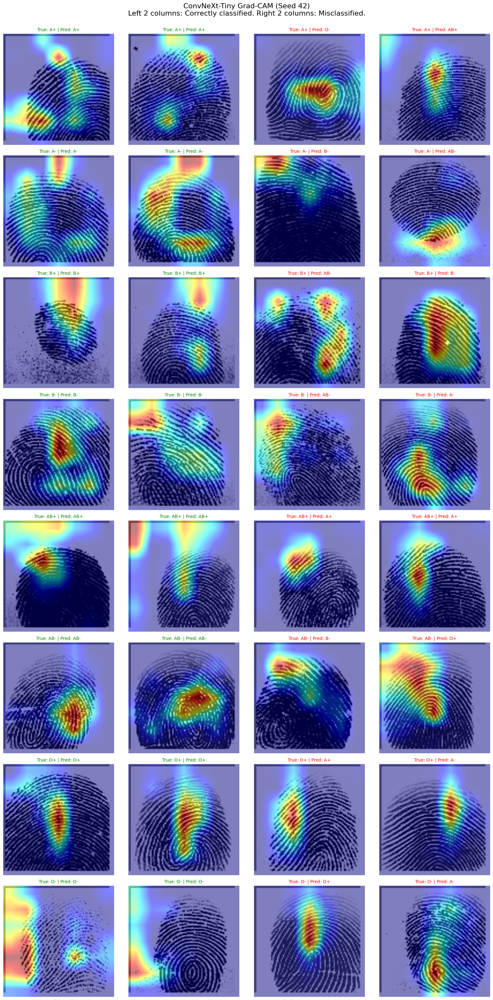

In [ ]:
# ===== STEP 38: X2 — Generate Grad-CAM Maps =====
!pip install grad-cam -q

import json, cv2, torch, torch.nn as nn, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from torchvision import models, transforms as T
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

P     = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
CLEAN = Path('/content/data/clean')
CK    = P/'outputs'/'checkpoints'
OUT   = P/'outputs'

l2i = json.load(open(P/'outputs/label_to_idx.json'))
idx_to_display = {v: k for k, v in l2i.items()} # Reverse map

# Load pre-registered selection
with open(OUT/'xai_image_selection.json', 'r') as f:
    selection = json.load(f)

# Load Model
dev = "cuda"
model = models.convnext_tiny(weights=None)
model.classifier[2] = nn.Linear(model.classifier[2].in_features, 8)
model.load_state_dict(torch.load(CK/'convnext_tiny_c1_seed42_best.pt', map_location=dev))
model = model.to(dev).eval()

# Target layer for ConvNeXt-Tiny
target_layers = [model.features[-1]]

# Preprocessing (same as evaluation)
preprocess = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

cam = GradCAM(model=model, target_layers=target_layers)

# Plot layout: 8 classes x 4 columns (2 correct, 2 incorrect) = 32 subplots
fig, axes = plt.subplots(8, 4, figsize=(16, 32))
fig.suptitle('ConvNeXt-Tiny Grad-CAM (Seed 42)\nLeft 2 columns: Correctly classified. Right 2 columns: Misclassified.', fontsize=16)

for row_idx, cls in enumerate(selection.keys()):
    # We will show 2 correct and 2 incorrect per class
    images_to_show = selection[cls]['correct'][:2] + selection[cls]['incorrect'][:2]

    for col_idx, img_path in enumerate(images_to_show):
        # Load image
        img_pil = Image.open(CLEAN/img_path).convert('RGB')
        img_tensor = preprocess(img_pil).unsqueeze(0).to(dev)

        # Get prediction
        with torch.no_grad():
            logits = model(img_tensor)
            pred_idx = logits.argmax(dim=1).item()
            pred_cls = idx_to_display[pred_idx]

        # Generate CAM for the PREDICTED class
        targets = [ClassifierOutputTarget(pred_idx)]
        grayscale_cam = cam(input_tensor=img_tensor, targets=targets)[0, :]

        # Resize original image to 224x224 for overlay
        img_resized = np.array(img_pil.resize((224, 224))) / 255.0
        visualization = show_cam_on_image(img_resized, grayscale_cam, use_rgb=True)

        # Plot
        ax = axes[row_idx, col_idx]
        ax.imshow(visualization)
        is_correct = (pred_cls == cls)
        title_color = 'green' if is_correct else 'red'
        ax.set_title(f"True: {cls} | Pred: {pred_cls}", color=title_color, fontsize=10)
        ax.axis('off')

plt.tight_layout()
plt.subplots_adjust(top=0.95)
save_path = OUT/'xai_gradcam_grid.png'
plt.savefig(save_path, dpi=150)
print(f"Saved Grad-CAM grid to {save_path}")

Saved sanity check grid to /content/drive/MyDrive/ML Fingerprint BloodGroup Project/outputs/xai_sanity_check.png

Mean Spearman correlation between Trained and Random CAMs: 0.2587
=== Pre-declared Reading Rule ===


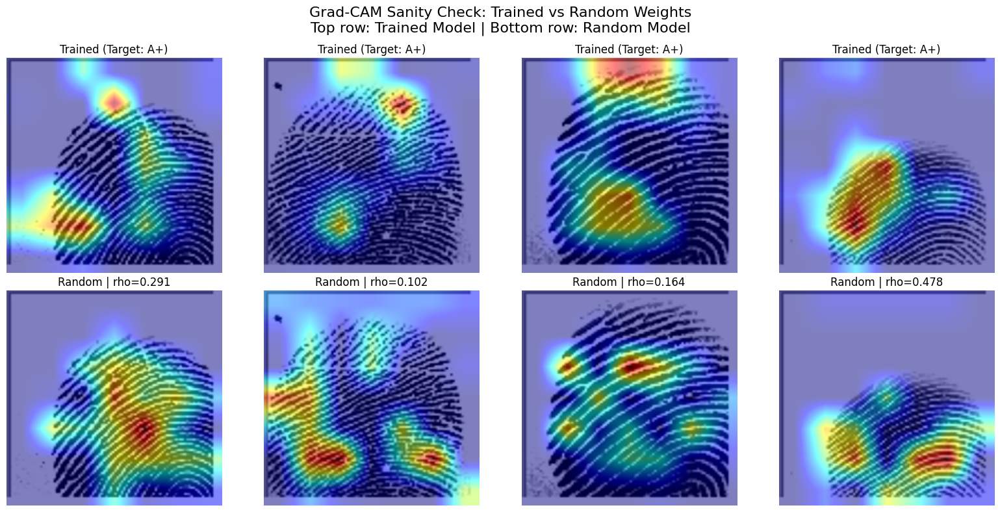

In [ ]:
# ===== STEP 39: X3 — Random Model Sanity Check =====
import json, cv2, torch, torch.nn as nn, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from torchvision import models, transforms as T
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image
from scipy.stats import spearmanr

P     = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
CLEAN = Path('/content/data/clean')
CK    = P/'outputs'/'checkpoints'
OUT   = P/'outputs'

l2i = json.load(open(P/'outputs/label_to_idx.json'))
idx_to_display = {v: k for k, v in l2i.items()}

with open(OUT/'xai_image_selection.json', 'r') as f:
    selection = json.load(f)

dev = "cuda"
# 1. Load TRAINED Model
trained_model = models.convnext_tiny(weights=None)
trained_model.classifier[2] = nn.Linear(trained_model.classifier[2].in_features, 8)
trained_model.load_state_dict(torch.load(CK/'convnext_tiny_c1_seed42_best.pt', map_location=dev))
trained_model = trained_model.to(dev).eval()

# 2. Load RANDOM Model (Untrained)
random_model = models.convnext_tiny(weights=None)
random_model.classifier[2] = nn.Linear(random_model.classifier[2].in_features, 8)
random_model = random_model.to(dev).eval()

preprocess = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

cam_trained = GradCAM(model=trained_model, target_layers=[trained_model.features[-1]])
cam_random  = GradCAM(model=random_model,  target_layers=[random_model.features[-1]])

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle('Grad-CAM Sanity Check: Trained vs Random Weights\nTop row: Trained Model | Bottom row: Random Model', fontsize=16)

# We will test on the first 4 "Correct" images of class A+
test_paths = selection['A+']['correct'][:4]
correlations = []

for col_idx, img_path in enumerate(test_paths):
    img_pil = Image.open(CLEAN/img_path).convert('RGB')
    img_tensor = preprocess(img_pil).unsqueeze(0).to(dev)
    img_resized = np.array(img_pil.resize((224, 224))) / 255.0

    # Get predicted class from TRAINED model to make it a fair target
    with torch.no_grad():
        logits = trained_model(img_tensor)
        pred_idx = logits.argmax(dim=1).item()
    targets = [ClassifierOutputTarget(pred_idx)]

    # Generate both CAMs
    gs_trained = cam_trained(input_tensor=img_tensor, targets=targets)[0, :]
    gs_random  = cam_random(input_tensor=img_tensor, targets=targets)[0, :]

    # Calculate Spearman rank correlation
    corr, _ = spearmanr(gs_trained.flatten(), gs_random.flatten())
    correlations.append(corr)

    # Visualize
    vis_trained = show_cam_on_image(img_resized, gs_trained, use_rgb=True)
    vis_random  = show_cam_on_image(img_resized, gs_random, use_rgb=True)

    axes[0, col_idx].imshow(vis_trained)
    axes[0, col_idx].set_title(f"Trained (Target: {idx_to_display[pred_idx]})")
    axes[0, col_idx].axis('off')

    axes[1, col_idx].imshow(vis_random)
    axes[1, col_idx].set_title(f"Random | rho={corr:.3f}")
    axes[1, col_idx].axis('off')

plt.tight_layout()
plt.subplots_adjust(top=0.88)
plt.savefig(OUT/'xai_sanity_check.png', dpi=150)
print(f"Saved sanity check grid to {OUT/'xai_sanity_check.png'}")

print(f"\nMean Spearman correlation between Trained and Random CAMs: {np.mean(correlations):.4f}")
print("=== Pre-declared Reading Rule ===")
if abs(np.mean(correlations)) < 0.2:
    print("PASS: Trained maps are clearly different from random (correlation near 0). The maps are informative.")
else:
    print("WARNING: Trained maps are similar to random. The maps may be uninformative.")

In [ ]:
# ===== STEP 40: X4 — Aggregate View (Border vs Center) =====
import json, torch, torch.nn as nn, numpy as np, pandas as pd
from pathlib import Path
from PIL import Image
from torchvision import models, transforms as T
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

P     = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project')
CLEAN = Path('/content/data/clean')
CK    = P/'outputs'/'checkpoints'
OUT   = P/'outputs'

l2i = json.load(open(P/'outputs/label_to_idx.json'))
idx_to_display = {v: k for k, v in l2i.items()}

with open(OUT/'xai_image_selection.json', 'r') as f:
    selection = json.load(f)

dev = "cuda"
model = models.convnext_tiny(weights=None)
model.classifier[2] = nn.Linear(model.classifier[2].in_features, 8)
model.load_state_dict(torch.load(CK/'convnext_tiny_c1_seed42_best.pt', map_location=dev))
model = model.to(dev).eval()

preprocess = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])
cam = GradCAM(model=model, target_layers=[model.features[-1]])

results = []

for cls in selection.keys():
    # Use all images (correct + incorrect) for this class
    paths = selection[cls]['correct'] + selection[cls]['incorrect']

    class_border, class_center = [], []

    for img_path in paths:
        img_pil = Image.open(CLEAN/img_path).convert('RGB')
        img_tensor = preprocess(img_pil).unsqueeze(0).to(dev)

        with torch.no_grad():
            logits = model(img_tensor)
            pred_idx = logits.argmax(dim=1).item()

        gs_cam = cam(input_tensor=img_tensor, targets=[ClassifierOutputTarget(pred_idx)])[0, :]

        # 224x224 CAM. Border = outer 20% (approx 45 pixels). Center = middle 60%.
        # Resize CAM to 224x224 just to be safe (it's usually 7x7)
        gs_cam_resized = np.array(Image.fromarray(gs_cam).resize((224, 224)))

        border_mask = np.ones_like(gs_cam_resized, dtype=bool)
        border_mask[45:-45, 45:-45] = False
        center_mask = ~border_mask

        total_intensity = gs_cam_resized.sum()
        if total_intensity == 0: continue

        border_share = gs_cam_resized[border_mask].sum() / total_intensity
        center_share = gs_cam_resized[center_mask].sum() / total_intensity

        class_border.append(border_share)
        class_center.append(center_share)

    results.append(dict(
        Class=cls,
        Border_Share=np.mean(class_border),
        Center_Share=np.mean(class_center),
        N=len(paths)
    ))

df = pd.DataFrame(results)
print("=== Aggregate CAM Intensity: Border vs Center ===")
print(df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

df.to_csv(OUT/'xai_border_vs_center.csv', index=False)
print(f"\nSaved aggregate CSV to {OUT/'xai_border_vs_center.csv'}")

=== Aggregate CAM Intensity: Border vs Center ===
Class  Border_Share  Center_Share  N
   A+        0.4016        0.5984  6
   A-        0.5843        0.4157  6
   B+        0.4557        0.5443  6
   B-        0.4099        0.5901  6
  AB+        0.5044        0.4956  6
  AB-        0.3068        0.6932  6
   O+        0.2343        0.7657  6
   O-        0.5741        0.4259  6

Saved aggregate CSV to /content/drive/MyDrive/ML Fingerprint BloodGroup Project/outputs/xai_border_vs_center.csv


In [ ]:
# ===== STEP 41: X6 — Verify XAI artifacts on Drive =====
from pathlib import Path

P = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project/outputs')

files_to_check = [
    'xai_image_selection.json',
    'xai_gradcam_grid.png',
    'xai_sanity_check.png',
    'xai_border_vs_center.csv'
]

print("=== XAI Artifact Verification ===")
for f in files_to_check:
    path = P/f
    if path.exists():
        print(f"[OK] {f} ({path.stat().st_size/1024:.1f} KB)")
    else:
        print(f"[MISSING] {f}")

=== XAI Artifact Verification ===
[OK] xai_image_selection.json (2.4 KB)
[OK] xai_gradcam_grid.png (7930.5 KB)
[OK] xai_sanity_check.png (1928.9 KB)
[OK] xai_border_vs_center.csv (0.2 KB)


In [ ]:
# ===== Recompute Section 7c for ConvNeXt-Tiny seed 42 =====
import json, numpy as np, pandas as pd
from pathlib import Path
from sklearn.metrics import classification_report, confusion_matrix, f1_score

P = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project/outputs')
l2i = json.load(open('/content/drive/MyDrive/ML Fingerprint BloodGroup Project/outputs/label_to_idx.json'))
DISPLAY_ORDER = ['A+','A-','B+','B-','AB+','AB-','O+','O-']
idx_to_display = {v: k for k, v in l2i.items()}

d = np.load(P/'phase7_convnext_tiny_seed42_val_preds.npz')
y_true = d['y_true_idx']
y_pred = d['y_pred_idx']

ys_str = np.array([idx_to_display[i] for i in y_true])
ps_str = np.array([idx_to_display[i] for i in y_pred])

print("=== Per-Class F1 ===")
report = classification_report(ys_str, ps_str, labels=DISPLAY_ORDER, output_dict=True, zero_division=0)
for cls in DISPLAY_ORDER:
    print(f"{cls:3s}: F1 = {report[cls]['f1-score']:.3f}")

print(f"\nMacro-F1: {f1_score(ys_str, ps_str, average='macro'):.4f}")

print("\n=== Top Confusions ===")
cm = confusion_matrix(ys_str, ps_str, labels=DISPLAY_ORDER)
cm_off = cm.copy(); np.fill_diagonal(cm_off, 0)
confs = [(DISPLAY_ORDER[i], DISPLAY_ORDER[j], int(cm_off[i,j])) for i in range(8) for j in range(8) if i != j and cm_off[i,j] > 0]
confs.sort(key=lambda t: -t[2])
for t, p, n in confs[:5]:
    print(f"{t} -> {p}: {n}")

=== Per-Class F1 ===
A+ : F1 = 0.933
A- : F1 = 0.913
B+ : F1 = 0.950
B- : F1 = 0.961
AB+: F1 = 0.920
AB-: F1 = 0.907
O+ : F1 = 0.909
O- : F1 = 0.895

Macro-F1: 0.9235

=== Top Confusions ===
A- -> O+: 7
O- -> AB-: 7
A- -> AB-: 6
O- -> O+: 4
B+ -> A-: 3


In [ ]:
# ===== Get ConvNeXt-Tiny Checksums =====
import hashlib
from pathlib import Path

CK = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project/outputs/checkpoints')
for s in [42, 43, 44]:
    ckpt = CK/f'convnext_tiny_c1_seed{s}_best.pt'
    h = hashlib.sha256()
    with open(ckpt, 'rb') as f:
        for chunk in iter(lambda: f.read(8192), b""): h.update(chunk)
    print(f"Seed {s}: {h.hexdigest()}")

Seed 42: 2fbd940ffe014ed6fe9e249f3045fc67389d40ae8dc818ad76ee9717304cb715
Seed 43: fd7429f71e051237ec2ce25f317c350e9b43469ccc430b3f960dec9349b69c51
Seed 44: beeab8cb921764c81a3ba88faeb20125e44a1b6046e4684fad73c039645dfc9f


Saved: phase8d_convnext_reliability.png


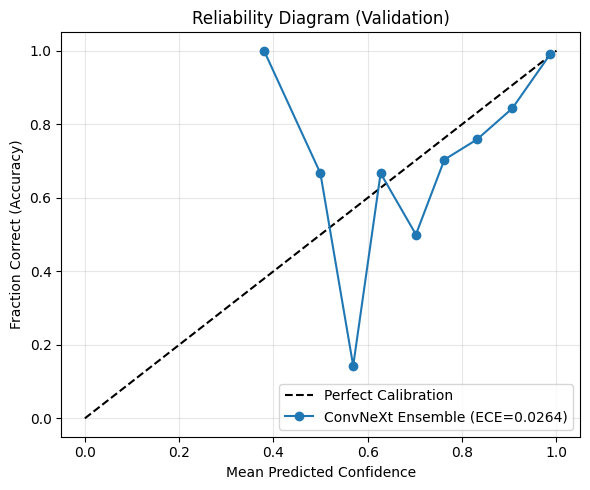

In [ ]:
# ===== Generate ConvNeXt Reliability Plot (for the report) =====
import json, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import accuracy_score

P = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project/outputs')
l2i = json.load(open('/content/drive/MyDrive/ML Fingerprint BloodGroup Project/outputs/label_to_idx.json'))

# Load the calibrated ensemble probs we saved in Step 35
d = np.load(P/'phase8d_ensemble_convnext_tiny_val.npz')
probs_cal = d['probs_cal']
y_true = d['y_true']

def reliability_bins(probs, y, n_bins=15):
    conf = probs.max(axis=1)
    pred = probs.argmax(axis=1)
    acc = (pred == y).astype(float)
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    cs, as_ = [], []
    for i in range(n_bins):
        lo, hi = bins[i], bins[i+1]
        mask = (conf >= lo) & (conf < hi if i < n_bins-1 else conf <= hi)
        if mask.sum() == 0: continue
        cs.append(conf[mask].mean())
        as_.append(acc[mask].mean())
    return np.array(cs), np.array(as_)

cs, as_ = reliability_bins(probs_cal, y_true)
plt.figure(figsize=(6, 5))
plt.plot([0, 1], [0, 1], 'k--', label='Perfect Calibration')
plt.plot(cs, as_, 'o-', label=f'ConvNeXt Ensemble (ECE=0.0264)')
plt.xlabel('Mean Predicted Confidence')
plt.ylabel('Fraction Correct (Accuracy)')
plt.title('Reliability Diagram (Validation)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(P/'phase8d_convnext_reliability.png', dpi=150)
print("Saved: phase8d_convnext_reliability.png")

In [ ]:
import json, numpy as np
from pathlib import Path
from sklearn.metrics import classification_report

P = Path('/content/drive/MyDrive/ML Fingerprint BloodGroup Project/outputs')
l2i = json.load(open('/content/drive/MyDrive/ML Fingerprint BloodGroup Project/outputs/label_to_idx.json'))
DISPLAY_ORDER = ['A+','A-','B+','B-','AB+','AB-','O+','O-']
idx_to_display = {v: k for k, v in l2i.items()}

d = np.load(P/'phase7_convnext_tiny_seed42_val_preds.npz')
ys_str = np.array([idx_to_display[i] for i in d['y_true_idx']])
ps_str = np.array([idx_to_display[i] for i in d['y_pred_idx']])

report = classification_report(ys_str, ps_str, labels=DISPLAY_ORDER, output_dict=True, zero_division=0)

print(f"| {'Class':5s} | {'Precision':9s} | {'Recall':9s} | {'F1-Score':9s} | {'Support':7s} |")
print("| :--- | :--- | :--- | :--- | :--- |")
for cls in DISPLAY_ORDER:
    p = report[cls]['precision']
    r = report[cls]['recall']
    f = report[cls]['f1-score']
    s = int(report[cls]['support'])
    print(f"| {cls:5s} | {p:.4f} | {r:.4f} | {f:.4f} | {s:7d} |")
print(f"| **Macro Avg** | {report['macro avg']['precision']:.4f} | {report['macro avg']['recall']:.4f} | **{report['macro avg']['f1-score']:.4f}** | {len(ys_str)} |")

| Class | Precision | Recall    | F1-Score  | Support |
| :--- | :--- | :--- | :--- | :--- |
| A+    | 0.9180 | 0.9492 | 0.9333 |      59 |
| A-    | 0.9357 | 0.8912 | 0.9129 |     147 |
| B+    | 0.9770 | 0.9239 | 0.9497 |      92 |
| B-    | 0.9515 | 0.9703 | 0.9608 |     101 |
| AB+   | 0.9200 | 0.9200 | 0.9200 |     100 |
| AB-   | 0.8729 | 0.9450 | 0.9075 |     109 |
| O+    | 0.8846 | 0.9350 | 0.9091 |     123 |
| O-    | 0.9341 | 0.8586 | 0.8947 |      99 |
| **Macro Avg** | 0.9242 | 0.9241 | **0.9235** | 830 |
